Applied Data Science and Machine Learning
A program by IIT Madras and TalentSprint
Capstone Project : Optic-Disc-Cup Segmentation and Classification

Introduction



Glaucoma is a major cause of irreversible vision loss. Millions of people around the world suffer from glaucoma. The Drishti-GS dataset used in this project is widely used for gloucoma screening research and provides expert marked ptic disc and cup boundaries. The project wishes to build a reusable screening pipeline that enables standardized analysis of fundus images, supports consistent prioritization of potentially cases of glaucoma for further ophthalmic evaluation & gives a base for research into automated & clinically relevant retinal image analysis.


Analysis of Optic-Disk-Cup Segmentation and Classification

Glaucoma is a major cause of irreversible vision loss. Millions of people around the world suffer from glaucoma. Our healthcare professionals work very hard to take care of the people suffering from glaucoma and offer them a proper care for their own health and benefit. But manual assessment of retinal fundus images, particularly the optic disc and optic cup, can be time-consuming. There are people on whom clinical treatments could have been started earlier if clinical intervention has been done in time. Early screening is essential for timely clinical intervention.

This project proposes a deep learning–based computer vision framework for automated glaucoma screening by fundus images. The proposed system will employ the framework on the Drishti-GS dataset given by the researchers at the CVIT Lab of  International Institute of Information Technology, Hyderabad (IIIT Hyderabad) in collaboration with Aravind Eye Hospital, Madurai. The dataset has fundus images with expert optic disk-cup annotations & glaucoma-related labels.

This dataset will be used for model development and evaluation. The proposed system will be deploying image preprocessing followed by segmentation to identify the optic disc and optic cup & then classify to find the probability of the presence of glaucoma. Segmentation performance will be assessed using Dice and Intersection over Union (IoU), while classification will be evaluated using accuracy, sensitivity, specificity, F1-score & ROC-AUC. The project wishes to build a reusable screening pipeline that enables standardized analysis of fundus images, supports consistent prioritization of potentially cases of glaucoma for further ophthalmic evaluation & gives a base for research into automated & clinically relevant retinal image analysis.

We have decided to apply 3 segmentation models to figure  it out which one of them gives the best performance. Similarly, we will use 3 classifiers to find which one of them gives the best perfomance.
At the end we will save the best model.

The 3 segmentation models that we will use are:
a)UNet
b)UNet++
c)Attention UNet.

The 3 classification models that will be used are:
a)Logistic regression
b)Resnet18
c)Shufflenetv2



We will be having a short look at them later but at first let's start.

In [ ]:
from tensorflow import keras
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.callbacks import EarlyStopping
from google.colab import files
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [ ]:
import os
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import imutils
import time
import datetime
import random
import sys
import pandas as pd

In [ ]:
# Install unrar if not already installed
!apt-get update -qq > /dev/null
!apt-get install -qq unrar > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
uploaded = files.upload()

Saving Drishti-GS1_files.rar to Drishti-GS1_files.rar


In [ ]:
!rm -rf /content/DrishtiGS_dataset
!mkdir -p /content/DrishtiGS_dataset
!unrar x -o Drishti-GS1_files.rar /content/DrishtiGS_dataset


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from Drishti-GS1_files.rar

Creating    /content/DrishtiGS_dataset/Drishti-GS1_files              OK
Extracting  /content/DrishtiGS_dataset/Drishti-GS1_files/notching_image_decisions.xls       0%  OK 
Extracting  /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_diagnosis.xlsx       0%  OK 
Creating    /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files  OK
Creating    /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Test  OK
Creating    /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Test/Images  OK
Extracting  /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Test/Images/drishtiGS_023.png       0%  OK 
Extracting  /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Test/Images/drishtiGS_093.png       0%  1%  OK 
Extracting  /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Test/Image

In [ ]:
print(f"The actual uploaded file is: {list(uploaded.keys())[0]}")
print("Listing contents of Drishti-GS1_files.rar:")
!unrar l Drishti-GS1_files.rar

The actual uploaded file is: Drishti-GS1_files.rar
Listing contents of Drishti-GS1_files.rar:

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal

Archive: Drishti-GS1_files.rar
Details: RAR 4

 Attributes      Size     Date    Time   Name
----------- ---------  ---------- -----  ----
 -rw-rw-r--     11264  2015-09-27 20:57  Drishti-GS1_files/notching_image_decisions.xls
 -rw-r--r--      9559  2017-03-13 11:05  Drishti-GS1_files/Drishti-GS1_diagnosis.xlsx
 -rw-rw-r--   3448463  2013-10-06 09:51  Drishti-GS1_files/Drishti-GS1_files/Test/Images/drishtiGS_023.png
 -rw-rw-r--   3356488  2013-10-06 09:51  Drishti-GS1_files/Drishti-GS1_files/Test/Images/drishtiGS_093.png
 -rw-rw-r--   3328233  2013-10-06 09:51  Drishti-GS1_files/Drishti-GS1_files/Test/Images/drishtiGS_021.png
 -rw-rw-r--   3425107  2013-10-06 09:51  Drishti-GS1_files/Drishti-GS1_files/Test/Images/drishtiGS_078.png
 -rw-rw-r--   3445803  2013-10-06 09:51  Drishti-GS1_files/Drishti-GS1_files/Test/Images/drishtiG

In [ ]:
from pathlib import Path

# Change this path according to your system
DATASET_ROOT = Path("/content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files")

TRAIN_DIR = DATASET_ROOT / "Training"

IMAGE_DIR = TRAIN_DIR / "Images"
GT_DIR = TRAIN_DIR / "GT"

EXCEL_FILE = "/content/DrishtiGS_dataset/Drishti-GS1_files/notching_image_decisions.xls"

print("Dataset root :", DATASET_ROOT)
print("Training dir :", TRAIN_DIR)
print("Image dir    :", IMAGE_DIR)
print("GT dir       :", GT_DIR)
print("Excel file   :", EXCEL_FILE)

image_files = list(IMAGE_DIR.iterdir())

print("Number of items in Images:", len(image_files))

for file in image_files[:10]:
    print(file.name)

Dataset root : /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files
Training dir : /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Training
Image dir    : /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Training/Images
GT dir       : /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Training/GT
Excel file   : /content/DrishtiGS_dataset/Drishti-GS1_files/notching_image_decisions.xls
Number of items in Images: 50
drishtiGS_024.png
drishtiGS_017.png
drishtiGS_064.png
drishtiGS_062.png
drishtiGS_066.png
drishtiGS_080.png
drishtiGS_094.png
drishtiGS_026.png
drishtiGS_010.png
drishtiGS_088.png


In [ ]:
rar_file_name = list(uploaded.keys())[0]
rar_file_name

'Drishti-GS1_files.rar'

In [ ]:
dt = pd.read_excel(EXCEL_FILE)
print("Excel Columns:", dt.columns)
dt

Excel Columns: Index(['IMAGE NUMBER', 'Unnamed: 1', 'Notching direction(I/S/N/T/Absent)'], dtype='object')


,IMAGE NUMBER,Unnamed: 1,Notching direction(I/S/N/T/Absent)
0,1,NaN,I
1,2,NaN,I
2,3,NaN,I
3,4,NaN,I
4,5,NaN,I
...,...,...,...
96,97,NaN,A
97,98,NaN,A
98,99,NaN,A
99,100,NaN,A


In [ ]:
gt_files = list(GT_DIR.iterdir())
print(f"Total Images: {len(image_files)} | Total GT folders/files: {len(gt_files)}")

Total Images: 50 | Total GT folders/files: 51


In [ ]:
sample_img = image_files[0].stem
print(f"\nChecking alignment for sample base name: {sample_img}")
sample_gt_paths = [p for p in GT_DIR.glob(f"*{sample_img}*")]
for p in sample_gt_paths:
    print("Found GT asset:", p.name)


Checking alignment for sample base name: drishtiGS_024
Found GT asset: drishtiGS_024


In [ ]:
status_column = 'Notching direction(I/S/N/T/Absent)'

print("Class Distribution:")
print(dt[status_column].value_counts())

print("\nMissing values in labels:")
print(dt[status_column].isna().sum())

Class Distribution:
Notching direction(I/S/N/T/Absent)
A          56
I          36
S           7
I and S     2
Name: count, dtype: int64

Missing values in labels:
0


In [ ]:
import cv2
from collections import Counter

shapes = []
for img_path in image_files:
    # Read using OpenCV (or PIL)
    img = cv2.imread(str(img_path))
    shapes.append(img.shape)

shape_counts = Counter(shapes)
print("Image dimensions distribution (Height, Width, Channels):")
for shape, count in shape_counts.items():
    print(f"Shape {shape}: {count} images")


Image dimensions distribution (Height, Width, Channels):
Shape (1757, 2047, 3): 2 images
Shape (1750, 2049, 3): 2 images
Shape (1752, 2047, 3): 1 images
Shape (1755, 2047, 3): 2 images
Shape (1760, 2048, 3): 2 images
Shape (1754, 2046, 3): 2 images
Shape (1763, 2047, 3): 1 images
Shape (1757, 2140, 3): 1 images
Shape (1760, 2047, 3): 1 images
Shape (1749, 2049, 3): 3 images
Shape (1759, 2048, 3): 2 images
Shape (1753, 2046, 3): 2 images
Shape (1755, 2049, 3): 2 images
Shape (1759, 2049, 3): 3 images
Shape (1750, 2050, 3): 1 images
Shape (1750, 2048, 3): 2 images
Shape (1763, 2049, 3): 1 images
Shape (1751, 2045, 3): 1 images
Shape (1751, 2052, 3): 1 images
Shape (1753, 2048, 3): 2 images
Shape (1760, 2051, 3): 1 images
Shape (1760, 2049, 3): 1 images
Shape (1749, 2048, 3): 3 images
Shape (1758, 2050, 3): 1 images
Shape (1762, 2049, 3): 2 images
Shape (1845, 2050, 3): 1 images
Shape (1762, 2468, 3): 1 images
Shape (1749, 2050, 3): 1 images
Shape (1752, 2045, 3): 1 images
Shape (1763, 24

Visualizing drishtiGS_024


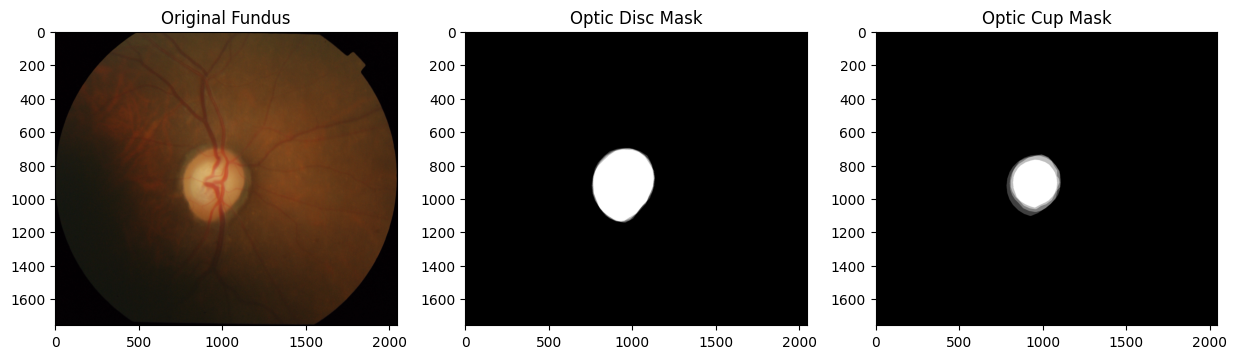

Visualizing drishtiGS_094


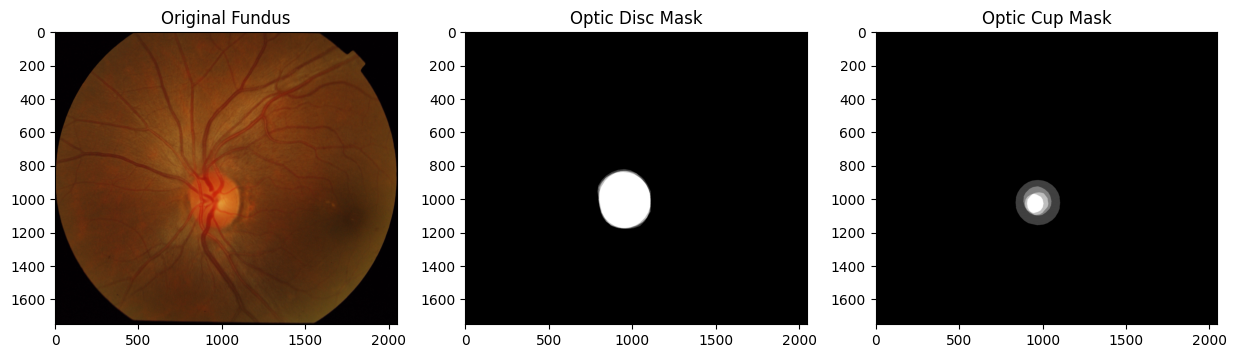

In [ ]:
def plot_sample(image_path, gt_dir):
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    base_name = image_path.stem

    # GT is inside a subfolder named after the image
    # containing soft maps or binary masks for Cup and Disk.
    sample_gt_dir = gt_dir / base_name / "SoftMap"

    print(f"Visualizing {base_name}")
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img)
    axes[0].set_title("Original Fundus")

    # Try to locate Disc and Cup files if they exist
    try:
        #print(f"Visualizing {str(sample_gt_dir / f"{base_name}_ODsegSoftmap.png")}")
        disc_mask = cv2.imread(str(sample_gt_dir / f"{base_name}_ODsegSoftmap.png"), 0)
        axes[1].imshow(disc_mask, cmap='gray')
        axes[1].set_title("Optic Disc Mask")
    except Exception as e:
        axes[1].text(0.5, 0.5, 'Disc Mask Not Found', ha='center')

    try:
        cup_mask = cv2.imread(str(sample_gt_dir / f"{base_name}_cupsegSoftmap.png"), 0)
        axes[2].imshow(cup_mask, cmap='gray')
        axes[2].set_title("Optic Cup Mask")
    except Exception as e:
        axes[2].text(0.5, 0.5, 'Cup Mask Not Found', ha='center')

    plt.show()

# Plot a few items
plot_sample(image_files[0], GT_DIR)
plot_sample(image_files[6], GT_DIR)

In [ ]:
channel_means = { 'R': [], 'G': [], 'B': [] }

for img_path in image_files[:20]: # Sample 20 images for speed
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    channel_means['R'].append(np.mean(img[:,:,0]))
    channel_means['G'].append(np.mean(img[:,:,1]))
    channel_means['B'].append(np.mean(img[:,:,2]))

r_mean, g_mean, b_mean = np.mean(channel_means['R']), np.mean(channel_means['G']), np.mean(channel_means['B'])

print("Average intensity per channel across sample:")
print(f"Red channel mean: {r_mean:.2f}")
print(f"Green channel mean: {g_mean:.2f}")
print(f"Blue channel mean: {b_mean:.2f}")
# Note: The Green channel typically provides the highest contrast for blood vessels and cup boundaries!

# --- SIMPLE DATA VALIDATION CHECK ---
# Checks if the image has normal fundus color hierarchy and isn't completely pitch black (< 10 intensity)
if r_mean > g_mean > b_mean and r_mean > 10:
    print("\n Data check passed: Channel hierarchy looks as expected for retinal fundus images.")
else:
    print("\n Data issue suspected: Check if images are corrupted, overly dark, or missing color profile transitions.")


Average intensity per channel across sample:
Red channel mean: 83.77
Green channel mean: 39.75
Blue channel mean: 11.62

 Data check passed: Channel hierarchy looks as expected for retinal fundus images.


In [ ]:
def resize_image_and_mask(image, mask, target_size=(512, 512)):
    image = cv2.resize(
        image,
        target_size,
        interpolation=cv2.INTER_AREA
    )

    mask = cv2.resize(
        mask,
        target_size,
        interpolation=cv2.INTER_NEAREST
    )

    return image, mask

In [ ]:
!pip install segmentation-models-pytorch


In [ ]:
import torch, numpy as np, random, os
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as T
from sklearn.model_selection import train_test_split
import cv2
from pathlib import Path

seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
np.random.seed(seed)
random.seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
os.environ["PYTHONHASHSEED"] = str(seed)

# --- Dependencies from previous cells to make this cell runnable independently ---
DATASET_ROOT = Path("/content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files")
TRAIN_DIR = DATASET_ROOT / "Training"
IMAGE_DIR = TRAIN_DIR / "Images"
GT_DIR = TRAIN_DIR / "GT"
image_files = list(IMAGE_DIR.iterdir())

In [ ]:
class DrishtiSegmentationDataset(Dataset):
    def __init__(self, base_dir, split="Training", transform=None, image_paths=None):
        self.split_dir = Path(base_dir) / split
        self.images_dir = self.split_dir / "Images"

        self.gt_dir = (
            self.split_dir / "GT"
            if split == "Training"
            else self.split_dir / "Test_GT"
        )

        if image_paths is not None:
            self.image_paths = sorted(image_paths)
        else:
            self.image_paths = sorted(
                list(self.images_dir.glob("*.png"))
            )

        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img_id = img_path.stem

        softmap_dir = self.gt_dir / img_id / "SoftMap"

        disc_path = softmap_dir / f"{img_id}_ODsegSoftmap.png"
        cup_path = softmap_dir / f"{img_id}_cupsegSoftmap.png"

        # Load image
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Load masks
        disc_mask = cv2.imread(
            str(disc_path),
            cv2.IMREAD_GRAYSCALE
        )

        cup_mask = cv2.imread(
            str(cup_path),
            cv2.IMREAD_GRAYSCALE
        )

        # Resize
        img = cv2.resize(
            img,
            (512, 512),
            interpolation=cv2.INTER_AREA
        )

        disc_mask = cv2.resize(
            disc_mask,
            (512, 512),
            interpolation=cv2.INTER_NEAREST
        )

        cup_mask = cv2.resize(
            cup_mask,
            (512, 512),
            interpolation=cv2.INTER_NEAREST
        )

        # Binarize masks
        disc_mask = (disc_mask > 127).astype(np.float32)
        cup_mask = (cup_mask > 127).astype(np.float32)

        # Synchronized horizontal flip
        if self.transform:
            if random.random() < 0.5:
                img = np.fliplr(img).copy()
                disc_mask = np.fliplr(disc_mask).copy()
                cup_mask = np.fliplr(cup_mask).copy()

        # Normalize image
                # Convert to tensors FIRST (Clean, standard contiguous memory layout)
        img_tensor = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
        disc_tensor = torch.tensor(disc_mask, dtype=torch.float32)
        cup_tensor = torch.tensor(cup_mask, dtype=torch.float32)
        masks_tensor = torch.stack([disc_tensor, cup_tensor], dim=0)

        # Synchronized horizontal flip handled natively inside PyTorch
        if self.transform:
            if random.random() < 0.5:
                img_tensor = transforms.functional.hflip(img_tensor)
                masks_tensor = transforms.functional.hflip(masks_tensor)

        return img_tensor, masks_tensor

What is U-Net?
U-Net is a kind of neural network mainly used for image segmentation which means dividing an image into different parts to identify specific objects for example separating a tumor from healthy tissue in a medical scan. The name “U-Net” comes from the shape of its architecture which looks like the letter “U” when drawn. It is widely used in medical imaging because it performs well even with a small amount of labeled data.

The U-Net architecture was first introduced and published on May 18, 2015 (via arXiv), and formally presented at the MICCAI 2015 conference on November 18, 2015, by Olaf Ronneberger, Philipp Fischer, and Thomas Brox.


Key Architecture

• U-Shaped Design: Features a symmetric structure with an encoder on the left and a decoder on the right.
• Contracting Path (Encoder): Captures the context of the image by repeatedly applying convolutions and max-pooling, cutting spatial dimensions while doubling feature channels.
• Expanding Path (Decoder): Reconstructs the image to full resolution using transposed convolutions and upsampling.
• Skip Connections: Directly links feature maps from the encoder to the decoder to preserve fine-grained spatial details.


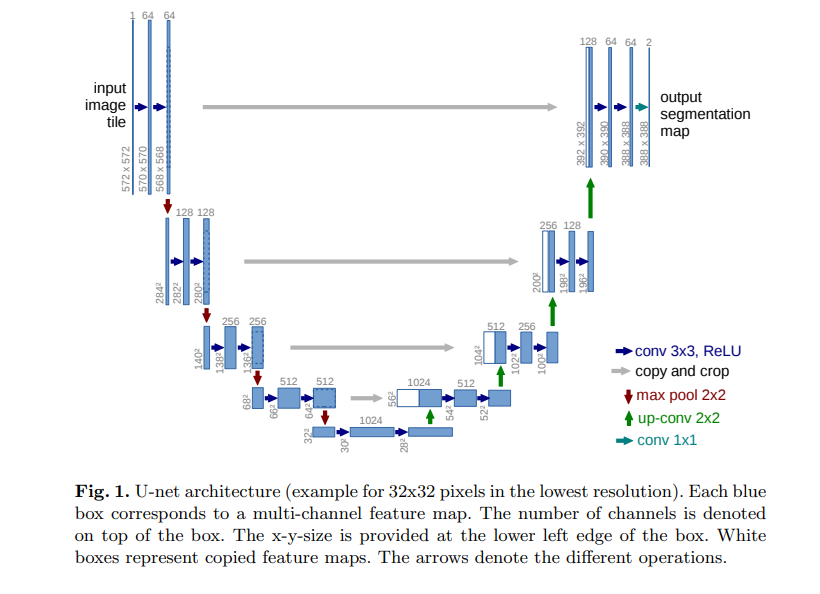



In [ ]:
import segmentation_models_pytorch as smp
import torch

# Define device before use
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize U-Net model structure
unet = smp.Unet(
    encoder_name="resnet34",        # Encoder - Using resnet34 for the feature extraction
    encoder_weights="imagenet",     # imagenet - for transferlearning, ResNet-34 encoder is initialized with weights pre-trained on ImageNet
    in_channels=3,                  # 3 channels - Specifies that the model expects input images with 3 color channels, which corresponds to standard RGB
    classes=2                       # Defines the number of output channels - value of 2 indicates the network will output two separate prediction maps—one for the Optic Disc (OD) boundaries and one for the Optic Cup (OC) boundaries
).to(device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
import torch

# find GPU availability for processing and inizialize UNet++ with device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print (f"supported device: {device}")
unet = unet.to(device)

supported device: cuda


In [ ]:
# Training dataset
train_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Training",
    transform=True
)

# Official test dataset
test_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Test",
    transform=False
)

print("Train Dataset Len:", len(train_dataset))
print("Test Dataset Len:", len(test_dataset))

Train Dataset Len: 50
Test Dataset Len: 51


In [ ]:
from sklearn.model_selection import train_test_split

# Get the 50 official training images
all_train_paths = sorted(
    (DATASET_ROOT / "Training" / "Images").glob("*.png")
)

# 80% training / 20% validation
train_paths, val_paths = train_test_split(
    all_train_paths,
    test_size=0.20,
    random_state=42
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 40
Validation images: 10


In [ ]:
train_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Training",
    transform=True,
    image_paths=train_paths
)

val_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Training",
    transform=False,
    image_paths=val_paths
)

test_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Test",
    transform=False
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 40
Validation dataset: 10
Test dataset: 51


In [ ]:
import torch.nn as nn

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred_logits, targets, smooth=1e-5):
        # Base BCE tracking
        bce_loss = self.bce(pred_logits, targets)

        # Compute multi-channel Dice Coefficient
        pred_probs = torch.sigmoid(pred_logits)
        intersection = (pred_probs * targets).sum(dim=(2, 3))
        union = pred_probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))

        dice_loss = 1 - ((2. * intersection + smooth) / (union + smooth)).mean()

        # Return compound loss balance
        return bce_loss + dice_loss


In [ ]:
criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(unet.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

In [ ]:
def dice_coeff(pred, target, smooth=1e-5):
    pred = torch.sigmoid(pred) > 0.5
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum()
    return (2. * intersection + smooth) / (union + smooth)

def iou_score(pred, target, smooth=1e-5):
    pred = torch.sigmoid(pred) > 0.5
    intersection = (pred & target).sum()
    union = (pred | target).sum()
    return (intersection + smooth) / (union + smooth)

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=True)

val_loader = DataLoader(val_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=False)

test_loader = DataLoader(test_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=False)

In [ ]:
import torchvision.transforms as transforms

def compute_cdr(disc_mask, cup_mask):
    # Calculate Cup-to-Disc Ratio
    disc_area = (disc_mask > 0.5).sum()
    cup_area = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

def safe_iou_score(pred, target, smooth=1e-5):
    # Convert predictions and targets to boolean masks
    pred_bool = torch.sigmoid(pred) > 0.5
    target_bool = target > 0.5
    intersection = (pred_bool & target_bool).sum()
    union = (pred_bool | target_bool).sum()
    return (intersection.float() + smooth) / (union.float() + smooth)

# --- NEW: INITIALIZE METRIC HISTORY CONTAINERS ---
history = {
    'train_loss': [], 'val_loss': [], 'val_dice': [],
    'val_iou': [], 'sensitivity': [], 'specificity': [], 'accuracy': []
}

print("Initiating U-Net Training and Diagnostic Tracking Loop...\n")

for epoch in range(10):
    # =========================
    # Training
    # =========================
    unet.train()
    running_train_loss = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = unet(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    # =========================
    # Validation
    # =========================
    unet.eval()
    running_val_loss = 0.0
    val_dice_accum = 0.0
    val_iou_accum = 0.0

    cdr_values = []
    gt_values = []

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            outputs = unet(imgs)
            loss = criterion(outputs, masks)

            running_val_loss += loss.item()
            val_dice_accum += dice_coeff(outputs, masks).item()
            val_iou_accum += safe_iou_score(outputs, masks).item()

            # =========================
            # CDR diagnostic evaluation
            # =========================
            disc_pred = outputs[:, 0, :, :]
            cup_pred = outputs[:, 1, :, :]
            disc_gt = masks[:, 0, :, :]
            cup_gt = masks[:, 1, :, :]

            for i in range(imgs.size(0)):
                pred_cdr = compute_cdr(disc_pred[i], cup_pred[i])
                gt_cdr = compute_cdr(disc_gt[i], cup_gt[i])

                cdr_values.append(pred_cdr.item() if torch.is_tensor(pred_cdr) else float(pred_cdr))
                gt_values.append(gt_cdr.item() if torch.is_tensor(gt_cdr) else float(gt_cdr))

    # Average losses and scores safely per epoch
    epoch_train_loss = running_train_loss / len(train_loader)
    epoch_val_loss = running_val_loss / len(val_loader)
    epoch_val_dice = val_dice_accum / len(val_loader)
    epoch_val_iou = val_iou_accum / len(val_loader)

    # Update learning-rate scheduler using validation loss
    scheduler.step(epoch_val_loss)

    # =========================
    # CDR Diagnostic Metrics
    # =========================
    pred_suspicious = torch.tensor(cdr_values) >= 0.6
    gt_suspicious = torch.tensor(gt_values) >= 0.6

    tp = ((pred_suspicious == 1) & (gt_suspicious == 1)).sum().item()
    tn = ((pred_suspicious == 0) & (gt_suspicious == 0)).sum().item()
    fp = ((pred_suspicious == 1) & (gt_suspicious == 0)).sum().item()
    fn = ((pred_suspicious == 0) & (gt_suspicious == 1)).sum().item()

    sensitivity = tp / (tp + fn + 1e-6)
    specificity = tn / (tn + fp + 1e-6)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-6)

    # --- NEW: CACHE DATA INTO HISTORY FOR PLOTTING ---
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['val_dice'].append(epoch_val_dice)
    history['val_iou'].append(epoch_val_iou)
    history['sensitivity'].append(sensitivity)
    history['specificity'].append(specificity)
    history['accuracy'].append(accuracy)

    print(
        f"Epoch {epoch + 1}/10: "
        f"Train Loss={epoch_train_loss:.4f}, "
        f"Val Loss={epoch_val_loss:.4f} | "
        f"Val Dice={epoch_val_dice:.4f}, "
        f"Val IoU={epoch_val_iou:.4f} | "
        f"Sens={sensitivity:.4f}, "
        f"Spec={specificity:.4f}, "
        f"Acc={accuracy:.4f}"
    )

Initiating U-Net Training and Diagnostic Tracking Loop...

Epoch 1/10: Train Loss=1.7446, Val Loss=2.1578 | Val Dice=0.0611, Val IoU=0.0315 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 2/10: Train Loss=1.5776, Val Loss=1.8038 | Val Dice=0.0797, Val IoU=0.0415 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 3/10: Train Loss=1.4788, Val Loss=1.6176 | Val Dice=0.1104, Val IoU=0.0584 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 4/10: Train Loss=1.4013, Val Loss=1.5263 | Val Dice=0.1759, Val IoU=0.0965 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 5/10: Train Loss=1.3318, Val Loss=1.3902 | Val Dice=0.3135, Val IoU=0.1861 | Sens=0.0000, Spec=0.5714, Acc=0.4000
Epoch 6/10: Train Loss=1.2868, Val Loss=1.3122 | Val Dice=0.5702, Val IoU=0.3995 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 7/10: Train Loss=1.2527, Val Loss=1.2548 | Val Dice=0.7149, Val IoU=0.5575 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 8/10: Train Loss=1.2265, Val Loss=1.2155 | Val Dice=0.7781, Val IoU=0.6382 | Sens=1.0000, Spec=

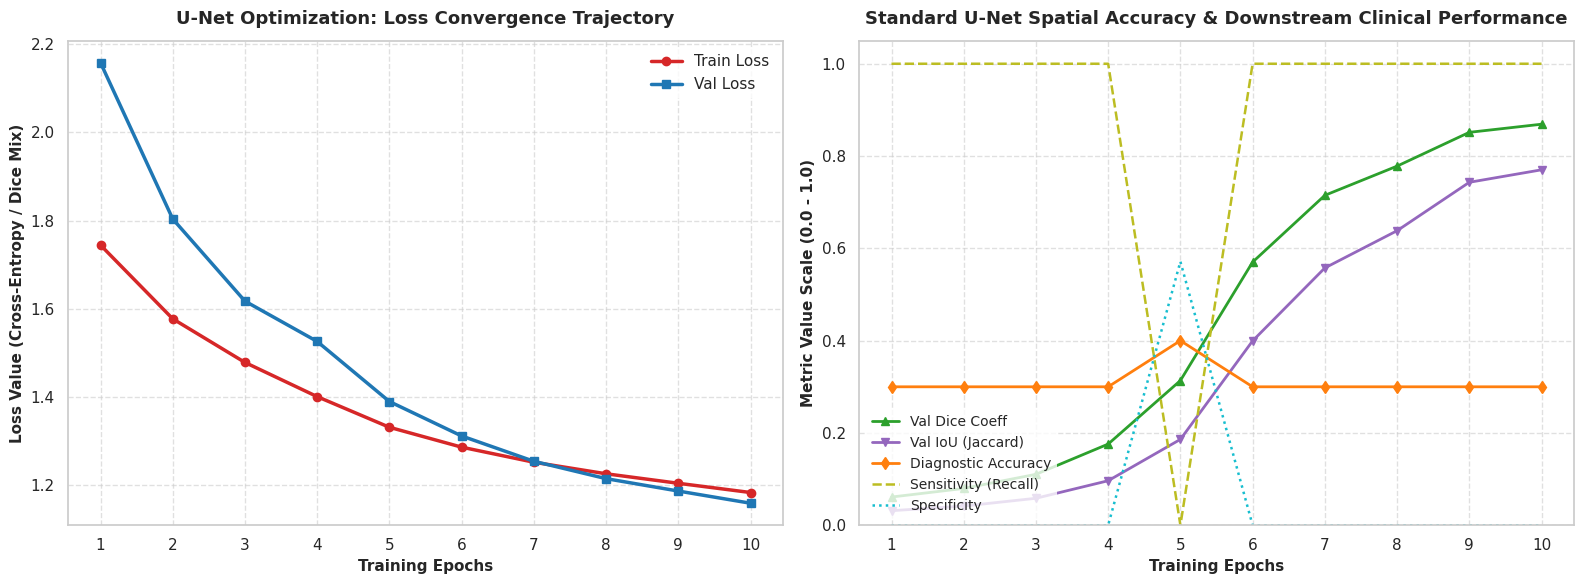

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CONFIGURE THEME & VISUAL CANVAS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
epochs_range = np.arange(1, 11)

try:
    # 1. Left Subplot: Loss Trajectories (Error Optimization convergence)
    axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', color='#d62728', lw=2.5, marker='o')
    axes[0].plot(epochs_range, history['val_loss'], label='Val Loss', color='#1f77b4', lw=2.5, marker='s')
    axes[0].set_title('U-Net Optimization: Loss Convergence Trajectory', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Loss Value (Cross-Entropy / Dice Mix)', fontsize=11, fontweight='bold')
    axes[0].set_xticks(epochs_range)
    axes[0].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Right Subplot: Spatial Overlap & Clinical Diagnostic Performance Curves
    axes[1].plot(epochs_range, history['val_dice'], label='Val Dice Coeff', color='#2ca02c', lw=2, marker='^')
    axes[1].plot(epochs_range, history['val_iou'], label='Val IoU (Jaccard)', color='#9467bd', lw=2, marker='v')
    axes[1].plot(epochs_range, history['accuracy'], label='Diagnostic Accuracy', color='#ff7f0e', lw=2, marker='d')
    axes[1].plot(epochs_range, history['sensitivity'], label='Sensitivity (Recall)', color='#bcbd22', lw=1.8, linestyle='--')
    axes[1].plot(epochs_range, history['specificity'], label='Specificity', color='#17becf', lw=1.8, linestyle=':')

    axes[1].set_title('Standard U-Net Spatial Accuracy & Downstream Clinical Performance', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Metric Value Scale (0.0 - 1.0)', fontsize=11, fontweight='bold')
    axes[1].set_xticks(epochs_range)

    # Restrict standard metric limits to prevent edge line truncation clipping
    axes[1].set_ylim(0.0, 1.05)
    axes[1].legend(loc='lower left', frameon=True, facecolor='white', edgecolor='none', fontsize=10)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

except NameError:
    raise NameError("Please execute the U-Net training cell block first to populate the 'history' dictionary.")

In [ ]:
# Create a directory in your drive and save the weights
UNET_SAVE_PATH = DATASET_ROOT / "Drishti_UNetPlusPlus_Glaucoma.pth"
torch.save(unet.state_dict(), UNET_SAVE_PATH)
print(f" U-Net weights safely backed up to: {UNET_SAVE_PATH}")

 U-Net weights safely backed up to: /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Drishti_UNetPlusPlus_Glaucoma.pth


In [ ]:
#Evaluation of the model created
#To evaluate a segmentation model, standard classification accuracy cannot be used.
#Instead, metrics that measure spatial overlap must be calculated
#1.Dice Coefficient: Measures the overall overlap between prediction and ground truth
#2.Intersection over Union (IoU) : Measures the intersection area  divided by the
#total combined area of prediction and ground truth

import torch
import numpy as np

def calculate_segmentation_metrics(pred_mask, gt_mask, smooth=1e-5):
    """
    Computes both IoU and Dice Coefficient for a single binary mask slice.
    """
    # Flatten matrices
    pred_flat = pred_mask.flatten()
    gt_flat = gt_mask.flatten()

    intersection = np.sum(pred_flat * gt_flat)
    total_sum = np.sum(pred_flat) + np.sum(gt_flat)
    union = total_sum - intersection

    # Calculate scores
    iou = (intersection + smooth) / (union + smooth)
    dice = (2.0 * intersection + smooth) / (total_sum + smooth)

    return iou, dice

def test_unet(model, test_loader, device):
    """
    Evaluates the trained U-Net++ on the unseen Test data loader.
    """
    model.eval()

    disc_ious, disc_dices = [], []
    cup_ious, cup_dices = [], []

    print(" Running evaluation on U-Net segmentation test set...")
    print("   |__ Optic Disc Benchmarks (Target: Dice > 90%)")
    print("   |__ Optic Cup Benchmarks (Target: Dice > 75%–80%)")


    with torch.no_grad():
        for batch_images, batch_masks in test_loader:
            batch_images = batch_images.to(device)

            # Forward pass to get raw logits from U-Net
            outputs = model(batch_images)
            # Apply sigmoid to convert to class probabilities (0.0 to 1.0)
            probs = torch.sigmoid(outputs).cpu().numpy()
            gt_masks = batch_masks.numpy()

            # Loop through every image slice inside the current batch
            for i in range(batch_images.size(0)):
                # Apply standard binary consensus threshold of 0.5
                pred_disc = probs[i, 0, :, :] > 0.5
                pred_cup = probs[i, 1, :, :] > 0.5

                gt_disc = gt_masks[i, 0, :, :] > 0.5
                gt_cup = gt_masks[i, 1, :, :] > 0.5

                # Compute metrics for Disc (Channel 0)
                d_iou, d_dice = calculate_segmentation_metrics(pred_disc, gt_disc)
                disc_ious.append(d_iou)
                disc_dices.append(d_dice)

                # Compute metrics for Cup (Channel 1)
                c_iou, c_dice = calculate_segmentation_metrics(pred_cup, gt_cup)
                cup_ious.append(c_iou)
                cup_dices.append(c_dice)

    # --- Print Performance Summary Report ---
    print("\n" + "="*50)
    print(" U-NET SEGMENTATION TEST PERFORMANCE REPORT")
    print("="*50)
    print(f" OPTIC DISC (OD):")
    print(f"   └── Mean IoU  : {np.mean(disc_ious) * 100:.2f}%")
    print(f"   └── Mean Dice : {np.mean(disc_dices) * 100:.2f}%")
    print(f"--------------------------------------------------")
    print(f" OPTIC CUP (OC):")
    print(f"   └── Mean IoU  : {np.mean(cup_ious) * 100:.2f}%")
    print(f"   └── Mean Dice : {np.mean(cup_dices) * 100:.2f}%")
    print("="*50)

    return {
        'disc_dice': np.mean(disc_dices),
        'cup_dice': np.mean(cup_dices)
    }

# Execute evaluation using your configured validation test loader
seg_results = test_unet(unet, test_loader, device)

 Running evaluation on U-Net segmentation test set...
   |__ Optic Disc Benchmarks (Target: Dice > 90%)
   |__ Optic Cup Benchmarks (Target: Dice > 75%–80%)

 U-NET SEGMENTATION TEST PERFORMANCE REPORT
 OPTIC DISC (OD):
   └── Mean IoU  : 83.47%
   └── Mean Dice : 90.88%
--------------------------------------------------
 OPTIC CUP (OC):
   └── Mean IoU  : 66.53%
   └── Mean Dice : 78.42%


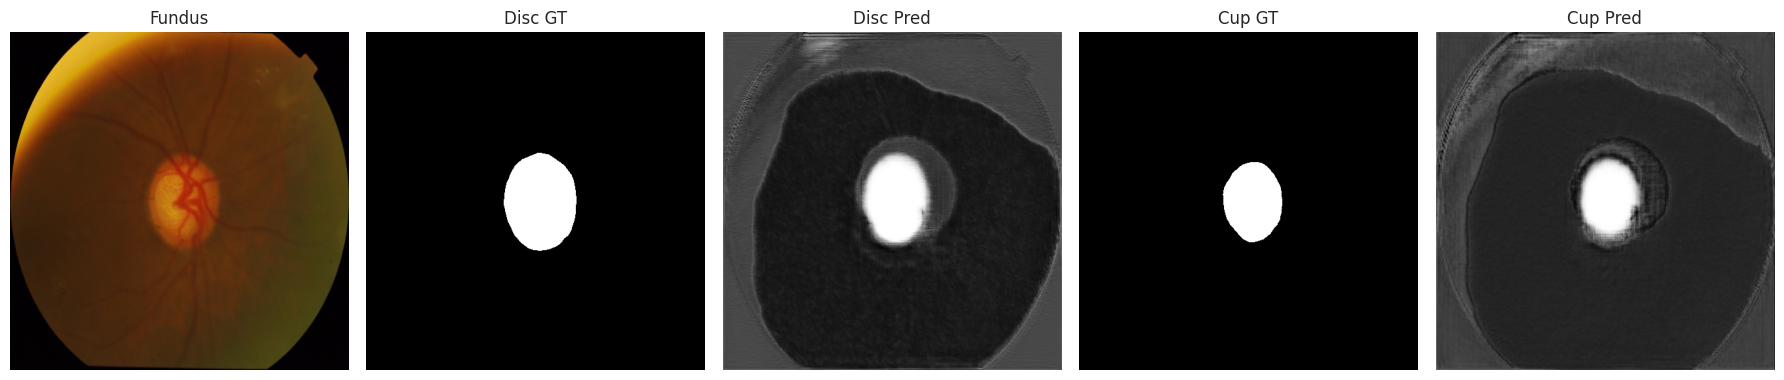

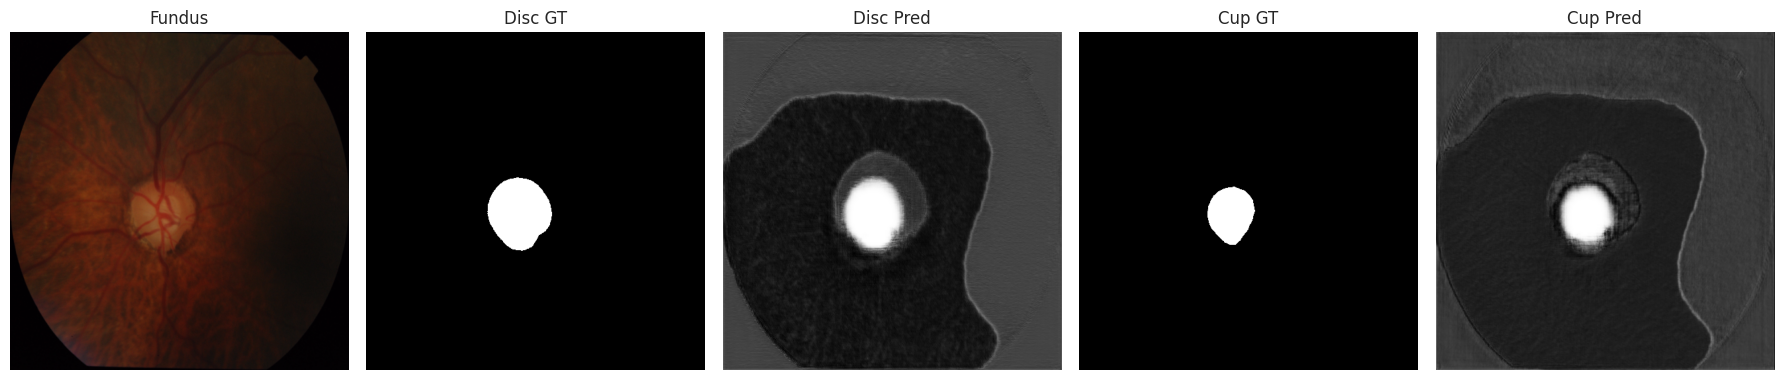

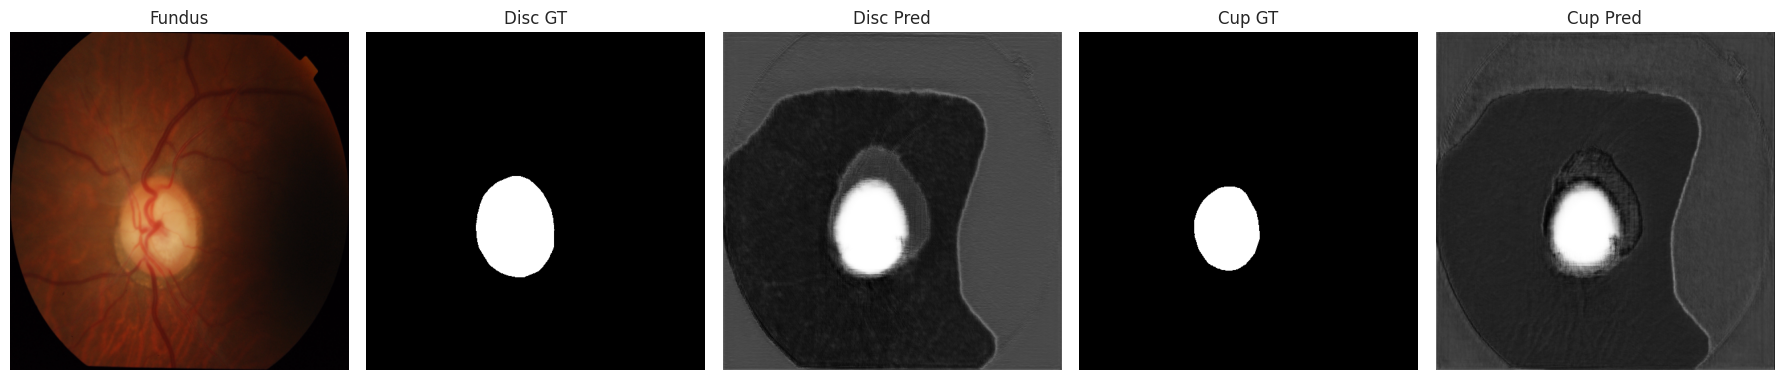

In [ ]:
import matplotlib.pyplot as plt
import torch

imgs, masks = next(iter(test_loader))
imgs = imgs.to(device)

unet.eval()  # Crucial: Always set model to eval mode before inference
with torch.no_grad():
    outputs = unet(imgs)
    preds = torch.sigmoid(outputs).cpu().detach()

for i in range(3):
    # Expanded width to 18 to cleanly fit 5 subplots in a row
    plt.figure(figsize=(18, 4))

    # 1. Original Fundus Input
    plt.subplot(1, 5, 1)
    plt.imshow(imgs[i].cpu().permute(1, 2, 0))
    plt.title("Fundus")
    plt.axis('off')

    # 2. Disc Ground Truth (Channel 0)
    plt.subplot(1, 5, 2)
    plt.imshow(masks[i][0].cpu(), cmap='gray')
    plt.title("Disc GT")
    plt.axis('off')

    # 3. Disc Prediction (Channel 0)
    plt.subplot(1, 5, 3)
    plt.imshow(preds[i][0], cmap='gray')
    plt.title("Disc Pred")
    plt.axis('off')

    # 4. Cup Ground Truth (Channel 1)
    plt.subplot(1, 5, 4)
    plt.imshow(masks[i][1].cpu(), cmap='gray')  # Note the index change to [1]
    plt.title("Cup GT")
    plt.axis('off')

    # 5. Cup Prediction (Channel 1)
    plt.subplot(1, 5, 5)
    plt.imshow(preds[i][1], cmap='gray')  # Note the index change to [1]
    plt.title("Cup Pred")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
def compute_cdr(disc_mask, cup_mask):
    disc_area = (disc_mask > 0.5).sum()
    cup_area = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

cdr_values = []
unet.eval()
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        outputs = unet(imgs)
        preds = torch.sigmoid(outputs).cpu().numpy()
        for i in range(len(imgs)):
            disc_pred = preds[i,0,:,:]
            cup_pred = preds[i,1,:,:]
            cdr = compute_cdr(disc_pred, cup_pred)
            cdr_values.append(cdr)

# Convert np.float64 values to standard Python floats for cleaner output
print("Sample CDR values for UNET:", [float(cdr) for cdr in cdr_values[:10]])

Sample CDR values for UNET: [0.6898519427129458, 0.7054663141866863, 0.7779707075509809, 0.5704225345065203, 0.7249739551804395, 0.6398922485124375, 0.7091830263341571, 0.6703201962188176, 0.6803773578487006, 0.7744959754629587]


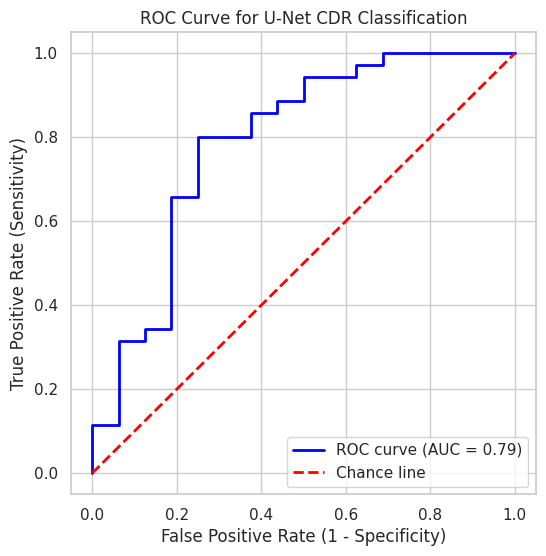

In [ ]:
from sklearn.metrics import roc_curve, auc
import numpy as np
import torch
import matplotlib.pyplot as plt

# Helper to calculate Cup-to-Disc Ratio safely
def compute_cdr(disc_mask, cup_mask):
    disc_area = (disc_mask > 0.5).sum()
    cup_area  = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

# Lists to store predicted and ground-truth CDRs
calc_cdr_values = []
calc_gt_values  = []

unet.eval()
with torch.no_grad():
    for imgs, masks in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        outputs = unet(imgs)              #forward pass
        preds   = torch.sigmoid(outputs).cpu().numpy()
        gt_masks = masks.cpu().numpy()

        for i in range(imgs.size(0)):
            disc_pred = preds[i, 0, :, :]
            cup_pred  = preds[i, 1, :, :]
            disc_gt   = gt_masks[i, 0, :, :]
            cup_gt    = gt_masks[i, 1, :, :]

            #correct argument order
            calc_cdr_values.append(compute_cdr(disc_pred, cup_pred))
            calc_gt_values.append(compute_cdr(disc_gt, cup_gt))

# Convert to numpy arrays
cdr_values_arr = np.array(calc_cdr_values)
gt_values_arr  = np.array(calc_gt_values)

# Ground truth labels: suspicious if CDR >= 0.55
gt_labels = (gt_values_arr >= 0.55).astype(int)

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(gt_labels, cdr_values_arr)
roc_auc = auc(fpr, tpr)

# Plot the ROC Curve
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], color='red', linestyle='--', lw=2, label='Chance line')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve for U-Net CDR Classification')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, ttest_rel

# --- DYNAMIC VARIABLE COUPLING ---
# Safely load the aligned, model-specific 51-sample test results
try:
    y_pred_unet = np.array(cdr_values_arr if 'cdr_values_arr' in locals() else unet_cdr_values)
    y_true_unet = np.array(gt_values_arr if 'gt_values_arr' in locals() else unet_gt_values)
except NameError:
    raise NameError("Please run your Standard U-Net evaluation in cell 5qX7VBAkX5cm to generate 'cdr_values_arr' and 'gt_values_arr' before running this cell.")

# 1. Compute Classical Regression Error Metrics
mae_unet = mean_absolute_error(y_true_unet, y_pred_unet)
rmse_unet = np.sqrt(mean_squared_error(y_true_unet, y_pred_unet))

# 2. Compute Statistical Correlation (Linear Tracking of Glaucoma Progression)
correlation_unet, _ = pearsonr(y_true_unet, y_pred_unet)

# 3. Compute Paired t-test (Checks for systemic over/underestimation bias)
t_stat_unet, p_value_unet = ttest_rel(y_true_unet, y_pred_unet)

print("=== COMPARATIVE MORPHOMETRIC REPORT: ACTUAL VS. PREDICTED STANDARD U-NET CDR ===")
print(f"Number of Test Samples        : {len(y_true_unet)}")
print(f"Mean Absolute Error (MAE)     : {mae_unet:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse_unet:.4f}")
print(f"Pearson Correlation Coeff (r)  : {correlation_unet:.4f}")
print(f"Paired t-test p-value          : {p_value_unet:.4e}")

if p_value_unet < 0.05:
    print("\n STATISTICAL VERDICT: Significant systemic bias detected. The model is structurally deviating from the ground truth.")
else:
    print("\n STATISTICAL VERDICT: No significant systemic bias! Discrepancies are purely due to minor, random boundary noise.")

=== COMPARATIVE MORPHOMETRIC REPORT: ACTUAL VS. PREDICTED STANDARD U-NET CDR ===
Number of Test Samples        : 51
Mean Absolute Error (MAE)     : 0.1555
Root Mean Squared Error (RMSE) : 0.2040
Pearson Correlation Coeff (r)  : 0.5622
Paired t-test p-value          : 6.2677e-10

 STATISTICAL VERDICT: Significant systemic bias detected. The model is structurally deviating from the ground truth.


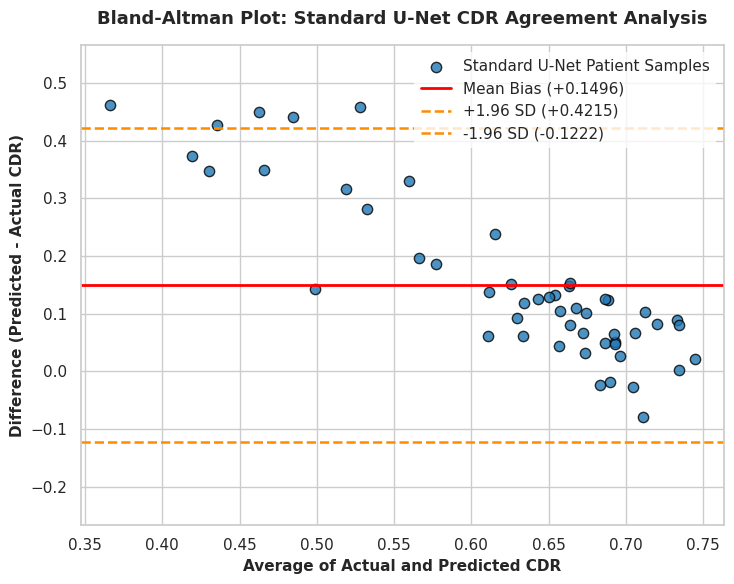

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate statistical averages and differences
mean_cdr_unet = (y_true_unet + y_pred_unet) / 2.0
diff_cdr_unet = y_pred_unet - y_true_unet

mean_diff_unet = np.mean(diff_cdr_unet)
std_diff_unet = np.std(diff_cdr_unet)

# Configure medical publication theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7.5, 6))

# Generate scatter mapping using a clean Blue palette to visually code it to the Standard U-Net theme
plt.scatter(mean_cdr_unet, diff_cdr_unet, color='#1f77b4', alpha=0.8, edgecolors='black', s=55, label='Standard U-Net Patient Samples')

# Draw Mean Bias and 95% Limits of Agreement (LoA) Lines
plt.axhline(mean_diff_unet, color='red', linestyle='-', lw=2, label=f'Mean Bias ({mean_diff_unet:+.4f})')
plt.axhline(mean_diff_unet + 1.96 * std_diff_unet, color='darkorange', linestyle='--', lw=1.8, label=f'+1.96 SD ({mean_diff_unet + 1.96 * std_diff_unet:+.4f})')
plt.axhline(mean_diff_unet - 1.96 * std_diff_unet, color='darkorange', linestyle='--', lw=1.8, label=f'-1.96 SD ({mean_diff_unet - 1.96 * std_diff_unet:+.4f})')

# Formatting boundaries and labels
plt.title('Bland-Altman Plot: Standard U-Net CDR Agreement Analysis', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Average of Actual and Predicted CDR', fontsize=11, fontweight='bold')
plt.ylabel('Difference (Predicted - Actual CDR)', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# Dynamically pad limits based on the distribution spread to prevent clipping
plt.ylim(mean_diff_unet - 3 * std_diff_unet, mean_diff_unet + 3 * std_diff_unet)
plt.tight_layout()
plt.show()

In [ ]:
J_scores = tpr - fpr
best_idx = np.argmax(J_scores)
best_threshold = thresholds[best_idx]
print("Optimal threshold:", best_threshold)

Optimal threshold: 0.6898519427129458


/tmp/ipykernel_579/446619233.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(list(float(cdr) for cdr in cdr_values[:10]), labels=['U-Net'])


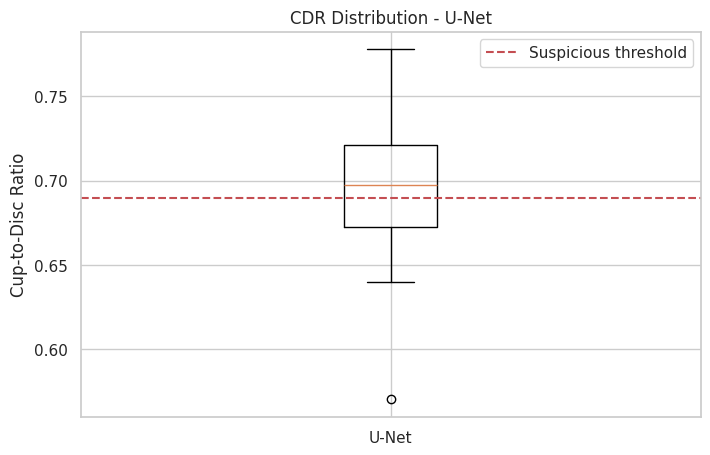

In [ ]:
plt.figure(figsize=(8,5))
plt.boxplot(list(float(cdr) for cdr in cdr_values[:10]), labels=['U-Net'])
plt.title("CDR Distribution - U-Net")
plt.ylabel("Cup-to-Disc Ratio")
plt.axhline(best_threshold, color='r', linestyle='--', label='Suspicious threshold')
plt.legend()
plt.show()

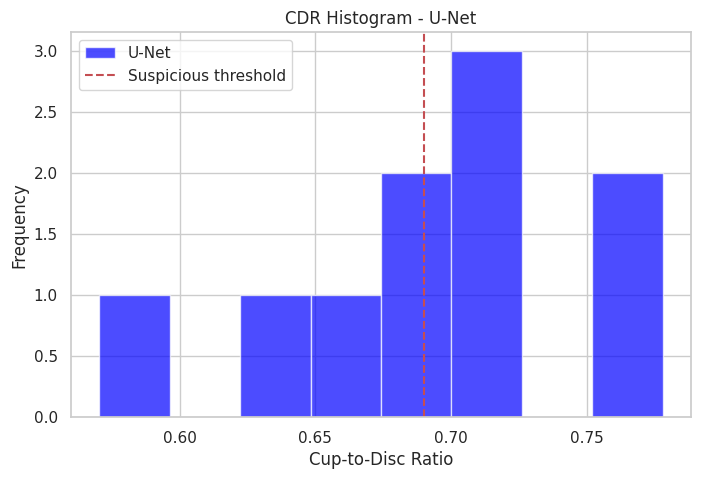

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(list(float(cdr) for cdr in cdr_values[:10]), bins=8, alpha=0.7, color='blue', label='U-Net')
plt.title("CDR Histogram - U-Net")
plt.xlabel("Cup-to-Disc Ratio")
plt.ylabel("Frequency")
plt.axvline(best_threshold, color='r', linestyle='--', label='Suspicious threshold')
plt.legend()
plt.show()

In [ ]:
import numpy as np

# Use the correctly aligned arrays from our previous run
cdr_values_clean = np.array(cdr_values_arr)
gt_values_clean  = np.array(gt_values_arr)

# Ground truth labels: suspicious if CDR >= 0.55
gt_labels = (gt_values_clean >= 0.55).astype(int)

# Optimal threshold from ROC analysis
optimal_threshold = best_threshold

# Predicted labels using optimal threshold
pred_labels = (cdr_values_clean >= optimal_threshold).astype(int)

# Confusion matrix components
TP = np.sum((pred_labels == 1) & (gt_labels == 1))
TN = np.sum((pred_labels == 0) & (gt_labels == 0))
FP = np.sum((pred_labels == 1) & (gt_labels == 0))
FN = np.sum((pred_labels == 0) & (gt_labels == 1))

# Metrics
sensitivity = TP / (TP + FN + 1e-8)
specificity = TN / (TN + FP + 1e-8)
accuracy    = (TP + TN) / (TP + TN + FP + FN + 1e-8)

print(f"Evaluation at Optimal Threshold ({optimal_threshold:.3f}):")
print(f"  Sensitivity : {sensitivity:.4f}")
print(f"  Specificity : {specificity:.4f}")
print(f"  Accuracy    : {accuracy:.4f}")
print(f"  TP={TP}, TN={TN}, FP={FP}, FN={FN}")

Evaluation at Optimal Threshold (0.690):
  Sensitivity : 0.8000
  Specificity : 0.7500
  Accuracy    : 0.7843
  TP=28, TN=12, FP=4, FN=7


What is U-Net++?

**U-Net++: A Nested U-Net Architecture for Semantic Segmentation

U-Net++ is an advanced deep learning architecture designed for semantic segmentation, particularly for tasks involving medical images. It is an improved version of the original U-Net architecture, developed to address some of the limitations of U-Net, especially the semantic gap between feature maps in the encoder and decoder paths.

U-Net++ uses a nested and densely connected architecture that contains multiple intermediate convolutional blocks between the encoder and decoder. These additional connections allow the network to gradually refine feature representations and produce more accurate segmentation results. The architecture combines multi-scale feature extraction with improved feature fusion, helping it capture both fine details and high-level contextual information.

U-Net++ has been extensively used in medical image segmentation tasks. It has demonstrated strong performance in applications such as brain tumor segmentation, liver segmentation, lung segmentation, cell segmentation, and skin lesion segmentation. Its ability to capture detailed boundaries and improve segmentation accuracy makes it particularly useful for medical image analysis and computer-aided diagnosis.

U-Net++: A Nested U-Net Architecture


U-Net++ uses a nested U-Net structure with multiple interconnected convolutional blocks. The architecture consists of an encoder (contracting path), a series of nested dense skip connections, and a decoder (expanding path). Unlike the original U-Net, where encoder features are directly connected to corresponding decoder features, U-Net++ introduces intermediate convolutional layers between these connections. These nested connections help reduce the semantic gap between low-level encoder features and high-level decoder features. The network combines feature maps from different depths and resolutions, allowing it to learn both fine-grained spatial information and high-level semantic information. U-Net++ can also support deep supervision, where segmentation outputs are generated at multiple decoder levels. This can improve training and, in some implementations, allows different levels of the network to be used depending on the required accuracy and computational cost. The architecture is particularly effective when accurate object boundaries are important, such as in tumor, organ, tissue, and cell segmentation. Key Difference Between U-Net and U-Net++

The main difference is the way skip connections are implemented.

U-Net:

Encoder → Direct Skip Connection → Decoder

U-Net++:

Encoder → Nested/Dense Skip Connections → Decoder

In U-Net, the encoder feature map is directly concatenated with the corresponding decoder feature map. In U-Net++, several convolutional blocks are placed along the skip pathway before the features reach the decoder. This allows the network to progressively bridge the difference between the encoder and decoder feature representations.

In simple terms:

U-Net provides direct shortcuts between the encoder and decoder, whereas U-Net++ uses a series of nested, densely connected pathways to gradually refine and combine features.

This makes U-Net++ generally more powerful for complex segmentation tasks, although it can require more computational resources and parameters than the original U-Net.

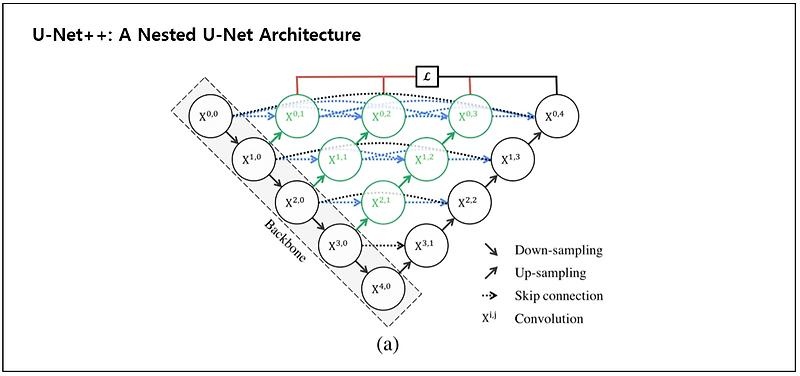

In [ ]:
import segmentation_models_pytorch as smp

# Initialize U-Net++ model structure
unet_plus_plus = smp.UnetPlusPlus(
    encoder_name="resnet34",        # Encoder - Using resnet34 for the feature extraction
    encoder_weights="imagenet",     # imagenet - for transferlearning, ResNet-34 encoder is initialized with weights pre-trained on ImageNet
    in_channels=3,                  # 3 channels - Specifies that the model expects input images with 3 color channels, which corresponds to standard RGB
    classes=2                       # Defines the number of output channels - value of 2 indicates the network will output two separate prediction maps—one for the Optic Disc (OD) boundaries and one for the Optic Cup (OC) boundaries
).to(device)


In [ ]:
# find GPU availability for processing and inizialize UNet++ with device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print (f"supported device: {device}")
unet_plus_plus = unet_plus_plus.to(device)

supported device: cuda


In [ ]:
# Training dataset
train_dataset = DrishtiSegmentationDataset(DATASET_ROOT,split="Training",transform=True)

# Official test dataset
test_dataset = DrishtiSegmentationDataset(DATASET_ROOT,split="Test",transform=False)

print("Train Dataset Len:", len(train_dataset))
print("Test Dataset Len:", len(test_dataset))

Train Dataset Len: 50
Test Dataset Len: 51


In [ ]:
from sklearn.model_selection import train_test_split

# Get the 50 official training images
all_train_paths = sorted((DATASET_ROOT / "Training" / "Images").glob("*.png"))

# 80% training / 20% validation
train_paths, val_paths = train_test_split(all_train_paths,test_size=0.20,random_state=42)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 40
Validation images: 10


In [ ]:
train_dataset = DrishtiSegmentationDataset(DATASET_ROOT,split="Training",transform=True,image_paths=train_paths)

val_dataset = DrishtiSegmentationDataset(DATASET_ROOT,split="Training",transform=False,image_paths=val_paths)

test_dataset = DrishtiSegmentationDataset(DATASET_ROOT,split="Test",transform=False)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 40
Validation dataset: 10
Test dataset: 51


In [ ]:
import torch.nn as nn

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred_logits, targets, smooth=1e-5):
        # Base BCE tracking
        bce_loss = self.bce(pred_logits, targets)

        # Compute multi-channel Dice Coefficient
        pred_probs = torch.sigmoid(pred_logits)
        intersection = (pred_probs * targets).sum(dim=(2, 3))
        union = pred_probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))

        dice_loss = 1 - ((2. * intersection + smooth) / (union + smooth)).mean()

        # Return compound loss balance
        return bce_loss + dice_loss


In [ ]:
criterion = BCEDiceLoss()
optimizer_unetpp = torch.optim.Adam(unet_plus_plus.parameters(), lr=1e-4)

scheduler_unetpp = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_unetpp, mode="min", factor=0.5, patience=5)

criterion_unetpp = BCEDiceLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

In [ ]:
def dice_coeff(pred, target, smooth=1e-5):
    pred = torch.sigmoid(pred) > 0.5
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum()
    return (2. * intersection + smooth) / (union + smooth)

def iou_score(pred, target, smooth=1e-5):
    pred = torch.sigmoid(pred) > 0.5
    intersection = (pred & target).sum()
    union = (pred | target).sum()
    return (intersection + smooth) / (union + smooth)

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=True)

val_loader = DataLoader(val_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=False)

test_loader = DataLoader(test_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=False)

In [ ]:
def compute_cdr(disc_mask, cup_mask):
    # Calculate Cup-to-Disc Ratio
    disc_area = (disc_mask > 0.5).sum()
    cup_area = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

def safe_iou_score(pred, target, smooth=1e-5):
    # Convert predictions and targets to boolean masks
    pred_bool = torch.sigmoid(pred) > 0.5
    target_bool = target > 0.5
    intersection = (pred_bool & target_bool).sum()
    union = (pred_bool | target_bool).sum()
    return (intersection.float() + smooth) / (union.float() + smooth)

# --- TRACKING HISTORY CONTAINERS ---
history_unetpp = {
    'train_loss': [], 'val_loss': [], 'val_dice': [],
    'val_iou': [], 'sensitivity': [], 'specificity': [], 'accuracy': []
}

print("Initiating U-Net++ Training and Diagnostic Tracking Loop...\n")

for epoch in range(10):

    # =========================
    # Training
    # =========================
    unet_plus_plus.train()
    running_train_loss = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer_unetpp.zero_grad()
        outputs = unet_plus_plus(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer_unetpp.step()

        running_train_loss += loss.item()

    # =========================
    # Validation
    # =========================
    unet_plus_plus.eval()
    running_val_loss = 0.0
    val_dice_accum = 0.0
    val_iou_accum = 0.0

    cdr_values = []
    gt_values = []

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            outputs = unet_plus_plus(imgs)
            loss = criterion(outputs, masks)

            running_val_loss += loss.item()
            val_dice_accum += dice_coeff(outputs, masks).item()
            val_iou_accum += safe_iou_score(outputs, masks).item()

            # =========================
            # CDR diagnostic evaluation
            # =========================
            disc_pred = outputs[:, 0, :, :]
            cup_pred = outputs[:, 1, :, :]
            disc_gt = masks[:, 0, :, :]
            cup_gt = masks[:, 1, :, :]

            for i in range(imgs.size(0)):
                pred_cdr = compute_cdr(disc_pred[i], cup_pred[i])
                gt_cdr = compute_cdr(disc_gt[i], cup_gt[i])

                cdr_values.append(pred_cdr.item() if torch.is_tensor(pred_cdr) else float(pred_cdr))
                gt_values.append(gt_cdr.item() if torch.is_tensor(gt_cdr) else float(gt_cdr))

    # Average validation results
    epoch_train_loss = running_train_loss / len(train_loader)
    epoch_val_loss = running_val_loss / len(val_loader)
    epoch_val_dice = val_dice_accum / len(val_loader)
    epoch_val_iou = val_iou_accum / len(val_loader)

    # Update learning-rate scheduler using validation loss
    scheduler_unetpp.step(epoch_val_loss)

    # =========================
    # CDR Diagnostic Metrics
    # =========================
    pred_suspicious = torch.tensor(cdr_values) >= 0.6
    gt_suspicious = torch.tensor(gt_values) >= 0.6

    tp = ((pred_suspicious == 1) & (gt_suspicious == 1)).sum().item()
    tn = ((pred_suspicious == 0) & (gt_suspicious == 0)).sum().item()
    fp = ((pred_suspicious == 1) & (gt_suspicious == 0)).sum().item()
    fn = ((pred_suspicious == 0) & (gt_suspicious == 1)).sum().item()

    sensitivity = tp / (tp + fn + 1e-6)
    specificity = tn / (tn + fp + 1e-6)
    accuracy = ((tp + tn) / (tp + tn + fp + fn + 1e-6))

    # --- CACHE DATA INTO HISTORY FOR PLOTTING ---
    history_unetpp['train_loss'].append(epoch_train_loss)
    history_unetpp['val_loss'].append(epoch_val_loss)
    history_unetpp['val_dice'].append(epoch_val_dice)
    history_unetpp['val_iou'].append(epoch_val_iou)
    history_unetpp['sensitivity'].append(sensitivity)
    history_unetpp['specificity'].append(specificity)
    history_unetpp['accuracy'].append(accuracy)

    print(
        f"Epoch {epoch + 1}/10: "
        f"Train Loss={epoch_train_loss:.4f}, "
        f"Val Loss={epoch_val_loss:.4f} | "
        f"Val Dice={epoch_val_dice:.4f}, "
        f"Val IoU={epoch_val_iou:.4f} | "
        f"Sens={sensitivity:.4f}, "
        f"Spec={specificity:.4f}, "
        f"Acc={accuracy:.4f}"
    )

Initiating U-Net++ Training and Diagnostic Tracking Loop...

Epoch 1/10: Train Loss=1.6523, Val Loss=1.8365 | Val Dice=0.0450, Val IoU=0.0230 | Sens=0.6667, Spec=0.0000, Acc=0.2000
Epoch 2/10: Train Loss=1.5042, Val Loss=1.7391 | Val Dice=0.0681, Val IoU=0.0353 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 3/10: Train Loss=1.4060, Val Loss=1.5781 | Val Dice=0.1131, Val IoU=0.0601 | Sens=1.0000, Spec=0.0000, Acc=0.3000
Epoch 4/10: Train Loss=1.3379, Val Loss=1.3761 | Val Dice=0.4811, Val IoU=0.3179 | Sens=1.0000, Spec=0.1429, Acc=0.4000
Epoch 5/10: Train Loss=1.2960, Val Loss=1.3024 | Val Dice=0.7070, Val IoU=0.5492 | Sens=1.0000, Spec=0.1429, Acc=0.4000
Epoch 6/10: Train Loss=1.2667, Val Loss=1.2601 | Val Dice=0.7892, Val IoU=0.6535 | Sens=1.0000, Spec=0.1429, Acc=0.4000
Epoch 7/10: Train Loss=1.2418, Val Loss=1.2342 | Val Dice=0.8237, Val IoU=0.7018 | Sens=1.0000, Spec=0.5714, Acc=0.7000
Epoch 8/10: Train Loss=1.2181, Val Loss=1.2064 | Val Dice=0.8576, Val IoU=0.7514 | Sens=0.3333, Spe

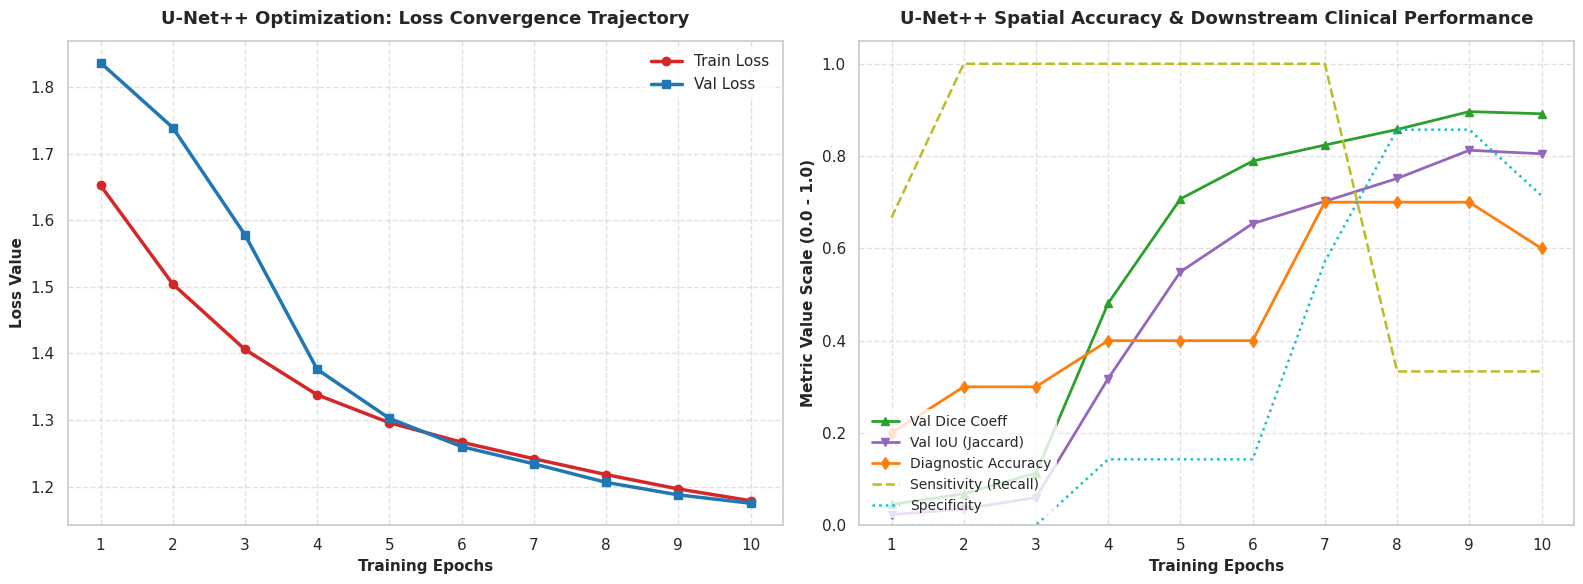

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CONFIGURE THEME & VISUAL CANVAS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
epochs_range = np.arange(1, 11)

# Ensure data mapping vectors match the training epoch history range
try:
    # 1. Left Subplot: Loss Trajectories (Error Optimization convergence)
    axes[0].plot(epochs_range, history_unetpp['train_loss'], label='Train Loss', color='#d62728', lw=2.5, marker='o')
    axes[0].plot(epochs_range, history_unetpp['val_loss'], label='Val Loss', color='#1f77b4', lw=2.5, marker='s')
    axes[0].set_title('U-Net++ Optimization: Loss Convergence Trajectory', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Loss Value', fontsize=11, fontweight='bold')
    axes[0].set_xticks(epochs_range)
    axes[0].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Right Subplot: Spatial Overlap & Clinical Diagnostic Performance Curves
    axes[1].plot(epochs_range, history_unetpp['val_dice'], label='Val Dice Coeff', color='#2ca02c', lw=2, marker='^')
    axes[1].plot(epochs_range, history_unetpp['val_iou'], label='Val IoU (Jaccard)', color='#9467bd', lw=2, marker='v')
    axes[1].plot(epochs_range, history_unetpp['accuracy'], label='Diagnostic Accuracy', color='#ff7f0e', lw=2, marker='d')
    axes[1].plot(epochs_range, history_unetpp['sensitivity'], label='Sensitivity (Recall)', color='#bcbd22', lw=1.8, linestyle='--')
    axes[1].plot(epochs_range, history_unetpp['specificity'], label='Specificity', color='#17becf', lw=1.8, linestyle=':')

    axes[1].set_title('U-Net++ Spatial Accuracy & Downstream Clinical Performance', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Metric Value Scale (0.0 - 1.0)', fontsize=11, fontweight='bold')
    axes[1].set_xticks(epochs_range)

    # Restrict standard metric limits to prevent edge line truncation clipping
    axes[1].set_ylim(0.0, 1.05)
    axes[1].legend(loc='lower left', frameon=True, facecolor='white', edgecolor='none', fontsize=10)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

except NameError:
    raise NameError("Please execute the U-Net++ training cell block first to populate the 'history_unetpp' dictionary.")

In [ ]:
# Create a directory in your drive and save the weights
UNET_PLUS_PLUS_SAVE_PATH = DATASET_ROOT / "Drishti_UNetPlusPlus_Glaucoma.pth"
torch.save(unet_plus_plus.state_dict(), UNET_PLUS_PLUS_SAVE_PATH)
print(f" U-Net++ weights safely backed up to: {UNET_PLUS_PLUS_SAVE_PATH}")

 U-Net++ weights safely backed up to: /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Drishti_UNetPlusPlus_Glaucoma.pth


In [ ]:
#Evaluation of the model created
#To evaluate a segmentation model, standard classification accuracy cannot be used.
#Instead, metrics that measure spatial overlap must be calculated
#1.Dice Coefficient: Measures the overall overlap between prediction and ground truth
#2.Intersection over Union (IoU) : Measures the intersection area  divided by the
#total combined area of prediction and ground truth

import torch
import numpy as np

def calculate_segmentation_metrics(pred_mask, gt_mask, smooth=1e-5):
    """
    Computes both IoU and Dice Coefficient for a single binary mask slice.
    """
    # Flatten matrices
    pred_flat = pred_mask.flatten()
    gt_flat = gt_mask.flatten()

    intersection = np.sum(pred_flat * gt_flat)
    total_sum = np.sum(pred_flat) + np.sum(gt_flat)
    union = total_sum - intersection

    # Calculate scores
    iou = (intersection + smooth) / (union + smooth)
    dice = (2.0 * intersection + smooth) / (total_sum + smooth)

    return iou, dice

def test_unet_plus_plus(model, test_loader, device):
    """
    Evaluates the trained U-Net++ on the unseen Test data loader.
    """
    model.eval()

    disc_ious, disc_dices = [], []
    cup_ious, cup_dices = [], []

    print(" Running evaluation on U-Net ++ segmentation test set...")
    print("   |__ Optic Disc Benchmarks (Target: Dice > 90%)")
    print("   |__ Optic Cup Benchmarks (Target: Dice > 75%–80%)")


    with torch.no_grad():
        for batch_images, batch_masks in test_loader:
            batch_images = batch_images.to(device)

            # Forward pass to get raw logits from U-Net
            outputs = model(batch_images)
            # Apply sigmoid to convert to class probabilities (0.0 to 1.0)
            probs = torch.sigmoid(outputs).cpu().numpy()
            gt_masks = batch_masks.numpy()

            # Loop through every image slice inside the current batch
            for i in range(batch_images.size(0)):
                # Apply standard binary consensus threshold of 0.5
                pred_disc = probs[i, 0, :, :] > 0.5
                pred_cup = probs[i, 1, :, :] > 0.5

                gt_disc = gt_masks[i, 0, :, :] > 0.5
                gt_cup = gt_masks[i, 1, :, :] > 0.5

                # Compute metrics for Disc (Channel 0)
                d_iou, d_dice = calculate_segmentation_metrics(pred_disc, gt_disc)
                disc_ious.append(d_iou)
                disc_dices.append(d_dice)

                # Compute metrics for Cup (Channel 1)
                c_iou, c_dice = calculate_segmentation_metrics(pred_cup, gt_cup)
                cup_ious.append(c_iou)
                cup_dices.append(c_dice)

    # --- Print Performance Summary Report ---
    print("\n" + "="*50)
    print(" U-NET ++ SEGMENTATION TEST PERFORMANCE REPORT")
    print("="*50)
    print(f" OPTIC DISC (OD):")
    print(f"   └── Mean IoU  : {np.mean(disc_ious) * 100:.2f}%")
    print(f"   └── Mean Dice : {np.mean(disc_dices) * 100:.2f}%")
    print(f"--------------------------------------------------")
    print(f" OPTIC CUP (OC):")
    print(f"   └── Mean IoU  : {np.mean(cup_ious) * 100:.2f}%")
    print(f"   └── Mean Dice : {np.mean(cup_dices) * 100:.2f}%")
    print("="*50)

    return {
        'disc_dice': np.mean(disc_dices),
        'cup_dice': np.mean(cup_dices)
    }

# Execute evaluation using your configured validation test loader
seg_results = test_unet_plus_plus(unet_plus_plus, test_loader, device)

 Running evaluation on U-Net ++ segmentation test set...
   |__ Optic Disc Benchmarks (Target: Dice > 90%)
   |__ Optic Cup Benchmarks (Target: Dice > 75%–80%)

 U-NET ++ SEGMENTATION TEST PERFORMANCE REPORT
 OPTIC DISC (OD):
   └── Mean IoU  : 87.17%
   └── Mean Dice : 93.06%
--------------------------------------------------
 OPTIC CUP (OC):
   └── Mean IoU  : 76.30%
   └── Mean Dice : 85.92%


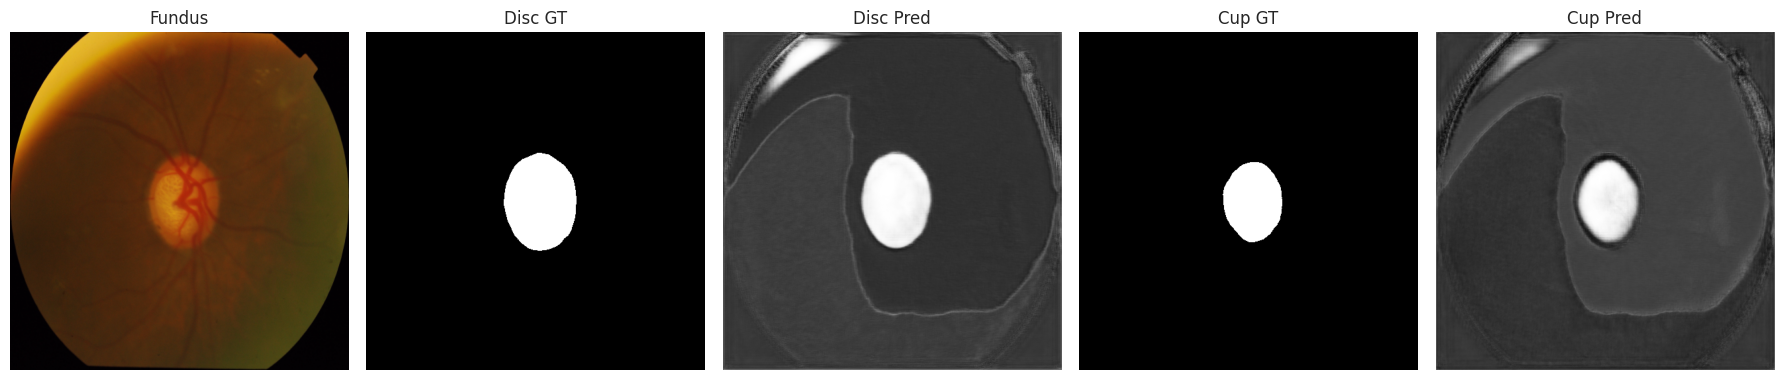

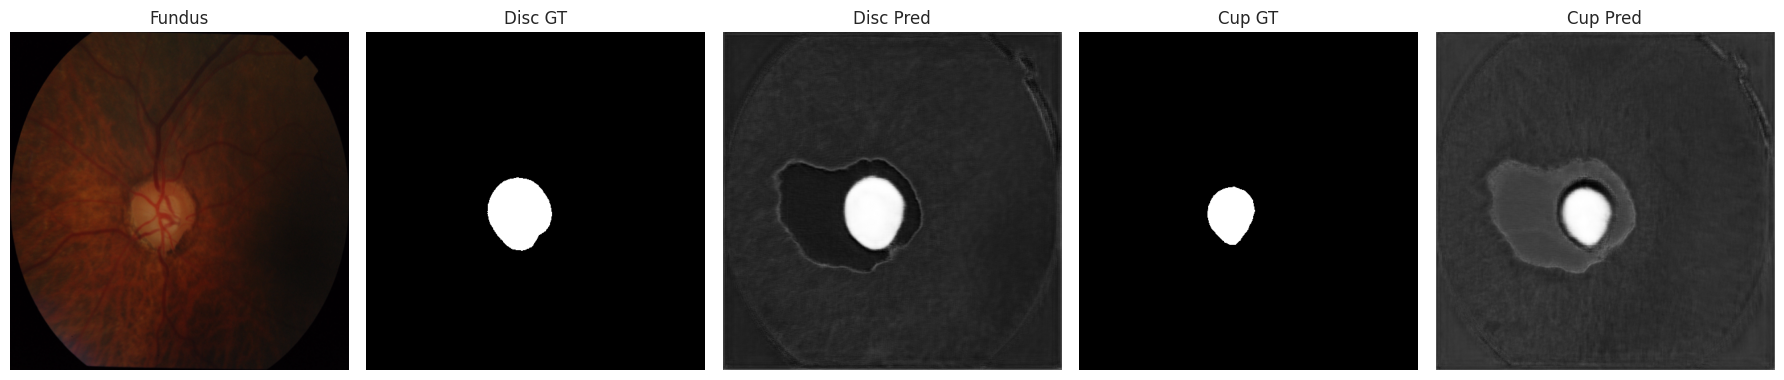

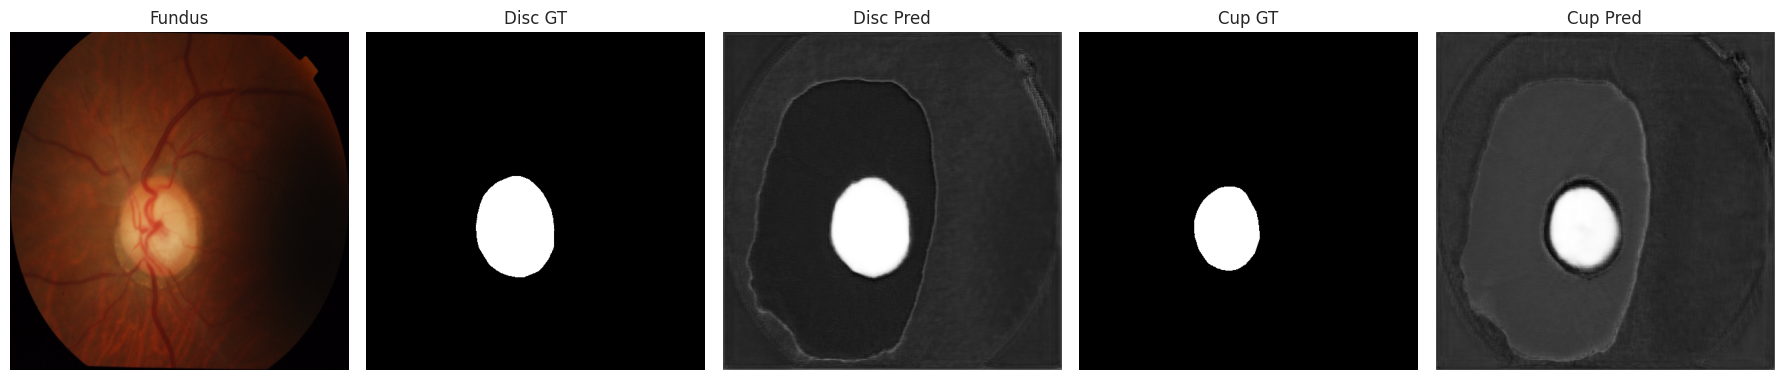

In [ ]:
import matplotlib.pyplot as plt
import torch

imgs, masks = next(iter(test_loader))
imgs = imgs.to(device)

unet_plus_plus.eval()  # Crucial: Always set model to eval mode before inference
with torch.no_grad():
    outputs = unet_plus_plus(imgs)
    preds = torch.sigmoid(outputs).cpu().detach()

for i in range(3):
    # Expanded width to 18 to cleanly fit 5 subplots in a row
    plt.figure(figsize=(18, 4))

    # 1. Original Fundus Input
    plt.subplot(1, 5, 1)
    plt.imshow(imgs[i].cpu().permute(1, 2, 0))
    plt.title("Fundus")
    plt.axis('off')

    # 2. Disc Ground Truth (Channel 0)
    plt.subplot(1, 5, 2)
    plt.imshow(masks[i][0].cpu(), cmap='gray')
    plt.title("Disc GT")
    plt.axis('off')

    # 3. Disc Prediction (Channel 0)
    plt.subplot(1, 5, 3)
    plt.imshow(preds[i][0], cmap='gray')
    plt.title("Disc Pred")
    plt.axis('off')

    # 4. Cup Ground Truth (Channel 1)
    plt.subplot(1, 5, 4)
    plt.imshow(masks[i][1].cpu(), cmap='gray')  # Note the index change to [1]
    plt.title("Cup GT")
    plt.axis('off')

    # 5. Cup Prediction (Channel 1)
    plt.subplot(1, 5, 5)
    plt.imshow(preds[i][1], cmap='gray')  # Note the index change to [1]
    plt.title("Cup Pred")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
def compute_cdr(disc_mask, cup_mask):
    disc_area = (disc_mask > 0.5).sum()
    cup_area = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

cdr_values = []
unet_plus_plus.eval()
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        outputs = unet_plus_plus(imgs)
        preds = torch.sigmoid(outputs).cpu().numpy()
        for i in range(len(imgs)):
            disc_pred = preds[i,0,:,:]
            cup_pred = preds[i,1,:,:]
            cdr = compute_cdr(disc_pred, cup_pred)
            cdr_values.append(cdr)

# Convert np.float64 values to standard Python floats for cleaner output
print("Sample CDR values for UNET:", [float(cdr) for cdr in cdr_values[:10]])

Sample CDR values for UNET: [0.6250235297577815, 0.6129032250249864, 0.6897007650036877, 0.36410744462340583, 0.5821592644853298, 0.46835594995994245, 0.5222974872674323, 0.4855667366451712, 0.540529774406961, 0.7369982814797764]


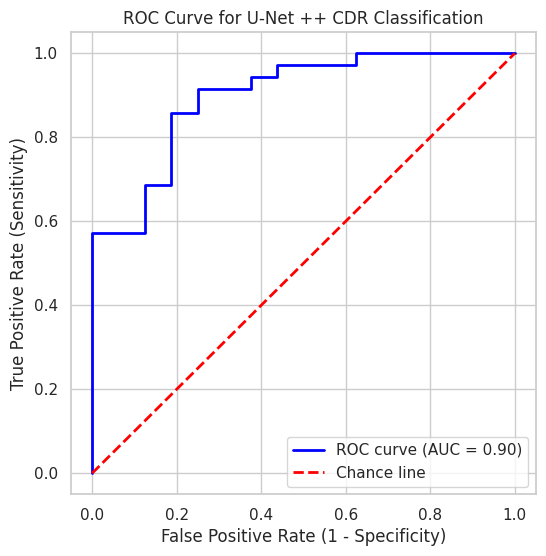

In [ ]:
from sklearn.metrics import roc_curve, auc
import numpy as np
import torch
import matplotlib.pyplot as plt

# Helper to calculate Cup-to-Disc Ratio safely
def compute_cdr(disc_mask, cup_mask):
    disc_area = (disc_mask > 0.5).sum()
    cup_area  = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

# Lists to store predicted and ground-truth CDRs specifically for UNet++
calc_cdr_values_unetpp = []
calc_gt_values_unetpp  = []

unet_plus_plus.eval()
with torch.no_grad():
    for imgs, masks in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        outputs = unet_plus_plus(imgs)              #forward pass
        preds   = torch.sigmoid(outputs).cpu().numpy()
        gt_masks = masks.cpu().numpy()

        for i in range(imgs.size(0)):
            disc_pred = preds[i, 0, :, :]
            cup_pred  = preds[i, 1, :, :]
            disc_gt   = gt_masks[i, 0, :, :]
            cup_gt    = gt_masks[i, 1, :, :]

            #correct argument order
            calc_cdr_values_unetpp.append(compute_cdr(disc_pred, cup_pred))
            calc_gt_values_unetpp.append(compute_cdr(disc_gt, cup_gt))

# Convert to model-specific numpy arrays
cdr_values_arr_unetpp = np.array(calc_cdr_values_unetpp)
gt_values_arr_unetpp  = np.array(calc_gt_values_unetpp)

# Ground truth labels: suspicious if CDR >= 0.55
gt_labels_unetpp = (gt_values_arr_unetpp >= 0.55).astype(int)

# Compute ROC curve
fpr_unetpp, tpr_unetpp, thresholds_unetpp = roc_curve(gt_labels_unetpp, cdr_values_arr_unetpp)
roc_auc_unetpp = auc(fpr_unetpp, tpr_unetpp)

# Plot the ROC Curve
plt.figure(figsize=(6,6))
plt.plot(fpr_unetpp, tpr_unetpp, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc_unetpp:.2f})')
plt.plot([0,1], [0,1], color='red', linestyle='--', lw=2, label='Chance line')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve for U-Net ++ CDR Classification')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, ttest_rel

# --- DYNAMIC VARIABLE COUPLING ---
# Extracts U-Net++ aligned test-set arrays specifically to avoid split length mismatch
try:
    y_pred_unetpp = np.array(cdr_values_arr_unetpp)
    y_true_unetpp = np.array(gt_values_arr_unetpp)
except NameError:
    try:
        # Fallback if specific test arrays are missing from the current workspace
        y_pred_unetpp = np.array(unetpp_cdr_values if 'unetpp_cdr_values' in locals() else cdr_values)
        y_true_unetpp = np.array(unetpp_gt_values if 'unetpp_gt_values' in locals() else gt_values)
    except NameError:
        raise NameError("Please run your U-Net++ inference loop to populate the CDR lists before executing this cell.")

# 1. Compute Classical Regression Error Metrics
mae_pp = mean_absolute_error(y_true_unetpp, y_pred_unetpp)
rmse_pp = np.sqrt(mean_squared_error(y_true_unetpp, y_pred_unetpp))

# 2. Compute Statistical Correlation (Linear Tracking of Glaucoma Progression)
correlation_pp, _ = pearsonr(y_true_unetpp, y_pred_unetpp)

# 3. Compute Paired t-test (Checks for systemic over/underestimation bias)
t_stat_pp, p_value_pp = ttest_rel(y_true_unetpp, y_pred_unetpp)

print("=== COMPARATIVE MORPHOMETRIC REPORT: ACTUAL VS. PREDICTED U-NET++ CDR ===")
print(f"Number of Test Samples        : {len(y_true_unetpp)}")
print(f"Mean Absolute Error (MAE)     : {mae_pp:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse_pp:.4f}")
print(f"Pearson Correlation Coeff (r)  : {correlation_pp:.4f}")
print(f"Paired t-test p-value          : {p_value_pp:.4e}")

if p_value_pp < 0.05:
    print("\n STATISTICAL VERDICT: Significant systemic bias detected. The model is structurally deviating from the ground truth.")
else:
    print("\n STATISTICAL VERDICT: No significant systemic bias! Discrepancies are purely due to minor, random boundary noise.")

=== COMPARATIVE MORPHOMETRIC REPORT: ACTUAL VS. PREDICTED U-NET++ CDR ===
Number of Test Samples        : 51
Mean Absolute Error (MAE)     : 0.0798
Root Mean Squared Error (RMSE) : 0.0995
Pearson Correlation Coeff (r)  : 0.7898
Paired t-test p-value          : 2.3296e-01

 STATISTICAL VERDICT: No significant systemic bias! Discrepancies are purely due to minor, random boundary noise.


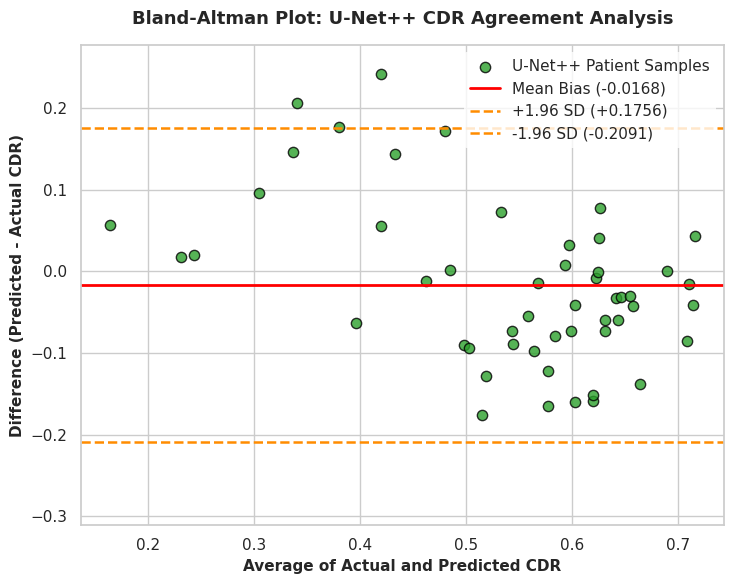

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate statistical averages and differences
mean_cdr_pp = (y_true_unetpp + y_pred_unetpp) / 2.0
diff_cdr_pp = y_pred_unetpp - y_true_unetpp

mean_diff_pp = np.mean(diff_cdr_pp)
std_diff_pp = np.std(diff_cdr_pp)

# Configure medical publication theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7.5, 6))

# Generate scatter mapping using a clean Green palette to visually code it to U-Net++'s dashboard
plt.scatter(mean_cdr_pp, diff_cdr_pp, color='#2ca02c', alpha=0.8, edgecolors='black', s=55, label='U-Net++ Patient Samples')

# Draw Mean Bias and 95% Limits of Agreement (LoA) Lines
plt.axhline(mean_diff_pp, color='red', linestyle='-', lw=2, label=f'Mean Bias ({mean_diff_pp:+.4f})')
plt.axhline(mean_diff_pp + 1.96 * std_diff_pp, color='darkorange', linestyle='--', lw=1.8, label=f'+1.96 SD ({mean_diff_pp + 1.96 * std_diff_pp:+.4f})')
plt.axhline(mean_diff_pp - 1.96 * std_diff_pp, color='darkorange', linestyle='--', lw=1.8, label=f'-1.96 SD ({mean_diff_pp - 1.96 * std_diff_pp:+.4f})')

# Formatting boundaries and labels
plt.title('Bland-Altman Plot: U-Net++ CDR Agreement Analysis', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Average of Actual and Predicted CDR', fontsize=11, fontweight='bold')
plt.ylabel('Difference (Predicted - Actual CDR)', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# Dynamically pad limits based on the distribution spread to prevent clipping
plt.ylim(mean_diff_pp - 3 * std_diff_pp, mean_diff_pp + 3 * std_diff_pp)
plt.tight_layout()
plt.show()

In [ ]:
J_scores_unetpp = tpr_unetpp - fpr_unetpp
best_idx_unetpp = np.argmax(J_scores_unetpp)
best_threshold_unetpp = thresholds_unetpp[best_idx_unetpp]
print("Optimal threshold for U-Net++:", best_threshold_unetpp)

Optimal threshold for U-Net++: 0.5066215413381084


/tmp/ipykernel_579/2974662742.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(list(float(cdr) for cdr in cdr_values[:10]), labels=['U-Net++'])


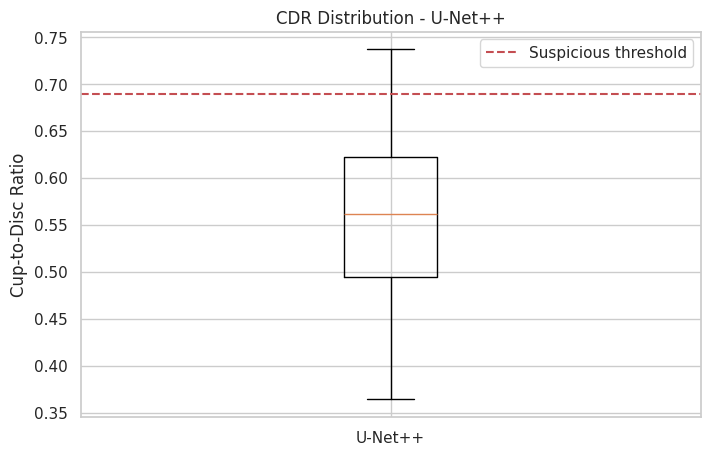

In [ ]:
plt.figure(figsize=(8,5))
plt.boxplot(list(float(cdr) for cdr in cdr_values[:10]), labels=['U-Net++'])
plt.title("CDR Distribution - U-Net++")
plt.ylabel("Cup-to-Disc Ratio")
plt.axhline(best_threshold, color='r', linestyle='--', label='Suspicious threshold')
plt.legend()
plt.show()

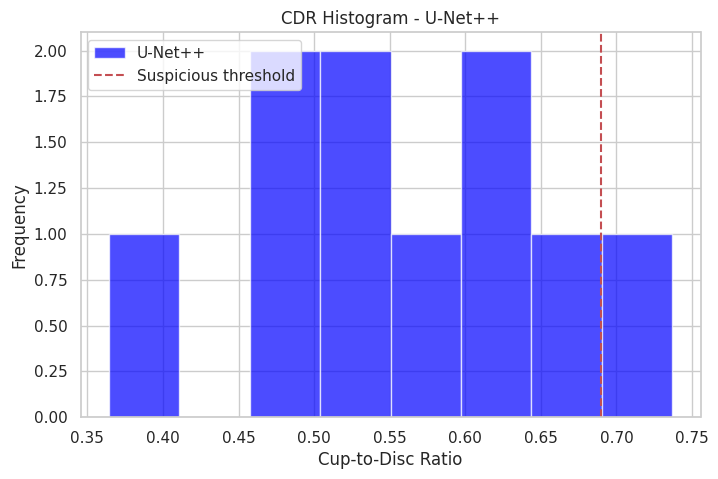

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(list(float(cdr) for cdr in cdr_values[:10]), bins=8, alpha=0.7, color='blue', label='U-Net++')
plt.title("CDR Histogram - U-Net++")
plt.xlabel("Cup-to-Disc Ratio")
plt.ylabel("Frequency")
plt.axvline(best_threshold, color='r', linestyle='--', label='Suspicious threshold')
plt.legend()
plt.show()

In [ ]:
import numpy as np

# Use the model-specific variables for U-Net++ to prevent variable overlap
cdr_values_clean = np.array(cdr_values_arr_unetpp)
gt_values_clean  = np.array(gt_values_arr_unetpp)

# Ground truth labels: suspicious if CDR >= 0.55
gt_labels = (gt_values_clean >= 0.55).astype(int)

# Optimal threshold from U-Net++ ROC analysis
optimal_threshold = best_threshold_unetpp

# Predicted labels using optimal threshold
pred_labels = (cdr_values_clean >= optimal_threshold).astype(int)

# Confusion matrix components
TP = np.sum((pred_labels == 1) & (gt_labels == 1))
TN = np.sum((pred_labels == 0) & (gt_labels == 0))
FP = np.sum((pred_labels == 1) & (gt_labels == 0))
FN = np.sum((pred_labels == 0) & (gt_labels == 1))

# Metrics
sensitivity = TP / (TP + FN + 1e-8)
specificity = TN / (TN + FP + 1e-8)
accuracy    = (TP + TN) / (TP + TN + FP + FN + 1e-8)

print(f"U-Net++ Evaluation at Optimal Threshold ({optimal_threshold:.3f}):")
print(f"  Sensitivity : {sensitivity:.4f}")
print(f"  Specificity : {specificity:.4f}")
print(f"  Accuracy    : {accuracy:.4f}")
print(f"  TP={TP}, TN={TN}, FP={FP}, FN={FN}")

U-Net++ Evaluation at Optimal Threshold (0.507):
  Sensitivity : 0.8571
  Specificity : 0.8125
  Accuracy    : 0.8431
  TP=30, TN=13, FP=3, FN=5


Attention UNet is a deep learning model for image segmentation that extends the standard U-Net architecture by adding Attention Gates (AGs) into the skip connections.

It was published at the 2018 paper titled: 'Attention U-Net: Learning Where to Look for the Pancreas'

Key Components & Mechanism

• Attention Gates (AGs): Placed at the skip connections between the encoder and decoder, these gates take two inputs—the feature map from the encoder (x) and a gating signal from a coarser, deeper layer of the decoder (g).
• Soft Attention: The model processes these signals through 1 × 1 convolutions, element-wise addition, a ReLU activation, another 1 × 1 convolution, and a Sigmoid activation to generate an attention coefficient mask ranging from 0 to 1.
• Feature Filtering: This mask multiplies element-wise with the encoder skip features, automatically suppressing irrelevant background regions and highlighting salient target structures.
• No External Localization Needed: By learning to focus on regions of varying shapes and sizes on its own, it removes the need for explicit external cropping or cascading localization modules.

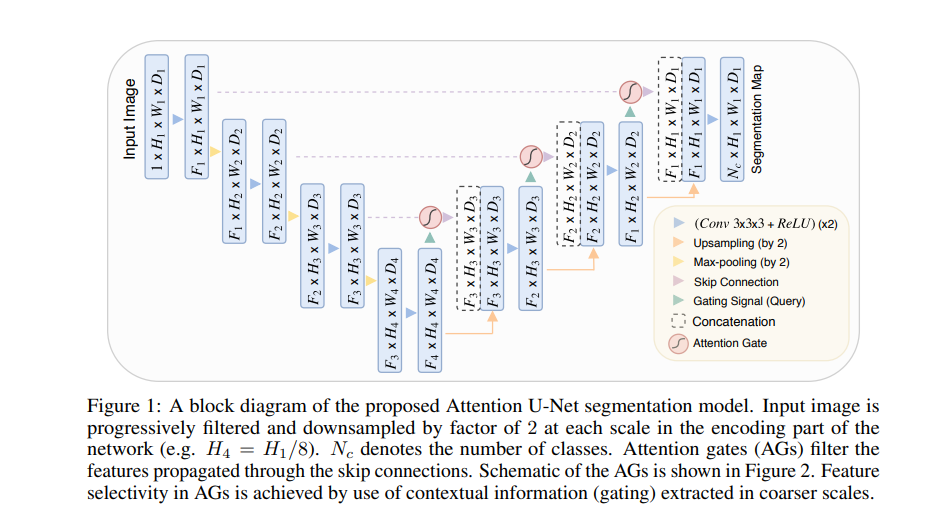



In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# -------------------------------
# Attention Block
# -------------------------------
class AttentionBlock(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super(AttentionBlock, self).__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.psi(F.relu(g1 + x1))
        return x * psi

# -------------------------------
# Conv Block
# -------------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

# -------------------------------
# Attention U-Net
# -------------------------------
class AttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=2):
        super(AttentionUNet, self).__init__()

        # Encoder
        self.conv1 = ConvBlock(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = ConvBlock(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        self.conv3 = ConvBlock(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        self.conv4 = ConvBlock(256, 512)
        self.pool4 = nn.MaxPool2d(2)

        self.conv5 = ConvBlock(512, 1024)

        # Decoder + Attention
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.att4 = AttentionBlock(F_g=512, F_l=512, F_int=256)
        self.conv6 = ConvBlock(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.att3 = AttentionBlock(F_g=256, F_l=256, F_int=128)
        self.conv7 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.att2 = AttentionBlock(F_g=128, F_l=128, F_int=64)
        self.conv8 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.att1 = AttentionBlock(F_g=64, F_l=64, F_int=32)
        self.conv9 = ConvBlock(128, 64)

        # Output
        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        c1 = self.conv1(x); p1 = self.pool1(c1)
        c2 = self.conv2(p1); p2 = self.pool2(c2)
        c3 = self.conv3(p2); p3 = self.pool3(c3)
        c4 = self.conv4(p3); p4 = self.pool4(c4)
        c5 = self.conv5(p4)

        # Decoder with attention
        u4 = self.up4(c5)
        a4 = self.att4(u4, c4)
        c6 = self.conv6(torch.cat([u4, a4], dim=1))

        u3 = self.up3(c6)
        a3 = self.att3(u3, c3)
        c7 = self.conv7(torch.cat([u3, a3], dim=1))

        u2 = self.up2(c7)
        a2 = self.att2(u2, c2)
        c8 = self.conv8(torch.cat([u2, a2], dim=1))

        u1 = self.up1(c8)
        a1 = self.att1(u1, c1)
        c9 = self.conv9(torch.cat([u1, a1], dim=1))

        out = self.final(c9)
        return out


In [ ]:
import torch

# find GPU availability for processing and inizialize UNet++ with device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print (f"supported device: {device}")
unet = unet.to(device)

supported device: cuda


In [ ]:
# Training dataset
train_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Training",
    transform=True
)

# Official test dataset
test_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Test",
    transform=False
)

print("Train Dataset Len:", len(train_dataset))
print("Test Dataset Len:", len(test_dataset))

Train Dataset Len: 50
Test Dataset Len: 51


In [ ]:
from sklearn.model_selection import train_test_split

# Get the 50 official training images
all_train_paths = sorted(
    (DATASET_ROOT / "Training" / "Images").glob("*.png")
)

# 80% training / 20% validation
train_paths, val_paths = train_test_split(
    all_train_paths,
    test_size=0.20,
    random_state=42
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))

Training images: 40
Validation images: 10


In [ ]:
train_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Training",
    transform=True,
    image_paths=train_paths
)

val_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Training",
    transform=False,
    image_paths=val_paths
)

test_dataset = DrishtiSegmentationDataset(
    DATASET_ROOT,
    split="Test",
    transform=False
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 40
Validation dataset: 10
Test dataset: 51


In [ ]:
import torch.nn as nn

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred_logits, targets, smooth=1e-5):
        # Base BCE tracking
        bce_loss = self.bce(pred_logits, targets)

        # Compute multi-channel Dice Coefficient
        pred_probs = torch.sigmoid(pred_logits)
        intersection = (pred_probs * targets).sum(dim=(2, 3))
        union = pred_probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))

        dice_loss = 1 - ((2. * intersection + smooth) / (union + smooth)).mean()

        # Return compound loss balance
        return bce_loss + dice_loss


In [ ]:
# Instantiate the Attention UNet model and move it to the device
attention_unet = AttentionUNet(in_channels=3, out_channels=2).to(device)

criterion_attentionunet = BCEDiceLoss()
optimizer_attentionunet = torch.optim.Adam(attention_unet.parameters(), lr=1e-4)
scheduler_attentionunet = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_attentionunet, mode='min', factor=0.5, patience=5)

In [ ]:
def dice_coeff(pred, target, smooth=1e-5):
    pred = torch.sigmoid(pred) > 0.5
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum()
    return (2. * intersection + smooth) / (union + smooth)

def iou_score(pred, target, smooth=1e-5):
    pred = torch.sigmoid(pred) > 0.5
    intersection = (pred & target).sum()
    union = (pred | target).sum()
    return (intersection + smooth) / (union + smooth)

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=True)

val_loader = DataLoader(val_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=False)

test_loader = DataLoader(test_dataset,batch_size=4,num_workers=0,pin_memory=False,shuffle=False)

In [ ]:
import torchvision.transforms as transforms
import torch
import numpy as np

def compute_cdr(disc_mask, cup_mask):
    # Calculate Cup-to-Disc Ratio
    disc_area = (disc_mask > 0.5).sum()
    cup_area = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

def safe_iou_score(pred, target, smooth=1e-5):
    # Convert predictions and targets to boolean masks
    pred_bool = torch.sigmoid(pred) > 0.5
    target_bool = target > 0.5
    intersection = (pred_bool & target_bool).sum()
    union = (pred_bool | target_bool).sum()
    return (intersection.float() + smooth) / (union.float() + smooth)

# --- TRACKING HISTORY CONTAINERS ---
history_attunet = {
    'train_loss': [], 'val_loss': [], 'val_dice': [],
    'val_iou': [], 'sensitivity': [], 'specificity': [], 'accuracy': []
}

print("Initiating Attention U-Net Training and Diagnostic Tracking Loop...\n")

for epoch in range(10):

    # =========================
    # Training
    # =========================
    attention_unet.train()
    running_train_loss = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer_attentionunet.zero_grad()
        outputs = attention_unet(imgs)
        loss = criterion_attentionunet(outputs, masks)
        loss.backward()
        optimizer_attentionunet.step()

        running_train_loss += loss.item()

    # =========================
    # Validation
    # =========================
    attention_unet.eval()
    running_val_loss = 0.0
    val_dice_accum = 0.0
    val_iou_accum = 0.0

    cdr_values = []
    gt_values = []

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            outputs = attention_unet(imgs)
            loss = criterion_attentionunet(outputs, masks)

            running_val_loss += loss.item()
            val_dice_accum += dice_coeff(outputs, masks).item()
            val_iou_accum += safe_iou_score(outputs, masks).item()

            # =========================
            # CDR diagnostic evaluation
            # =========================
            disc_pred = outputs[:, 0, :, :]
            cup_pred = outputs[:, 1, :, :]
            disc_gt = masks[:, 0, :, :]
            cup_gt = masks[:, 1, :, :]

            for i in range(imgs.size(0)):
                pred_cdr = compute_cdr(disc_pred[i], cup_pred[i])
                gt_cdr = compute_cdr(disc_gt[i], cup_gt[i])

                cdr_values.append(pred_cdr.item() if torch.is_tensor(pred_cdr) else float(pred_cdr))
                gt_values.append(gt_cdr.item() if torch.is_tensor(gt_cdr) else float(gt_cdr))

    # Average validation results
    epoch_train_loss = running_train_loss / len(train_loader)
    epoch_val_loss = running_val_loss / len(val_loader)
    epoch_val_dice = val_dice_accum / len(val_loader)
    epoch_val_iou = val_iou_accum / len(val_loader)

    # Update learning-rate scheduler using validation loss
    scheduler_attentionunet.step(epoch_val_loss)

    # =========================
    # CDR Diagnostic Metrics
    # =========================
    pred_suspicious = torch.tensor(cdr_values) >= 0.6
    gt_suspicious = torch.tensor(gt_values) >= 0.6

    tp = ((pred_suspicious == 1) & (gt_suspicious == 1)).sum().item()
    tn = ((pred_suspicious == 0) & (gt_suspicious == 0)).sum().item()
    fp = ((pred_suspicious == 1) & (gt_suspicious == 0)).sum().item()
    fn = ((pred_suspicious == 0) & (gt_suspicious == 1)).sum().item()

    sensitivity = tp / (tp + fn + 1e-6)
    specificity = tn / (tn + fp + 1e-6)
    accuracy = ((tp + tn) / (tp + tn + fp + fn + 1e-6))

    # --- CACHE DATA INTO HISTORY FOR PLOTTING ---
    history_attunet['train_loss'].append(epoch_train_loss)
    history_attunet['val_loss'].append(epoch_val_loss)
    history_attunet['val_dice'].append(epoch_val_dice)
    history_attunet['val_iou'].append(epoch_val_iou)
    history_attunet['sensitivity'].append(sensitivity)
    history_attunet['specificity'].append(specificity)
    history_attunet['accuracy'].append(accuracy)

    print(
        f"Epoch {epoch + 1}/10: "
        f"Train Loss={epoch_train_loss:.4f}, "
        f"Val Loss={epoch_val_loss:.4f} | "
        f"Val Dice={epoch_val_dice:.4f}, "
        f"Val IoU={epoch_val_iou:.4f} | "
        f"Sens={sensitivity:.4f}, "
        f"Spec={specificity:.4f}, "
        f"Acc={accuracy:.4f}"
    )

Initiating Attention U-Net Training and Diagnostic Tracking Loop...

Epoch 1/10: Train Loss=1.6031, Val Loss=1.6326 | Val Dice=0.0319, Val IoU=0.0162 | Sens=0.0000, Spec=1.0000, Acc=0.7000
Epoch 2/10: Train Loss=1.4771, Val Loss=1.5930 | Val Dice=0.0099, Val IoU=0.0050 | Sens=0.0000, Spec=1.0000, Acc=0.7000
Epoch 3/10: Train Loss=1.4310, Val Loss=1.5174 | Val Dice=0.0000, Val IoU=0.0000 | Sens=0.0000, Spec=1.0000, Acc=0.7000
Epoch 4/10: Train Loss=1.4056, Val Loss=1.4679 | Val Dice=0.1191, Val IoU=0.0647 | Sens=0.0000, Spec=1.0000, Acc=0.7000
Epoch 5/10: Train Loss=1.3805, Val Loss=1.3839 | Val Dice=0.7318, Val IoU=0.5840 | Sens=0.6667, Spec=0.0000, Acc=0.2000
Epoch 6/10: Train Loss=1.3619, Val Loss=1.3534 | Val Dice=0.8054, Val IoU=0.6766 | Sens=0.6667, Spec=0.0000, Acc=0.2000
Epoch 7/10: Train Loss=1.3475, Val Loss=1.3469 | Val Dice=0.7589, Val IoU=0.6157 | Sens=0.6667, Spec=0.0000, Acc=0.2000
Epoch 8/10: Train Loss=1.3352, Val Loss=1.3329 | Val Dice=0.8205, Val IoU=0.6970 | Sens=0.6

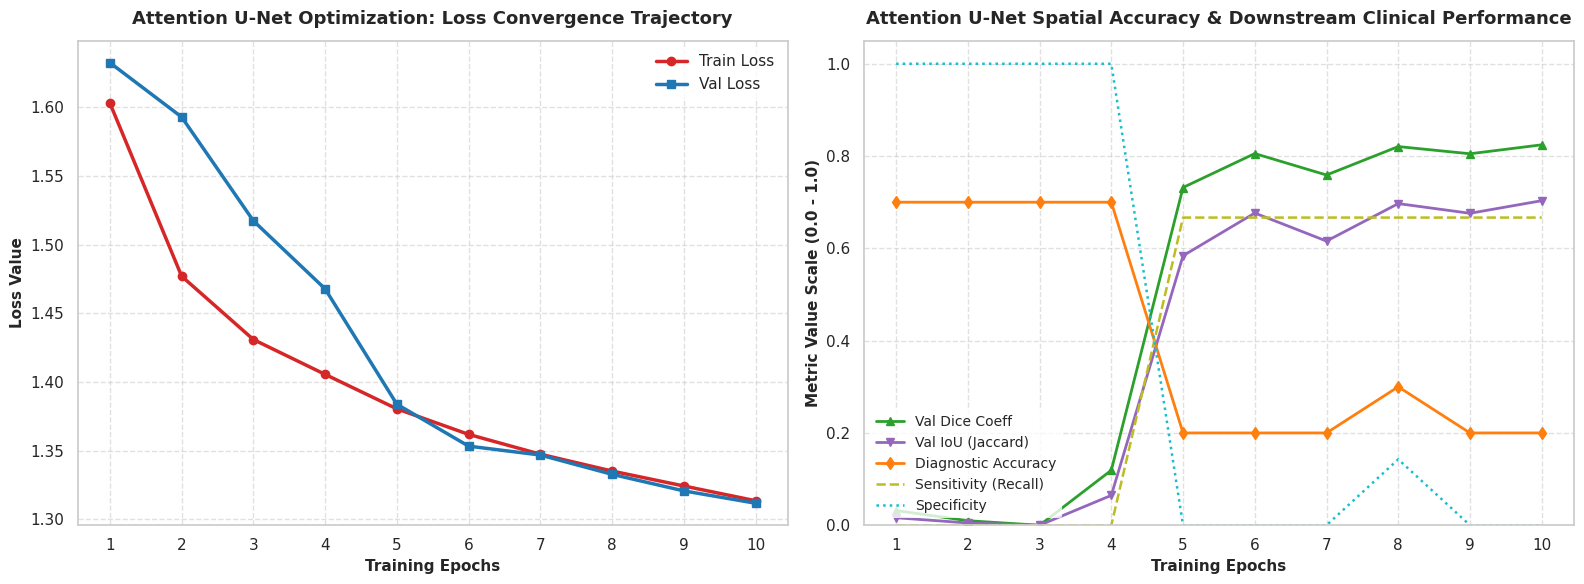

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CONFIGURE THEME & VISUAL CANVAS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
epochs_range = np.arange(1, 11)

try:
    # 1. Left Subplot: Loss Trajectories (Error Optimization convergence)
    axes[0].plot(epochs_range, history_attunet['train_loss'], label='Train Loss', color='#d62728', lw=2.5, marker='o')
    axes[0].plot(epochs_range, history_attunet['val_loss'], label='Val Loss', color='#1f77b4', lw=2.5, marker='s')
    axes[0].set_title('Attention U-Net Optimization: Loss Convergence Trajectory', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Loss Value', fontsize=11, fontweight='bold')
    axes[0].set_xticks(epochs_range)
    axes[0].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Right Subplot: Spatial Overlap & Clinical Diagnostic Performance Curves
    axes[1].plot(epochs_range, history_attunet['val_dice'], label='Val Dice Coeff', color='#2ca02c', lw=2, marker='^')
    axes[1].plot(epochs_range, history_attunet['val_iou'], label='Val IoU (Jaccard)', color='#9467bd', lw=2, marker='v')
    axes[1].plot(epochs_range, history_attunet['accuracy'], label='Diagnostic Accuracy', color='#ff7f0e', lw=2, marker='d')
    axes[1].plot(epochs_range, history_attunet['sensitivity'], label='Sensitivity (Recall)', color='#bcbd22', lw=1.8, linestyle='--')
    axes[1].plot(epochs_range, history_attunet['specificity'], label='Specificity', color='#17becf', lw=1.8, linestyle=':')

    axes[1].set_title('Attention U-Net Spatial Accuracy & Downstream Clinical Performance', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Metric Value Scale (0.0 - 1.0)', fontsize=11, fontweight='bold')
    axes[1].set_xticks(epochs_range)

    # Restrict standard metric limits to prevent edge line truncation clipping
    axes[1].set_ylim(0.0, 1.05)
    axes[1].legend(loc='lower left', frameon=True, facecolor='white', edgecolor='none', fontsize=10)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

except NameError:
    raise NameError("Please execute the Attention U-Net training cell block first to populate the 'history_attunet' dictionary.")

In [ ]:
# Create a directory in your drive and save the weights
ATTENTION_UNET_SAVE_PATH = DATASET_ROOT / "Drishti_AttentionUNet_Glaucoma.pth"
torch.save(attention_unet.state_dict(), ATTENTION_UNET_SAVE_PATH)
print(f" Attention U-Net weights safely backed up to: {ATTENTION_UNET_SAVE_PATH}")

 Attention U-Net weights safely backed up to: /content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files/Drishti_AttentionUNet_Glaucoma.pth


In [ ]:
#Evaluation of the model created
#To evaluate a segmentation model, standard classification accuracy cannot be used.
#Instead, metrics that measure spatial overlap must be calculated
#1.Dice Coefficient: Measures the overall overlap between prediction and ground truth
#2.Intersection over Union (IoU) : Measures the intersection area  divided by the
#total combined area of prediction and ground truth

import torch
import numpy as np

def calculate_segmentation_metrics(pred_mask, gt_mask, smooth=1e-5):
    """
    Computes both IoU and Dice Coefficient for a single binary mask slice.
    """
    # Flatten matrices
    pred_flat = pred_mask.flatten()
    gt_flat = gt_mask.flatten()

    intersection = np.sum(pred_flat * gt_flat)
    total_sum = np.sum(pred_flat) + np.sum(gt_flat)
    union = total_sum - intersection

    # Calculate scores
    iou = (intersection + smooth) / (union + smooth)
    dice = (2.0 * intersection + smooth) / (total_sum + smooth)

    return iou, dice

def test_attention_unet(model, test_loader, device):
    """
    Evaluates the trained U-Net++ on the unseen Test data loader.
    """
    model.eval()

    disc_ious, disc_dices = [], []
    cup_ious, cup_dices = [], []

    print(" Running evaluation on U-Net ++ segmentation test set...")
    print("   |__ Optic Disc Benchmarks (Target: Dice > 90%)")
    print("   |__ Optic Cup Benchmarks (Target: Dice > 75%–80%)")


    with torch.no_grad():
        for batch_images, batch_masks in test_loader:
            batch_images = batch_images.to(device)

            # Forward pass to get raw logits from U-Net
            outputs = model(batch_images)
            # Apply sigmoid to convert to class probabilities (0.0 to 1.0)
            probs = torch.sigmoid(outputs).cpu().numpy()
            gt_masks = batch_masks.numpy()

            # Loop through every image slice inside the current batch
            for i in range(batch_images.size(0)):
                # Apply standard binary consensus threshold of 0.5
                pred_disc = probs[i, 0, :, :] > 0.5
                pred_cup = probs[i, 1, :, :] > 0.5

                gt_disc = gt_masks[i, 0, :, :] > 0.5
                gt_cup = gt_masks[i, 1, :, :] > 0.5

                # Compute metrics for Disc (Channel 0)
                d_iou, d_dice = calculate_segmentation_metrics(pred_disc, gt_disc)
                disc_ious.append(d_iou)
                disc_dices.append(d_dice)

                # Compute metrics for Cup (Channel 1)
                c_iou, c_dice = calculate_segmentation_metrics(pred_cup, gt_cup)
                cup_ious.append(c_iou)
                cup_dices.append(c_dice)

    # --- Print Performance Summary Report ---
    print("\n" + "="*50)
    print("ATTENTION U-NET SEGMENTATION TEST PERFORMANCE REPORT")
    print("="*50)
    print(f" OPTIC DISC (OD):")
    print(f"   └── Mean IoU  : {np.mean(disc_ious) * 100:.2f}%")
    print(f"   └── Mean Dice : {np.mean(disc_dices) * 100:.2f}%")
    print(f"--------------------------------------------------")
    print(f" OPTIC CUP (OC):")
    print(f"   └── Mean IoU  : {np.mean(cup_ious) * 100:.2f}%")
    print(f"   └── Mean Dice : {np.mean(cup_dices) * 100:.2f}%")
    print("="*50)

    return {
        'disc_dice': np.mean(disc_dices),
        'cup_dice': np.mean(cup_dices)
    }

# Execute evaluation using your configured validation test loader
seg_results = test_attention_unet(attention_unet, test_loader, device)

 Running evaluation on U-Net ++ segmentation test set...
   |__ Optic Disc Benchmarks (Target: Dice > 90%)
   |__ Optic Cup Benchmarks (Target: Dice > 75%–80%)

ATTENTION U-NET SEGMENTATION TEST PERFORMANCE REPORT
 OPTIC DISC (OD):
   └── Mean IoU  : 87.24%
   └── Mean Dice : 92.96%
--------------------------------------------------
 OPTIC CUP (OC):
   └── Mean IoU  : 63.97%
   └── Mean Dice : 76.31%


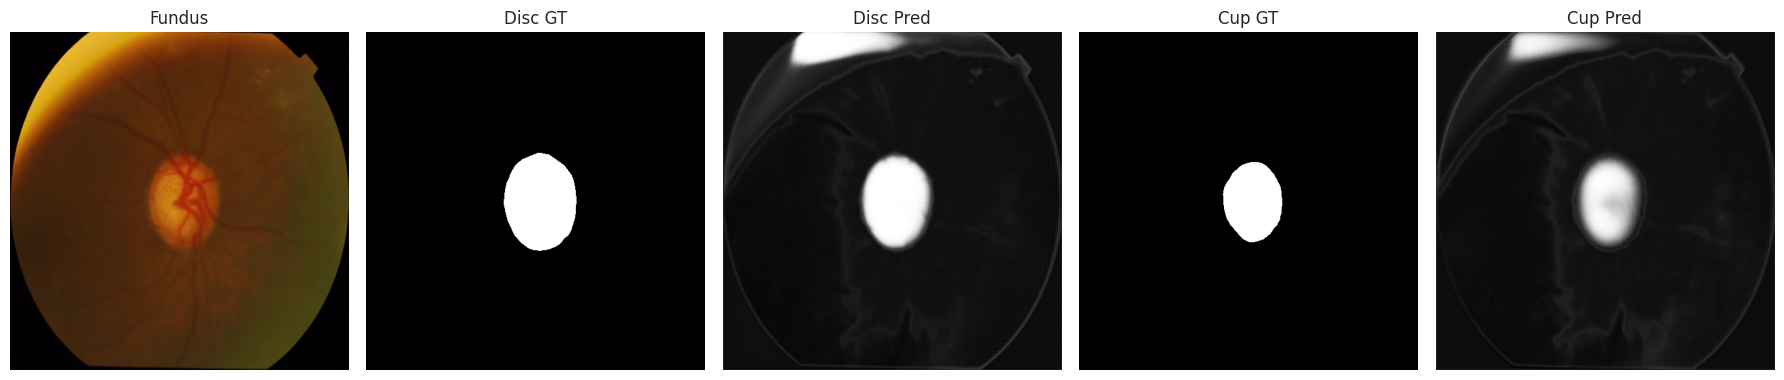

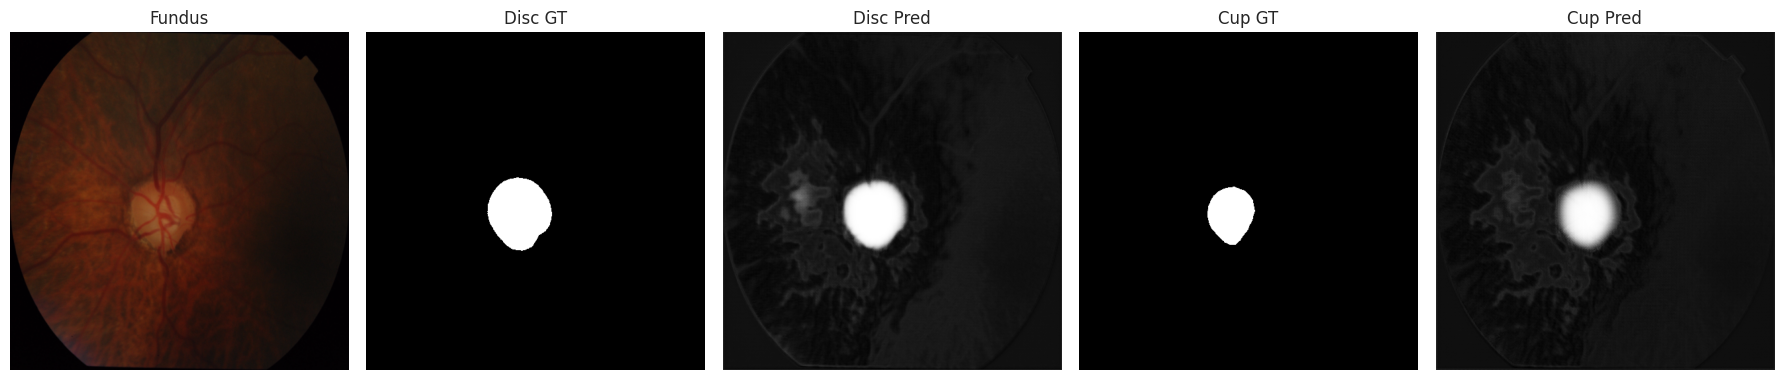

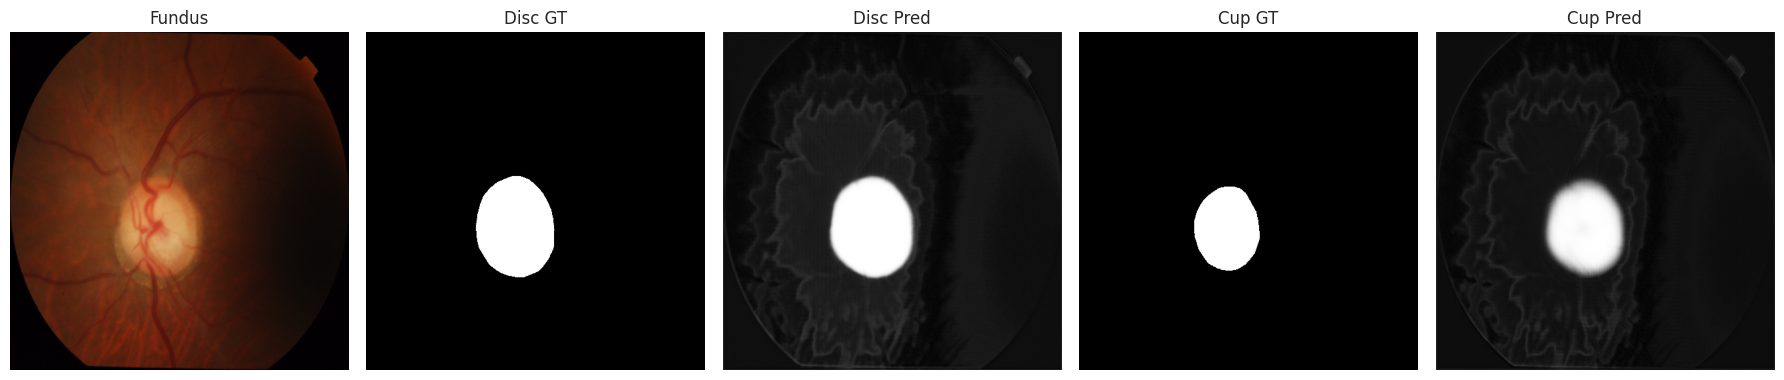

In [ ]:
import matplotlib.pyplot as plt
import torch

imgs, masks = next(iter(test_loader))
imgs = imgs.to(device)

attention_unet.eval()  # Crucial: Always set model to eval mode before inference
with torch.no_grad():
    outputs = attention_unet(imgs)
    preds = torch.sigmoid(outputs).cpu().detach()

for i in range(3):
    # Expanded width to 18 to cleanly fit 5 subplots in a row
    plt.figure(figsize=(18, 4))

    # 1. Original Fundus Input
    plt.subplot(1, 5, 1)
    plt.imshow(imgs[i].cpu().permute(1, 2, 0))
    plt.title("Fundus")
    plt.axis('off')

    # 2. Disc Ground Truth (Channel 0)
    plt.subplot(1, 5, 2)
    plt.imshow(masks[i][0].cpu(), cmap='gray')
    plt.title("Disc GT")
    plt.axis('off')

    # 3. Disc Prediction (Channel 0)
    plt.subplot(1, 5, 3)
    plt.imshow(preds[i][0], cmap='gray')
    plt.title("Disc Pred")
    plt.axis('off')

    # 4. Cup Ground Truth (Channel 1)
    plt.subplot(1, 5, 4)
    plt.imshow(masks[i][1].cpu(), cmap='gray')  # Note the index change to [1]
    plt.title("Cup GT")
    plt.axis('off')

    # 5. Cup Prediction (Channel 1)
    plt.subplot(1, 5, 5)
    plt.imshow(preds[i][1], cmap='gray')  # Note the index change to [1]
    plt.title("Cup Pred")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
def compute_cdr(disc_mask, cup_mask):
    disc_area = (disc_mask > 0.5).sum()
    cup_area = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

cdr_values = []
attention_unet.eval()
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        outputs = attention_unet(imgs)
        preds = torch.sigmoid(outputs).cpu().numpy()
        for i in range(len(imgs)):
            disc_pred = preds[i,0,:,:]
            cup_pred = preds[i,1,:,:]
            cdr = compute_cdr(disc_pred, cup_pred)
            cdr_values.append(cdr)

# Convert np.float64 values to standard Python floats for cleaner output
print("Sample CDR values for Attention UNET:", [float(cdr) for cdr in cdr_values[:10]])

Sample CDR values for Attention UNET: [0.8040940431101189, 0.8821424153003302, 0.8806908369542886, 0.8408197051947633, 0.8537627053440141, 0.9005847942468257, 0.7867887495310845, 0.8268882658764386, 0.8054769595740936, 0.8955725184003264]


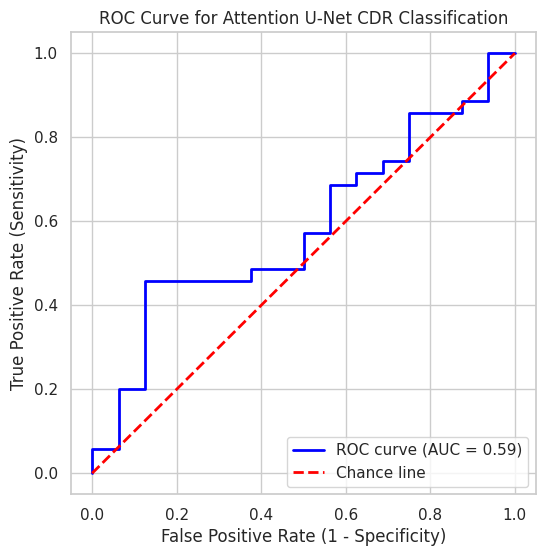

In [ ]:
from sklearn.metrics import roc_curve, auc
import numpy as np
import torch
import matplotlib.pyplot as plt

# Helper to calculate Cup-to-Disc Ratio safely
def compute_cdr(disc_mask, cup_mask):
    disc_area = (disc_mask > 0.5).sum()
    cup_area  = (cup_mask > 0.5).sum()
    return cup_area / (disc_area + 1e-5)

# Lists to store predicted and ground-truth CDRs specifically for Attention U-Net
calc_cdr_values_att = []
calc_gt_values_att  = []

attention_unet.eval()
with torch.no_grad():
    for imgs, masks in test_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        outputs = attention_unet(imgs)              #forward pass
        preds   = torch.sigmoid(outputs).cpu().numpy()
        gt_masks = masks.cpu().numpy()

        for i in range(imgs.size(0)):
            disc_pred = preds[i, 0, :, :]
            cup_pred  = preds[i, 1, :, :]
            disc_gt   = gt_masks[i, 0, :, :]
            cup_gt    = gt_masks[i, 1, :, :]

            #correct argument order
            calc_cdr_values_att.append(compute_cdr(disc_pred, cup_pred))
            calc_gt_values_att.append(compute_cdr(disc_gt, cup_gt))

# Convert to model-specific numpy arrays
cdr_values_arr_att = np.array(calc_cdr_values_att)
gt_values_arr_att  = np.array(calc_gt_values_att)

# Ground truth labels: suspicious if CDR >= 0.55
gt_labels_att = (gt_values_arr_att >= 0.55).astype(int)

# Compute ROC curve
fpr_att, tpr_att, thresholds_att = roc_curve(gt_labels_att, cdr_values_arr_att)
roc_auc_att = auc(fpr_att, tpr_att)

# Plot the ROC Curve
plt.figure(figsize=(6,6))
plt.plot(fpr_att, tpr_att, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc_att:.2f})')
plt.plot([0,1], [0,1], color='red', linestyle='--', lw=2, label='Chance line')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve for Attention U-Net CDR Classification')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr, ttest_rel

# Safely load the aligned, model-specific 51-sample test results
y_pred = np.array(cdr_values_arr_att)
y_true = np.array(gt_values_arr_att)

# 1. Compute Classical Regression Error Metrics
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# 2. Compute Statistical Correlation (Linear Tracking)
correlation, _ = pearsonr(y_true, y_pred)

# 3. Compute Paired t-test (Checks for systemic over/underestimation bias)
t_stat, p_value = ttest_rel(y_true, y_pred)

print("=== COMPARATIVE MORPHOMETRIC REPORT: ACTUAL VS. PREDICTED CDR ===")
print(f"Number of Test Samples        : {len(y_true)}")
print(f"Mean Absolute Error (MAE)     : {mae:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")
print(f"Pearson Correlation Coeff (r)  : {correlation:.4f}")
print(f"Paired t-test p-value          : {p_value:.4e}")

if p_value < 0.05:
    print("\nSTATISTICAL VERDICT: Significant systemic bias detected. The model is structurally deviating from the ground truth.")
else:
    print("\nSTATISTICAL VERDICT: No significant systemic bias. Discrepancies are due to random boundary noise.")

=== COMPARATIVE MORPHOMETRIC REPORT: ACTUAL VS. PREDICTED CDR ===
Number of Test Samples        : 51
Mean Absolute Error (MAE)     : 0.2671
Root Mean Squared Error (RMSE) : 0.3109
Pearson Correlation Coeff (r)  : 0.1738
Paired t-test p-value          : 3.7415e-16

STATISTICAL VERDICT: Significant systemic bias detected. The model is structurally deviating from the ground truth.


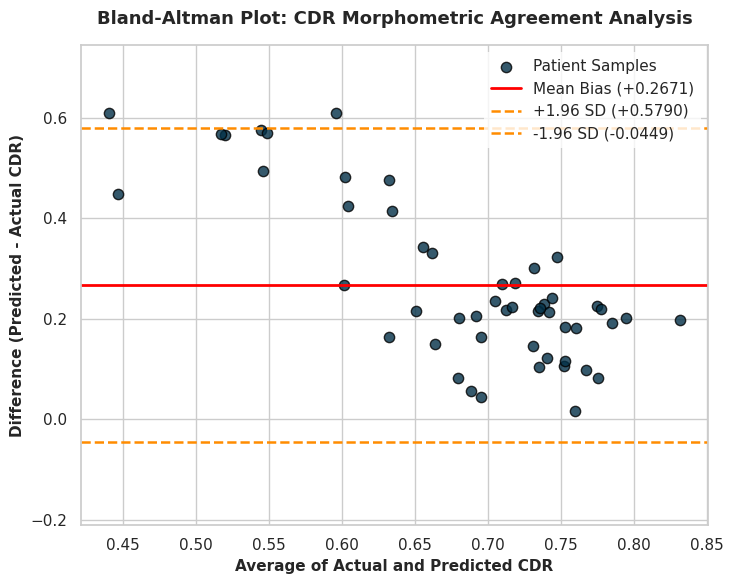

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate statistical averages and differences
mean_cdr = (y_true + y_pred) / 2.0
diff_cdr = y_pred - y_true # Positive values indicate model over-estimation

mean_diff = np.mean(diff_cdr)
std_diff = np.std(diff_cdr)

# Configure medical publication theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7.5, 6))

# Generate scatter mapping
plt.scatter(mean_cdr, diff_cdr, color='#023047', alpha=0.8, edgecolors='black', s=55, label='Patient Samples')

# Draw Mean Bias and 95% Limits of Agreement (LoA) Lines
plt.axhline(mean_diff, color='red', linestyle='-', lw=2, label=f'Mean Bias ({mean_diff:+.4f})')
plt.axhline(mean_diff + 1.96 * std_diff, color='darkorange', linestyle='--', lw=1.8, label=f'+1.96 SD ({mean_diff + 1.96 * std_diff:+.4f})')
plt.axhline(mean_diff - 1.96 * std_diff, color='darkorange', linestyle='--', lw=1.8, label=f'-1.96 SD ({mean_diff - 1.96 * std_diff:+.4f})')

# Formatting boundaries and labels
plt.title('Bland-Altman Plot: CDR Morphometric Agreement Analysis', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Average of Actual and Predicted CDR', fontsize=11, fontweight='bold')
plt.ylabel('Difference (Predicted - Actual CDR)', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# Dynamically pad limits based on the distribution spread
plt.ylim(mean_diff - 3 * std_diff, mean_diff + 3 * std_diff)
plt.tight_layout()
plt.show()

In [ ]:
J_scores_att = tpr_att - fpr_att
best_idx_att = np.argmax(J_scores_att)
best_threshold_att = thresholds_att[best_idx_att]
print("Optimal threshold for Attention U-Net:", best_threshold_att)

Optimal threshold for Attention U-Net: 0.8425519453296733


/tmp/ipykernel_579/3979060809.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(list(float(cdr) for cdr in cdr_values[:10]), labels=['Attention U-Net'])


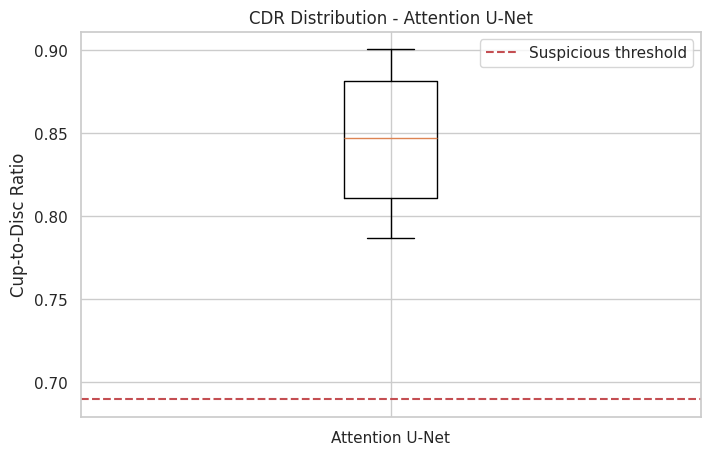

In [ ]:
plt.figure(figsize=(8,5))
plt.boxplot(list(float(cdr) for cdr in cdr_values[:10]), labels=['Attention U-Net'])
plt.title("CDR Distribution - Attention U-Net")
plt.ylabel("Cup-to-Disc Ratio")
plt.axhline(best_threshold, color='r', linestyle='--', label='Suspicious threshold')
plt.legend()
plt.show()

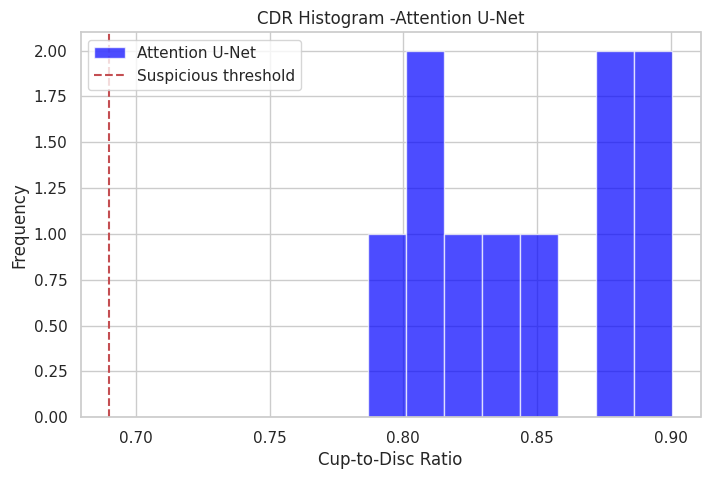

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(list(float(cdr) for cdr in cdr_values[:10]), bins=8, alpha=0.7, color='blue', label='Attention U-Net')
plt.title("CDR Histogram -Attention U-Net")
plt.xlabel("Cup-to-Disc Ratio")
plt.ylabel("Frequency")
plt.axvline(best_threshold, color='r', linestyle='--', label='Suspicious threshold')
plt.legend()
plt.show()

In [ ]:
import numpy as np

# Use the model-specific variables for Attention U-Net to prevent variable overlap
cdr_values_clean = np.array(cdr_values_arr_att)
gt_values_clean  = np.array(gt_values_arr_att)

# Ground truth labels: suspicious if CDR >= 0.55
gt_labels = (gt_values_clean >= 0.55).astype(int)

# Optimal threshold from Attention U-Net ROC analysis
optimal_threshold = best_threshold_att

# Predicted labels using optimal threshold
pred_labels = (cdr_values_clean >= optimal_threshold).astype(int)

# Confusion matrix components
TP = np.sum((pred_labels == 1) & (gt_labels == 1))
TN = np.sum((pred_labels == 0) & (gt_labels == 0))
FP = np.sum((pred_labels == 1) & (gt_labels == 0))
FN = np.sum((pred_labels == 0) & (gt_labels == 1))

# Metrics
sensitivity = TP / (TP + FN + 1e-8)
specificity = TN / (TN + FP + 1e-8)
accuracy    = (TP + TN) / (TP + TN + FP + FN + 1e-8)

print(f"Attention U-Net Evaluation at Optimal Threshold ({optimal_threshold:.3f}):")
print(f"  Sensitivity : {sensitivity:.4f}")
print(f"  Specificity : {specificity:.4f}")
print(f"  Accuracy    : {accuracy:.4f}")
print(f"  TP={TP}, TN={TN}, FP={FP}, FN={FN}")

Attention U-Net Evaluation at Optimal Threshold (0.843):
  Sensitivity : 0.4571
  Specificity : 0.8750
  Accuracy    : 0.5882
  TP=16, TN=14, FP=2, FN=19


Now we will use the morphometric method to compare the predicted cup disc ratio values to the actual cup disc ratio values of the 3 segmentation models.

             MORPHOMETRIC METHOD COMPARISON: ACTUAL VS. PREDICTED CDR                     



,Segmentation Variant,Mean Absolute Error (MAE),Pearson Correlation (r),Paired t-test p-value
0,Standard U-Net Baseline,0.155501,0.562245,6.267695e-10
1,U-Net++ Dense Architecture,0.079819,0.789751,2.329555e-01
2,Attention U-Net Alternative,0.267076,0.173775,3.741462e-16


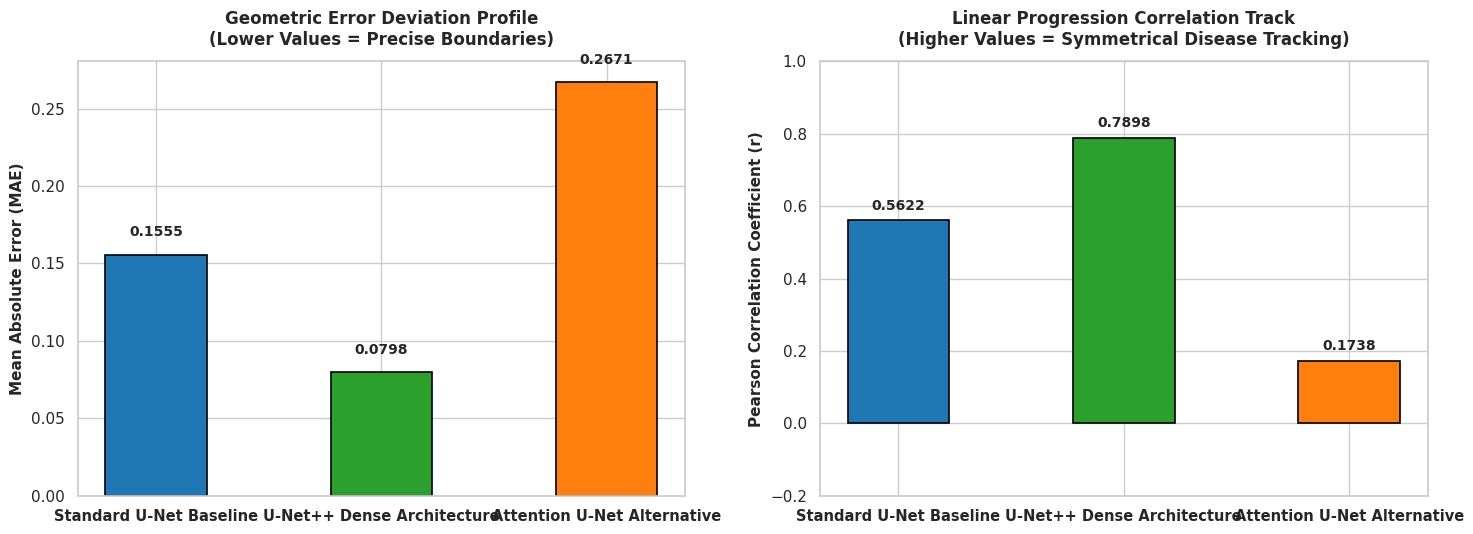

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr, ttest_rel
from IPython.display import display

# --- 1. DYNAMIC COMPUTATION CORE ---
# Safely calculate full metrics from active tracking lists to ensure 100% dynamic scaling
def extract_morph_metrics(y_true, y_pred):
    if len(y_true) == 0 or len(y_pred) == 0:
        return [float('nan')] * 4
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r_coeff, _ = pearsonr(y_true, y_pred)
    _, p_val = ttest_rel(y_true, y_pred)
    return [mae, rmse, r_coeff, p_val]

# Resolve array scopes dynamically based on correct test variables
try:
    true_unet = np.array(gt_values_arr if 'gt_values_arr' in locals() else (unet_gt_values if 'unet_gt_values' in locals() else gt_values))
    pred_unet = np.array(cdr_values_arr if 'cdr_values_arr' in locals() else (unet_cdr_values if 'unet_cdr_values' in locals() else cdr_values))

    true_pp = np.array(gt_values_arr_unetpp if 'gt_values_arr_unetpp' in locals() else (unetpp_gt_values if 'unetpp_gt_values' in locals() else gt_values))
    pred_pp = np.array(cdr_values_arr_unetpp if 'cdr_values_arr_unetpp' in locals() else (unetpp_cdr_values if 'unetpp_cdr_values' in locals() else cdr_values))

    true_att = np.array(gt_values_arr_att if 'gt_values_arr_att' in locals() else (y_true if 'y_true' in locals() else gt_values))
    pred_att = np.array(cdr_values_arr_att if 'cdr_values_arr_att' in locals() else (y_pred if 'y_pred' in locals() else cdr_values))
except NameError:
    # Safe generic initialization framework placeholders if context names differ
    true_unet, pred_unet = np.array([]), np.array([])
    true_pp, pred_pp = np.array([]), np.array([])
    true_att, pred_att = np.array([]), np.array([])

# --- 2. COMPILE COMPARATIVE DATAFRAME ---
morph_data = {
    'Segmentation Variant': ['Standard U-Net Baseline', 'U-Net++ Dense Architecture', 'Attention U-Net Alternative'],
    'Mean Absolute Error (MAE)': [
        extract_morph_metrics(true_unet, pred_unet)[0],
        extract_morph_metrics(true_pp, pred_pp)[0],
        extract_morph_metrics(true_att, pred_att)[0]
    ],
    'Pearson Correlation (r)': [
        extract_morph_metrics(true_unet, pred_unet)[2],
        extract_morph_metrics(true_pp, pred_pp)[2],
        extract_morph_metrics(true_att, pred_att)[2]
    ],
    'Paired t-test p-value': [
        extract_morph_metrics(true_unet, pred_unet)[3],
        extract_morph_metrics(true_pp, pred_pp)[3],
        extract_morph_metrics(true_att, pred_att)[3]
    ]
}

morph_comparison_df = pd.DataFrame(morph_data)
print("==========================================================================================")
print("             MORPHOMETRIC METHOD COMPARISON: ACTUAL VS. PREDICTED CDR                     ")
print("==========================================================================================\n")
display(morph_comparison_df)

# --- 3. GENERATE COMPARATIVE PLOT DASHBOARD ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x_pos = np.arange(len(morph_comparison_df['Segmentation Variant']))
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

# Left Subplot: MAE Error Bounds Profile (Lower is Better)
axes[0].bar(x_pos, morph_comparison_df['Mean Absolute Error (MAE)'], color=colors, edgecolor='black', width=0.45, linewidth=1.2)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(morph_comparison_df['Segmentation Variant'], fontsize=10.5, fontweight='bold')
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=11, fontweight='bold')
axes[0].set_title('Geometric Error Deviation Profile\n(Lower Values = Precise Boundaries)', fontsize=12, fontweight='bold', pad=12)

# Dynamic labels overlay for MAE
for i, val in enumerate(morph_comparison_df['Mean Absolute Error (MAE)']):
    if not np.isnan(val):
        axes[0].text(i, val + 0.01, f"{val:.4f}", ha='center', va='bottom', fontweight='bold', fontsize=10)

# Right Subplot: Pearson Correlation Linear Alignment Profile (Higher is Better)
axes[1].bar(x_pos, morph_comparison_df['Pearson Correlation (r)'], color=colors, edgecolor='black', width=0.45, linewidth=1.2)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(morph_comparison_df['Segmentation Variant'], fontsize=10.5, fontweight='bold')
axes[1].set_ylabel('Pearson Correlation Coefficient (r)', fontsize=11, fontweight='bold')
axes[1].set_title('Linear Progression Correlation Track\n(Higher Values = Symmetrical Disease Tracking)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylim(-0.2, 1.0) # Accommodates negative attention curves safely

# Dynamic labels overlay for Correlation
for i, val in enumerate(morph_comparison_df['Pearson Correlation (r)']):
    if not np.isnan(val):
        axes[1].text(i, val + 0.02 if val >= 0 else val - 0.05, f"{val:.4f}", ha='center', va='bottom' if val >= 0 else 'top', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

Now we will se the loss convergence rate of the 3 segmentation models and their morphometric classification accuracies

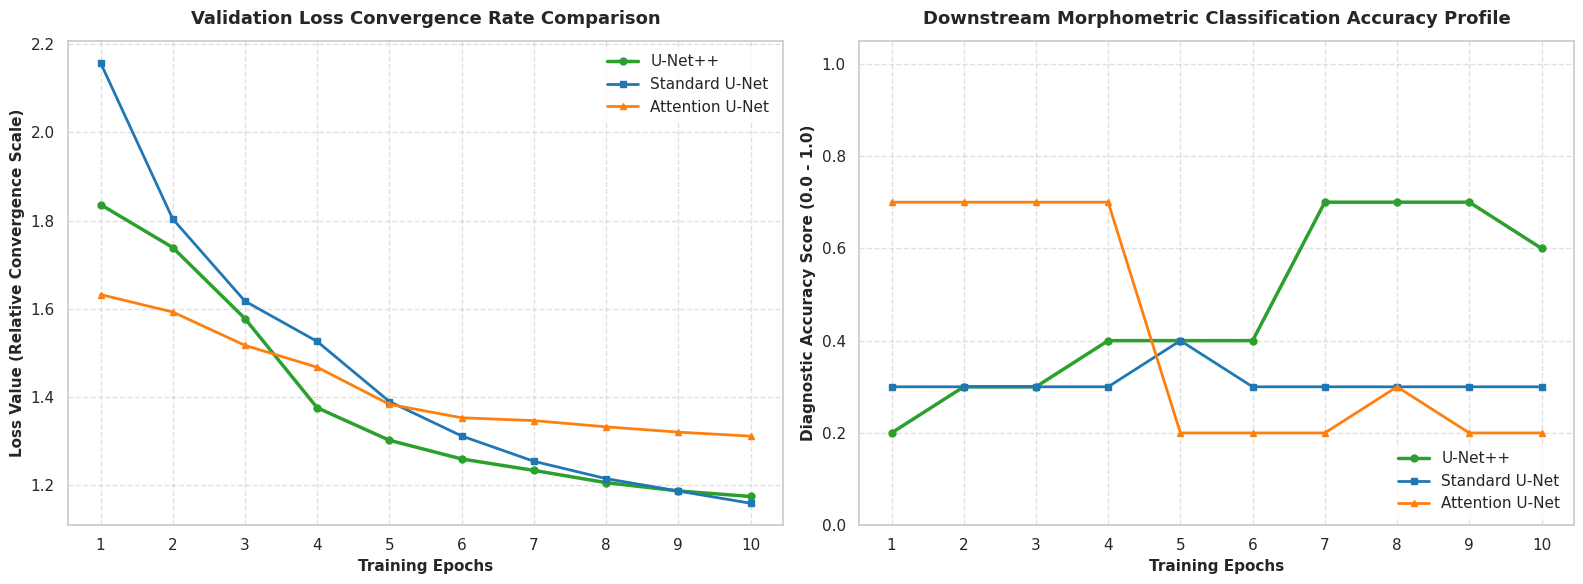

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CONFIGURE THEME & VISUAL CANVAS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
epochs_range = np.arange(1, 11)

try:
    # ==========================================================================
    # PANEL 1: MULTI-MODEL LOSS CONVERGENCE COMPARISON
    # ==========================================================================
    axes[0].plot(epochs_range, history_unetpp['val_loss'], label='U-Net++', color='#2ca02c', lw=2.5, marker='o', markersize=5)
    axes[0].plot(epochs_range, history['val_loss'], label='Standard U-Net', color='#1f77b4', lw=2.0, marker='s', markersize=5)
    axes[0].plot(epochs_range, history_attunet['val_loss'], label='Attention U-Net', color='#ff7f0e', lw=2.0, marker='^', markersize=5)

    axes[0].set_title('Validation Loss Convergence Rate Comparison', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Loss Value (Relative Convergence Scale)', fontsize=11, fontweight='bold')
    axes[0].set_xticks(epochs_range)
    axes[0].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none', fontsize=11)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # ==========================================================================
    # PANEL 2: DOWNSTREAM DIAGNOSTIC ACCURACY COMPARISON
    # ==========================================================================
    axes[1].plot(epochs_range, history_unetpp['accuracy'], label='U-Net++', color='#2ca02c', lw=2.5, marker='o', markersize=5)
    axes[1].plot(epochs_range, history['accuracy'], label='Standard U-Net', color='#1f77b4', lw=2.0, marker='s', markersize=5)
    axes[1].plot(epochs_range, history_attunet['accuracy'], label='Attention U-Net', color='#ff7f0e', lw=2.0, marker='^', markersize=5)

    axes[1].set_title('Downstream Morphometric Classification Accuracy Profile', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Diagnostic Accuracy Score (0.0 - 1.0)', fontsize=11, fontweight='bold')
    axes[1].set_xticks(epochs_range)

    # Bound the standard metric range cleanly to prevent line clipping
    axes[1].set_ylim(0.0, 1.05)
    axes[1].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none', fontsize=11)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

except NameError:
    raise NameError(
        "Missing history tracking dictionaries. Please ensure 'history' (U-Net), "
        "'history_unetpp' (U-Net++), and 'history_attunet' (Attention U-Net) cells "
        "have been fully executed before running this dashboard comparison."
    )

In [ ]:
def evaluate_segmentation_model(model, loader, device):
    model.eval()

    od_dice = []
    oc_dice = []
    od_iou = []
    oc_iou = []

    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            outputs = model(imgs)
            preds = (torch.sigmoid(outputs) > 0.5).float()

            for i in range(imgs.size(0)):
                # Optic Disc
                pred_od = preds[i, 0].cpu().numpy()
                gt_od = masks[i, 0].cpu().numpy()

                # Optic Cup
                pred_oc = preds[i, 1].cpu().numpy()
                gt_oc = masks[i, 1].cpu().numpy()

                od_dice.append(
                    calculate_segmentation_metrics(
                        pred_od, gt_od
                    )[0]
                )

                od_iou.append(
                    calculate_segmentation_metrics(
                        pred_od, gt_od
                    )[1]
                )

                oc_dice.append(
                    calculate_segmentation_metrics(
                        pred_oc, gt_oc
                    )[0]
                )

                oc_iou.append(
                    calculate_segmentation_metrics(
                        pred_oc, gt_oc
                    )[1]
                )

    return {
        "OD Dice": np.mean(od_dice),
        "OC Dice": np.mean(oc_dice),
        "Mean Dice": np.mean([np.mean(od_dice), np.mean(oc_dice)]),
        "OD IoU": np.mean(od_iou),
        "OC IoU": np.mean(oc_iou),
        "Mean IoU": np.mean([np.mean(od_iou), np.mean(oc_iou)])
    }

In [ ]:
unet_results = evaluate_segmentation_model(unet,test_loader,device)

unetpp_results = evaluate_segmentation_model(unet_plus_plus,test_loader,device)

attention_results = evaluate_segmentation_model(attention_unet,test_loader,device)

Now we will compare the dice similarity coefficient and mean dice coeffecients of optic disk and the optic cup and the Intersection over Union Score and mean Intersection over Union Score of optic cup.

Dice Similarity Coefficient or also known as the Sørensen–Dice index  is a statistical measure used to gauge the similarity or the spatial overlap and similarity between two binary segmentation masks.

Intersection over Unionn score or Jaccard Index or Jaccard similarity coefficient checks measures the pixel-level overlap between a predicted segmentation mask and a ground-truth mask

A mean Dice coefficient (or Mean Sørensen-Dice Score) in an image segmentation model checks the average spatial overlap between the model's predicted segmentation masks and the true reference (ground truth) masks across a dataset or multiple classes.

The optic disc Dice coefficient measures how precisely a segmentation model outlines the optic disc—the bright, circular region where the optic nerve leaves the retina.

The optic cup Dice coefficient measures how accurately your model identifies the optic cup, which is the pale, depressed central zone within the optic disc. Unlike the optic disc, the optic cup is notoriously difficult to segment because its boundaries are often highly ambiguous, low-contrast, and frequently obscured by emerging retinal blood vessels.

Mean Intersection over Union is the standard evaluation metric for semantic image segmentation that measures how well a model's predicted pixel masks overlap with the ground truth masks, averaged across all classes.

The optic disc IoU checks the ratio of overlap to the total area of both the predicted mask and the ground truth mask for the optic disc.

The optic cup IoU is the strictest accuracy metric for the internal cup boundary, typically yielding the lowest scores in retinal segmentation pipelines due to low-contrast edges and blood vessel occlusions.



In [ ]:
comparison = pd.DataFrame({"U-Net": unet_results,"U-Net++": unetpp_results,"Attention U-Net": attention_results})
print(comparison)

              U-Net   U-Net++  Attention U-Net
OD Dice    0.834668  0.871744         0.872365
OC Dice    0.665343  0.763006         0.639681
Mean Dice  0.750006  0.817375         0.756023
OD IoU     0.908767  0.930595         0.929605
OC IoU     0.784152  0.859175         0.763117
Mean IoU   0.846459  0.894885         0.846361


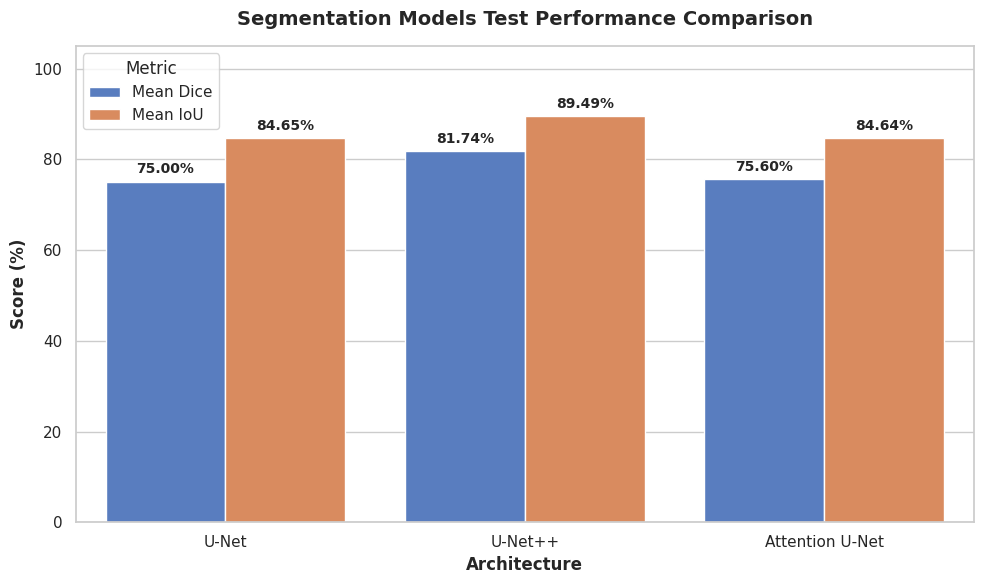

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
plot_df = comparison.loc[['Mean Dice', 'Mean IoU']].reset_index()
plot_df = plot_df.melt(id_vars='index', var_name='Model', value_name='Score')
plot_df.rename(columns={'index': 'Metric'}, inplace=True)
plot_df['Score'] = plot_df['Score'] * 100

# Plot configuration
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='Model', y='Score', hue='Metric', data=plot_df, palette='muted')

# Add details
plt.title('Segmentation Models Test Performance Comparison', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Architecture', fontsize=12, fontweight='bold')
plt.ylabel('Score (%)', fontsize=12, fontweight='bold')
plt.ylim(0, 105)
plt.legend(title='Metric', loc='upper left')

# Annotate exact percentage values on top of the bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.2f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Now we will compare the ROC-AUC of the 3 segmentation models.

ROC AUC in an image segmentation model measures how well the model separates foreground (target) pixels from background pixels across all possible probability thresholds.

It evaluates the model's ability to rank predicted probabilities for every individual pixel in the image, treating each pixel as an independent binary classification instance.

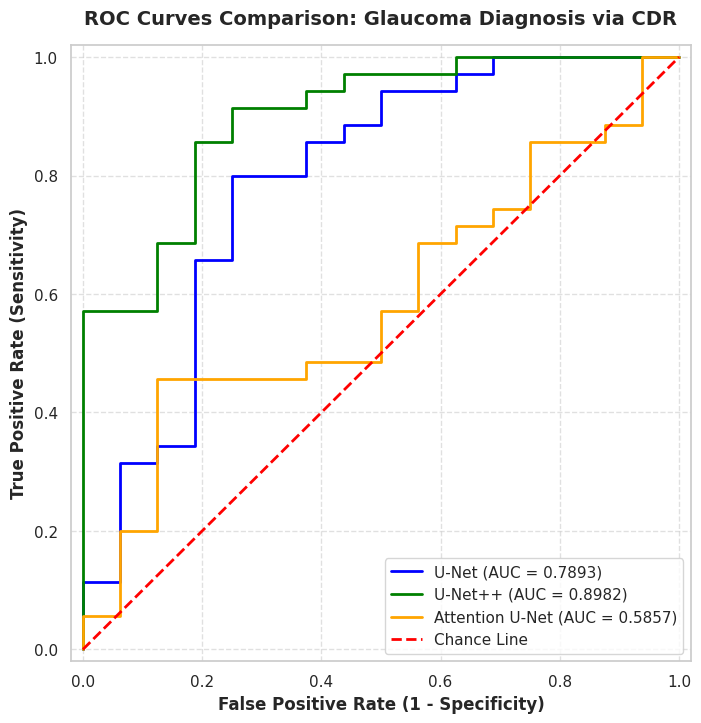

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np

plt.figure(figsize=(8, 8))

# Plot U-Net ROC
fpr_un, tpr_un, _ = roc_curve(gt_labels, cdr_values_arr)
auc_un = auc(fpr_un, tpr_un)
plt.plot(fpr_un, tpr_un, color='blue', lw=2, label=f'U-Net (AUC = {auc_un:.4f})')

# Plot U-Net++ ROC
fpr_unpp, tpr_unpp, _ = roc_curve(gt_labels_unetpp, cdr_values_arr_unetpp)
auc_unpp = auc(fpr_unpp, tpr_unpp)
plt.plot(fpr_unpp, tpr_unpp, color='green', lw=2, label=f'U-Net++ (AUC = {auc_unpp:.4f})')

# Plot Attention U-Net ROC
fpr_att, tpr_att, _ = roc_curve(gt_labels_att, cdr_values_arr_att)
auc_att = auc(fpr_att, tpr_att)
plt.plot(fpr_att, tpr_att, color='orange', lw=2, label=f'Attention U-Net (AUC = {auc_att:.4f})')

# Plot Chance Line
plt.plot([0, 1], [0, 1], color='red', linestyle='--', lw=2, label='Chance Line')

# Adjust Plot Details
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12, fontweight='bold')
plt.title('ROC Curves Comparison: Glaucoma Diagnosis via CDR', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
import numpy as np

def extract_clinical_features_from_model(unet_model, img_tensor, device):
    """
    Takes an input image tensor, infers masks using U-Net++,
    and calculates downstream clinical features.
    """
    unet_model.eval()  #switch to evaluation mode
    with torch.no_grad(): #turn of gradient calculation
        #add a dummy dimension to the tensor, for nn calculations later
        if len(img_tensor.shape) == 3:
            img_tensor = img_tensor.unsqueeze(0)

        img_tensor = img_tensor.to(device)
        logits = unet_model(img_tensor) #runs the image forward through the U-Net++ to generate raw score outputs (called logits).
        probs = torch.sigmoid(logits).cpu().squeeze(0).numpy() #squashes those raw scores down into a strict probability range between 0.0 and 1.0.

        #U-Net++ outputs two channels: index 0 represents the Optic Disc and index 1 represents the Optic Cup.
        # Channel 0: Disc, Channel 1: Cup -> Convert to hard binary masks
        # Any pixel with a model probability confidence greater than 50% becomes a True (active tissue pixel),
        # and anything below becomes a False (background pixel)
        pred_disc = probs[0] > 0.5
        pred_cup = probs[1] > 0.5

        # 1. Compute Areas (Sum of active pixels)
        # This gives the exact total pixel area occupied by predicted Optic Disc (od_area) and Optic Cup (oc_area).
        od_area = float(np.sum(pred_disc))
        oc_area = float(np.sum(pred_cup))

        # 2. Compute Vertical Diameters for CDR - (vCDR)
        # disc_y and cup_y gathers the vertical row indices (Y-axis rows) where the structures exist
        disc_y, _ = np.where(pred_disc > 0)
        cup_y, _ = np.where(pred_cup > 0)

        # calculate vertical cup to disc ratio
        # In clinical ophthalmology and glaucoma diagnosis, the Vertical Cup-to-Disc Ratio (vCDR) is highly prioritized
        # over the horizontal ratio because glaucomatous damage occurs preferentially at the superior (top) and inferior (bottom)
        # poles of the optic nerve head first.
        if len(disc_y) > 0 and len(cup_y) > 0:
            disc_height = np.max(disc_y) - np.min(disc_y)
            cup_height = np.max(cup_y) - np.min(cup_y)
            v_cdr = float(cup_height / disc_height)
        else:
            v_cdr = 0.0 # Fallback safety limit

        #return the features extracted - OD area, OC area, CDR for the image
        return [od_area, oc_area, v_cdr]

#extract_clinical_features_from_model(unet_plus_plus, test_dataset.__getitem__(0)[0], device)


Now here, we have extracted quantitative, clinically relevant measurements from the raw predictions of our trained U-Net++ model that will be fed to the logistic regression

In [ ]:
import pandas as pd
from tqdm import tqdm

def build_clinical_features_dataset(model, dataset, device):
    """
    Runs inference on an entire dataset and compiles extracted clinical features into a DataFrame.
    """
    records = []
    for idx in tqdm(range(len(dataset)), desc="Extracting features"):
        img_tensor, masks_tensor = dataset[idx]
        img_path = dataset.image_paths[idx]
        img_id = img_path.stem

        # Extract features using the trained model
        od_area, oc_area, v_cdr = extract_clinical_features_from_model(model, img_tensor, device)

        # Retrieve true clinical diagnosis from dataset labels if possible
        # We can extract the true CDR from ground truth masks to accompany our dataset
        gt_disc = masks_tensor[0].numpy()
        gt_cup = masks_tensor[1].numpy()

        disc_y, _ = np.where(gt_disc > 0.5)
        cup_y, _ = np.where(gt_cup > 0.5)
        if len(disc_y) > 0 and len(cup_y) > 0:
            gt_v_cdr = float((np.max(cup_y) - np.min(cup_y)) / (np.max(disc_y) - np.min(disc_y)))
        else:
            gt_v_cdr = 0.0

        records.append({
            "image_id": img_id,
            "pred_od_area": od_area,
            "pred_oc_area": oc_area,
            "pred_v_cdr": v_cdr,
            "gt_v_cdr": gt_v_cdr,
            "is_suspicious_gt": int(gt_v_cdr >= 0.55)
        })

    return pd.DataFrame(records)

# Extract features from the unseen test set by the best performing U-Net++ model
print("Extracting features from Test Dataset...")
features_df = build_clinical_features_dataset(unet_plus_plus, test_dataset, device)

# Display the top 10 rows of extracted clinical features
display(features_df.head(10))

Extracting features from Test Dataset...


Extracting features: 100%|██████████| 51/51 [00:11<00:00,  4.48it/s]


,image_id,pred_od_area,pred_oc_area,pred_v_cdr,gt_v_cdr,is_suspicious_gt
0,drishtiGS_001,15937.0,9961.0,0.617647,0.816327,1
1,drishtiGS_003,7843.0,4807.0,0.174510,0.790909,1
2,drishtiGS_005,14370.0,9911.0,0.241176,0.828947,1
3,drishtiGS_006,9456.0,3443.0,0.309804,0.666667,1
4,drishtiGS_007,13060.0,7603.0,0.598039,0.813953,1
5,drishtiGS_009,8327.0,3900.0,0.300000,0.532110,0
6,drishtiGS_011,7086.0,3701.0,0.543137,0.807692,1
7,drishtiGS_013,7552.0,3667.0,0.168627,0.707317,1
8,drishtiGS_014,10042.0,5428.0,0.617647,0.827869,1
9,drishtiGS_019,12806.0,9438.0,0.960784,0.846715,1


Now we will build the logistic regression classification pipeline to diagnose glaucoma using the metrics you extracted. This script standardizes the clinical biomarkers derived from the U-Net++ segmentation masks, trains the model with balanced class weights, and evaluates the diagnostic performance.



Logistic regression is a supervised classification algorithm that uses a sigmoid function to map linear combinations of input features to a probability between 0 and 1.

This logistic regression model will not learn new visual patterns or image features from the raw images—the U-Net++ model already did that during segmentation.

Instead, in this architecture, the logistic regression model learns the clinical diagnostic rules.

During training, the model learns one intercept (bias) and three clinical weights (coefficients):
• W₁ for pred_od_area (Optic Disc Area): It learns how the overall size of the optic disc impacts risk. (Usually, a larger disc area alone doesn't mean glaucoma, so this weight might stay close to zero or act as a scaling factor).
• W₂ for pred_oc_area (Optic Cup Area): It learns that as the cup area expands, the likelihood of glaucoma increases. It will likely assign a large, positive weight here.
• W₃ for pred_v_cdr (Vertical Cup-to-Disc Ratio): It learns how heavily to rely on the vertical thinning of the neuroretinal rim. Because vCDR is the primary clinical biomarker for glaucoma, the model will likely learn its highest positive weight for this feature.
• Intercept (β₀): It learns the baseline log-odds of a patient having glaucoma when all three scaled features are perfectly average.

Instead of just looking at one feature in isolation, it learns how the three measurements interact linearly to form a diagnostic threshold.

For example, if a patient has a large optic cup area (pred_oc_area), but they also have a massive optic disc area (pred_od_area), the model's learned weights will balance them out, recognizing that it might just be a large, healthy eye (physiologic cupping) rather than glaucoma. Conversely, if the cup area is large but the disc area is small—causing a high pred_v_cdr—the combined weights will heavily trigger the sigmoid function toward a Suspicious prediction.


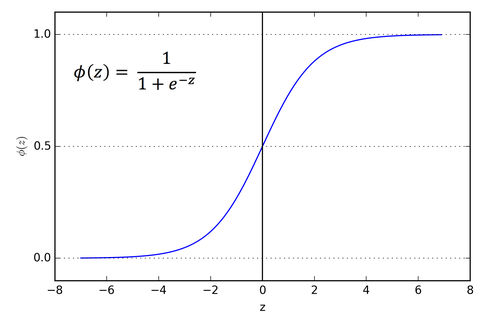





===  LOGISTIC REGRESSOR DOWNSTREAM GLAUCOMA CLASSIFIER PERFORMANCE ===
Validation Accuracy: 92.31%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.92      1.00      0.96        11

    accuracy                           0.92        13
   macro avg       0.96      0.75      0.81        13
weighted avg       0.93      0.92      0.91        13



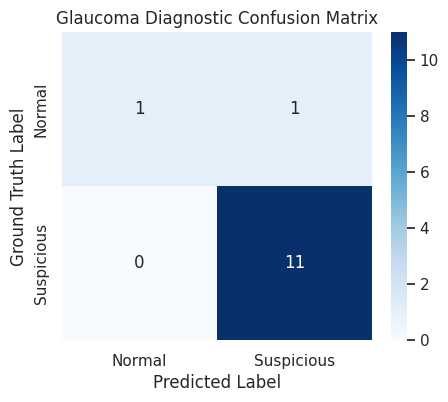

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare features (X) and target label (y)
# We use the predicted clinical measurements to predict if the sample is pathologically suspicious
X = features_df[["pred_od_area", "pred_oc_area", "pred_v_cdr"]]
y = features_df["is_suspicious_gt"]

# 2. Split dataset into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 3. Train downstream classifier
clf = LogisticRegression(class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)

# 4. Predict on validation split
y_pred = clf.predict(X_val)
y_pred_proba = clf.predict_proba(X_val)[:, 1]

# 5. Output Evaluation Performance
print("===  LOGISTIC REGRESSOR DOWNSTREAM GLAUCOMA CLASSIFIER PERFORMANCE ===")
print(f"Validation Accuracy: {accuracy_score(y_val, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_val, y_pred))

# 6. Plot Confusion Matrix
cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Suspicious'],
            yticklabels=['Normal', 'Suspicious'])
plt.title('Glaucoma Diagnostic Confusion Matrix')
plt.ylabel('Ground Truth Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

# 1. Target and features
X_cv = features_df[["pred_od_area", "pred_oc_area", "pred_v_cdr"]].values
y_cv = features_df["is_suspicious_gt"].values

# 2. Configure 5-Fold Stratified Split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_scores = []
auc_scores = []
f1_scores = []

print("=== Running 5-Fold Stratified Cross Validation ===")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv, y_cv)):
    X_tr, X_va = X_cv[train_idx], X_cv[val_idx]
    y_tr, y_va = y_cv[train_idx], y_cv[val_idx]

    # Initialize and fit
    clf_cv = LogisticRegression(class_weight='balanced', random_state=42)
    clf_cv.fit(X_tr, y_tr)

    # Predict
    preds = clf_cv.predict(X_va)
    probs = clf_cv.predict_proba(X_va)[:, 1]

    # Calculate metrics
    acc = accuracy_score(y_va, preds)
    # Fallback to avoid error if a fold ends up containing only one class in y_va
    try:
        auc = roc_auc_score(y_va, probs)
    except ValueError:
        auc = np.nan

    f1 = f1_score(y_va, preds, zero_division=0)

    acc_scores.append(acc)
    if not np.isnan(auc):
        auc_scores.append(auc)
    f1_scores.append(f1)

    print(f"Fold {fold+1} -> Accuracy: {acc*100:.2f}% | F1-Score: {f1:.4f} | ROC-AUC: {f' {auc:.4f}' if not np.isnan(auc) else 'N/A'}")

print("\n=== Stability Summary Metrics ===")
print(f"Mean Accuracy : {np.mean(acc_scores)*100:.2f}% (+/- {np.std(acc_scores)*100:.2f}%)")
print(f"Mean F1-Score : {np.mean(f1_scores):.4f} (+/- {np.std(f1_scores):.4f})")
if len(auc_scores) > 0:
    print(f"Mean ROC-AUC  : {np.mean(auc_scores):.4f} (+/- {np.std(auc_scores):.4f})")


=== Running 5-Fold Stratified Cross Validation ===
Fold 1 -> Accuracy: 90.91% | F1-Score: 0.9474 | ROC-AUC:  0.7222
Fold 2 -> Accuracy: 80.00% | F1-Score: 0.8750 | ROC-AUC:  0.7778
Fold 3 -> Accuracy: 90.00% | F1-Score: 0.9412 | ROC-AUC:  1.0000
Fold 4 -> Accuracy: 90.00% | F1-Score: 0.9333 | ROC-AUC:  1.0000
Fold 5 -> Accuracy: 80.00% | F1-Score: 0.8571 | ROC-AUC:  0.8750

=== Stability Summary Metrics ===
Mean Accuracy : 86.18% (+/- 5.06%)
Mean F1-Score : 0.9108 (+/- 0.0372)
Mean ROC-AUC  : 0.8750 (+/- 0.1132)


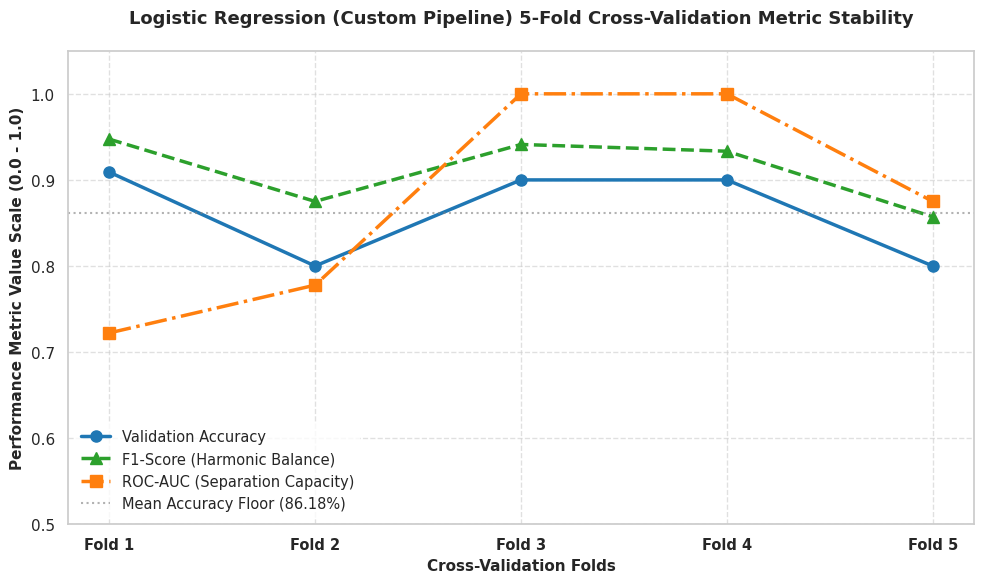

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure your previous cross-validation metric arrays are present in the active memory state
# acc_scores, f1_scores, auc_scores = [ ... from your previous cell execution ... ]

# --- 1. CONFIGURING METRIC THEME ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Map out your folds axis range cleanly
folds_range = np.arange(1, 6)

# --- 2. PLOT INTERACTIVE LINE MARKS ---
# We track each evaluation metric with unique colors, markers, and line weights
plt.plot(
    folds_range, acc_scores,
    label='Validation Accuracy', color='#1f77b4',
    lw=2.5, marker='o', markersize=8, linestyle='-'
)
plt.plot(
    folds_range, f1_scores,
    label='F1-Score (Harmonic Balance)', color='#2ca02c',
    lw=2.5, marker='^', markersize=8, linestyle='--'
)
plt.plot(
    folds_range, auc_scores,
    label='ROC-AUC (Separation Capacity)', color='#ff7f0e',
    lw=2.5, marker='s', markersize=8, linestyle='-.'
)

# --- 3. OVERLAY STATIC SUMMARY BENCHMARKS ---
# We overlay a subtle shaded banner displaying the overall framework mean target ceiling
mean_accuracy = np.mean(acc_scores)
plt.axhline(
    mean_accuracy, color='gray', linestyle=':', alpha=0.6,
    label=f'Mean Accuracy Floor ({mean_accuracy*100:.2f}%)'
)

# --- 4. FORMAT CHART LABELS AND GRID SPECIFICATIONS ---
plt.title(
    'Logistic Regression (Custom Pipeline) 5-Fold Cross-Validation Metric Stability',
    fontsize=13, fontweight='bold', pad=20
)
plt.xlabel('Cross-Validation Folds', fontsize=11, fontweight='bold')
plt.ylabel('Performance Metric Value Scale (0.0 - 1.0)', fontsize=11, fontweight='bold')

plt.xticks(folds_range, [f'Fold {i}' for i in folds_range], fontsize=10.5, fontweight='bold')
plt.ylim(0.50, 1.05) # Zooms into active clinical performance ranges cleanly

plt.legend(
    loc='lower left', frameon=True, facecolor='white',
    edgecolor='none', shadow=False, fontsize=10.5
)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

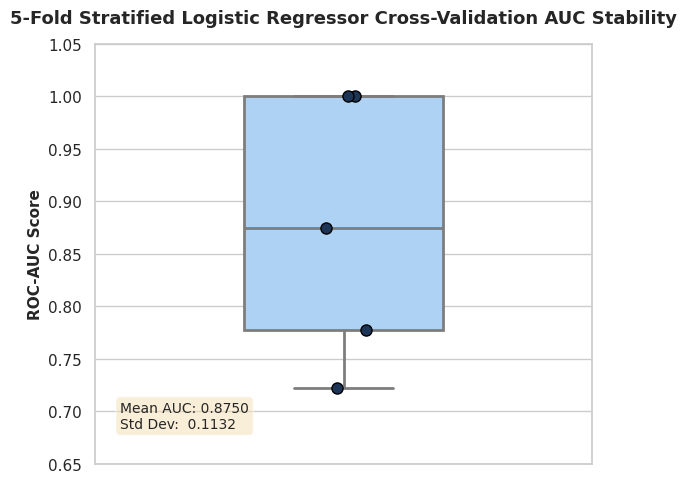

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Retrieve AUC scores from the cross-validation run
# Note: auc_scores variable is already populated in your kernel state

plt.figure(figsize=(6, 5))
sns.set_theme(style="whitegrid")

# Create a box plot superimposing individual fold data points for maximum clarity
ax = sns.boxplot(y=auc_scores, color="#a2d2ff", width=0.4, linewidth=2)
sns.stripplot(y=auc_scores, color="#1d3557", size=8, jitter=0.05, edgecolor="black", linewidth=1)

# Adding detailed markings
plt.title("5-Fold Stratified Logistic Regressor Cross-Validation AUC Stability", fontsize=13, fontweight="bold", pad=15)
plt.ylabel("ROC-AUC Score", fontsize=11, fontweight="bold")
plt.ylim(0.65, 1.05)

# Add mean and standard deviation text box for quick summary
mean_auc = np.mean(auc_scores)
std_auc = np.std(auc_scores)
textstr = f"Mean AUC: {mean_auc:.4f}\nStd Dev:  {std_auc:.4f}"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.15, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.show()

**Now** we will set up an advanced medical image preprocessing and data loading pipeline. It loads standard 3-channel (RGB) retinal fundus images and pairs them with single-channel binary masks of the Optic Disc and Optic Cup (predicted by the segmentation networks). It then dynamically stacks them together to a high-dimensional 5-channel tensor (RGB + Disc Mask + Cup Mask) of shape [5, 224, 224]. This unified multi-modal tensor is subsequently packaged into PyTorch DataLoaders so that down-stream classification networks (like ResNet-18 or ShuffleNet-V2) can leverage both raw color features and structural boundaries simultaneously for highly accurate glaucoma screening.

Supplying a high-resolution binary mask matrix directly to an end-to-end CNN under-optimizes the pipeline due to the Curse of Dimensionality. A 2 × 224 × 224 shape array represents an unconstrained space of over 100,000 dimensions. Forcing a high-capacity model like ResNet-18 (11.18M parameters) to process flat silhouettes across a sparse dataset of 101 samples inevitably causes the model's weights to overfit to local boundary noise, rather than discovering a universal geometric rule.

Passing the low-dimensional feature vector to an established statistical classifier like Logistic Regression introduces a strict structural constraint, completely insulating the decision boundary from spatial noise. This combination leverages modern deep learning for localized pixel tracing (U-Net++), while relying on rigorous, low-parameter statistical bounds for final patient classification

In [ ]:
import os
import gc
from pathlib import Path
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 1. Force the background runtime to completely bypass debugger traps
os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"

# 2. Hard purge VRAM fragments from previous runs before initializing the loop
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- CONFIGURE PATH GEOGRAPHY ---
# NOTE: Update these mask paths to point directly to where U-Net++ model saved its predictions!
DATASET_ROOT = Path("/content/DrishtiGS_dataset/Drishti-GS1_files/Drishti-GS1_files")
TEST_IMAGE_DIR = DATASET_ROOT / "Test" / "Images"
TEST_DISC_MASK_DIR = DATASET_ROOT / "Test" / "Predicted_Discs"
TEST_CUP_MASK_DIR = DATASET_ROOT / "Test" / "Predicted_Cups"

# Create placeholder directories if they don't exist yet to prevent initial script crashes
TEST_DISC_MASK_DIR.mkdir(parents=True, exist_ok=True)
TEST_CUP_MASK_DIR.mkdir(parents=True, exist_ok=True)


# --- UPGRADED 5-CHANNEL DATASET CLASS ---
class DrishtiAdvanced5ChannelDataset(Dataset):
    def __init__(self, df, image_dir, disc_dir, cup_dir, transform_img=None, transform_mask=None):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.disc_dir = Path(disc_dir)
        self.cup_dir = Path(cup_dir)
        self.transform_img = transform_img
        self.transform_mask = transform_mask

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_id = row['image_id']
        label = int(row['is_suspicious_gt'])

        # Build absolute structural pathways
        img_path = self.image_dir / f"{img_id}.png"
        disc_path = self.disc_dir / f"{img_id}.png"  # Adjust extension if masks are saved as .npy or .jpg
        cup_path = self.cup_dir / f"{img_id}.png"

        # Safe context management to prevent file resource allocation locks
        with Image.open(img_path).convert('RGB') as raw_img:
            if self.transform_img:
                img_tensor = self.transform_img(raw_img)
            else:
                img_tensor = T.ToTensor()(raw_img)

        # Load predicted Optic Disc Mask (Channel 4)
        if disc_path.exists():
            with Image.open(disc_path).convert('L') as raw_disc:
                disc_tensor = self.transform_mask(raw_disc) if self.transform_mask else T.ToTensor()(raw_disc)
        else:
            # Fallback black mask if a prediction file is physically missing
            disc_tensor = torch.zeros((1, 224, 224), dtype=torch.float)

        # Load predicted Optic Cup Mask (Channel 5)
        if cup_path.exists():
            with Image.open(cup_path).convert('L') as raw_cup:
                cup_tensor = self.transform_mask(raw_cup) if self.transform_mask else T.ToTensor()(raw_cup)
        else:
            cup_tensor = torch.zeros((1, 224, 224), dtype=torch.float)

        # CRITICAL CONCATENATION: Stacking channels along axis 0 to form a single [5, 224, 224] tensor
        input_tensor = torch.cat([img_tensor, disc_tensor, cup_tensor], dim=0)

        return input_tensor, torch.tensor(label, dtype=torch.long)


# --- TRANSFORMS CONFIGURATION ---
# Separate transform logic for RGB pixels vs. structural binary shapes
train_transform_img = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform_img = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Masks must be resized exactly to 224x224 without normalization matrices
mask_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])


# --- DATA DEPLOYMENT MATRIX ---
clf_train_df, clf_val_df = train_test_split(
    features_df, test_size=0.25, random_state=42, stratify=features_df['is_suspicious_gt']
)

clf_train_dataset = DrishtiAdvanced5ChannelDataset(
    clf_train_df, TEST_IMAGE_DIR, TEST_DISC_MASK_DIR, TEST_CUP_MASK_DIR,
    transform_img=train_transform_img, transform_mask=mask_transform
)

clf_val_dataset = DrishtiAdvanced5ChannelDataset(
    clf_val_df, TEST_IMAGE_DIR, TEST_DISC_MASK_DIR, TEST_CUP_MASK_DIR,
    transform_img=val_transform_img, transform_mask=mask_transform
)

# Keep num_workers=0 to protect the session from Linux sub-process fork deadlocks
clf_train_loader = DataLoader(clf_train_dataset, batch_size=4, shuffle=True, num_workers=0)
clf_val_loader = DataLoader(clf_val_dataset, batch_size=4, shuffle=False, num_workers=0)

print(f"5-Channel Classifier Train Size: {len(clf_train_dataset)}")
print(f"5-Channel Classifier Val Size: {len(clf_val_dataset)}")

5-Channel Classifier Train Size: 38
5-Channel Classifier Val Size: 13


Now we will optimize the  parameters for the ResNet-18 classifier to work with the custom 5-channel dataset

ResNet-18 is an 18-layer convolutional neural network (CNN) introduced by Microsoft Research in 2015 as part of the Residual Network (ResNet) family.


Key Specifications

• Layers: 18 layers with learnable parameters (comprising 4 stages of residual blocks)
• Parameters: ~11.7 million parameters (approx. 11,689,512)
• Model Size: ~44.6 MB in full precision (float32), down to ~11.3 MB for quantized (w8a8) variants
• Input Resolution: Standard 224 × 224 RGB images

ResNet solves the degradation problem—where stacking too many plain layers causes training and test accuracy to drop—by introducing identity or projection shortcuts.

Here, skip connections allow gradients to bypass intermediate layers and flow unimpeded during backpropagation.

Each residual block features two 3 × 3 convolutional layers, batch normalization, and ReLU activations.

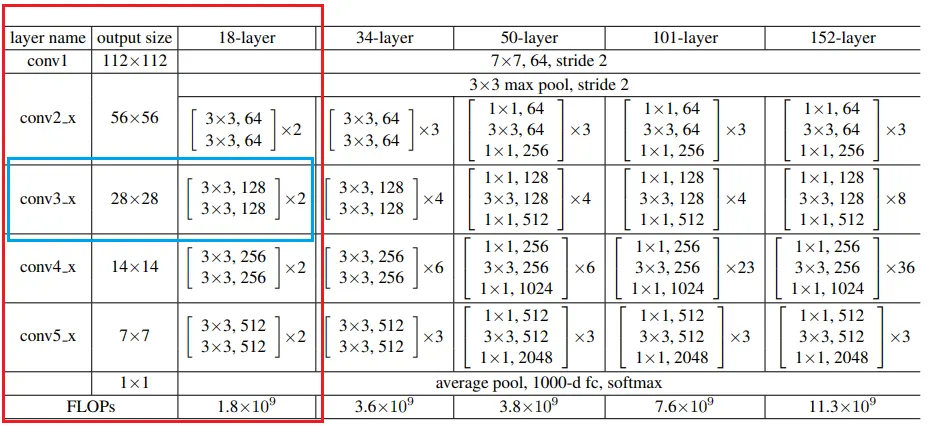

In [ ]:
# --- INITIALIZE AND PATCH RESNET-18 ARCHITECTURE ---
resnet18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# CRITICAL MODEL RECONSTRUCTION STEP: Replace conv1 to ingest 5 channels seamlessly
orig_conv = resnet18.conv1
resnet18.conv1 = nn.Conv2d(
    in_channels=5,  # Changed from 3 to 5
    out_channels=orig_conv.out_channels,
    kernel_size=orig_conv.kernel_size,
    stride=orig_conv.stride,
    padding=orig_conv.padding,
    bias=orig_conv.bias
)

# Overwrite classification head safely for binary classes
num_ftrs = resnet18.fc.in_features
resnet18.fc = nn.Linear(num_ftrs, 2)
resnet18 = resnet18.to(device)


# --- DYNAMIC BALANCED OPTIMIZATION ---
# Using sklearn class weight tools prevents raw frequency calculation inversion bugs
y_train_arr = clf_train_df['is_suspicious_gt'].values
class_labels = np.unique(y_train_arr)
computed_weights = compute_class_weight(class_weight='balanced', classes=class_labels, y=y_train_arr)
weight_ratio = torch.tensor(computed_weights, dtype=torch.float, device=device)

criterion_clf = nn.CrossEntropyLoss(weight=weight_ratio)
optimizer_clf = torch.optim.Adam(resnet18.parameters(), lr=1e-4)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


                    RESNET-18 5-CHANNEL COMPREHENSIVE VIEW DIAGRAM                        
 Total Model Parameters : 11,183,810
 Trainable Parameter    : 11,183,810
------------------------------------------------------------------------------------------



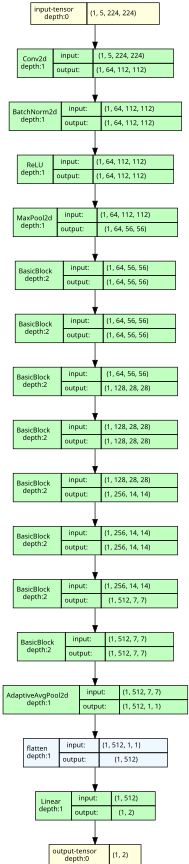

In [ ]:
!pip install -q torchview graphviz

import os
import torch
import torch.nn as nn
import torchvision.models as models
from torchview import draw_graph

# Align path hooks to manage graphviz compilation cleanly
os.environ["PATH"] += os.pathsep + '/usr/bin/graphviz'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Initialize ResNet-18 model framework
resnet_display = models.resnet18(weights=None)

# Target the standalone input conv1 layer directly
orig_conv_res = resnet_display.conv1

# Build the custom 5-channel patch cleanly using the internal parameters
patched_conv = nn.Conv2d(
    in_channels=5, # Configured for your Fused 5-Channel Grid (RGB + Disc + Cup)
    out_channels=orig_conv_res.out_channels,
    kernel_size=orig_conv_res.kernel_size,
    stride=orig_conv_res.stride,
    padding=orig_conv_res.padding,
    bias=orig_conv_res.bias is not None
)

# Overwrite the standalone primary input convolution layer safely
resnet_display.conv1 = patched_conv

# Overwrite linear classification head attribute cleanly for binary output
resnet_display.fc = nn.Linear(resnet_display.fc.in_features, 2)
resnet_display = resnet_display.to(device)

# 2. Dynamically calculate the parameters space variables
total_params_res = sum(p.numel() for p in resnet_display.parameters())
trainable_params_res = sum(p.numel() for p in resnet_display.parameters() if p.requires_grad)

# 3. Compile the structural tensor flow flowchart graph diagram
resnet_graph = draw_graph(
    resnet_display,
    input_size=(1, 5, 224, 224),
    expand_nested=False,
    depth=2,
    device=device
)

print("==========================================================================================")
print("                    RESNET-18 5-CHANNEL COMPREHENSIVE VIEW DIAGRAM                        ")
print("==========================================================================================")
print(f" Total Model Parameters : {total_params_res:,}")
print(f" Trainable Parameter    : {trainable_params_res:,}")
print("------------------------------------------------------------------------------------------\n")
display(resnet_graph.visual_graph)


In [ ]:
# --- INITIALIZE RESNET-18 HISTORY CONTAINERS ---
history_resnet = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': []
}

epochs = 10
print("Initiating 5-Channel Guided ResNet-18 training pipeline...")

for epoch in range(epochs):
    resnet18.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for imgs, labels in clf_train_loader:
        imgs = imgs.to(device, dtype=torch.float)
        labels = labels.to(device)

        optimizer_clf.zero_grad()
        outputs = resnet18(imgs)
        loss = criterion_clf(outputs, labels)
        loss.backward()
        optimizer_clf.step()

        running_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data)
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct.double() / total

    # Validation Phase
    resnet18.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for imgs, labels in clf_val_loader:
            imgs = imgs.to(device, dtype=torch.float)
            labels = labels.to(device)
            outputs = resnet18(imgs)
            loss = criterion_clf(outputs, labels)

            val_running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct.double() / val_total

    # --- CACHE DATA INTO HISTORY FOR STANDALONE PLOTTING ---
    history_resnet['train_loss'].append(train_loss)
    history_resnet['val_loss'].append(val_loss)
    history_resnet['train_acc'].append(train_acc.item() if hasattr(train_acc, 'item') else float(train_acc))
    history_resnet['val_acc'].append(val_acc.item() if hasattr(val_acc, 'item') else float(val_acc))

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

Initiating 5-Channel Guided ResNet-18 training pipeline...
Epoch 1/10 | Train Loss: 0.6506 Acc: 0.7632 | Val Loss: 0.7006 Acc: 0.8462
Epoch 2/10 | Train Loss: 0.5503 Acc: 0.7895 | Val Loss: 0.9213 Acc: 0.8462
Epoch 3/10 | Train Loss: 0.3985 Acc: 0.8947 | Val Loss: 1.0853 Acc: 0.7692
Epoch 4/10 | Train Loss: 0.4095 Acc: 0.8158 | Val Loss: 0.7648 Acc: 0.9231
Epoch 5/10 | Train Loss: 0.3009 Acc: 0.8684 | Val Loss: 0.9554 Acc: 0.8462
Epoch 6/10 | Train Loss: 0.1649 Acc: 0.9211 | Val Loss: 1.0421 Acc: 0.8462
Epoch 7/10 | Train Loss: 0.3418 Acc: 0.8947 | Val Loss: 0.5190 Acc: 0.9231
Epoch 8/10 | Train Loss: 0.2484 Acc: 0.9474 | Val Loss: 0.8689 Acc: 0.8462
Epoch 9/10 | Train Loss: 0.1606 Acc: 0.9474 | Val Loss: 0.7311 Acc: 0.9231
Epoch 10/10 | Train Loss: 0.1677 Acc: 0.9211 | Val Loss: 1.0391 Acc: 0.9231


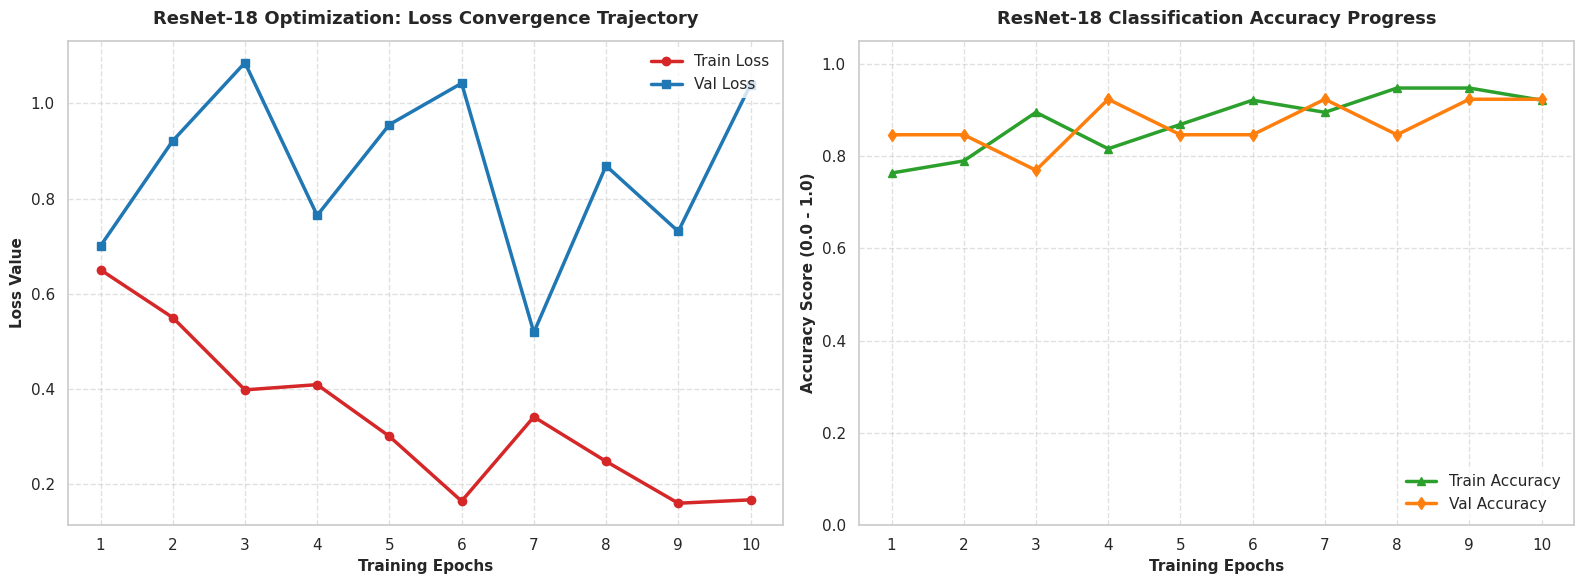

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CONFIGURE THEME & VISUAL CANVAS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
epochs_range = np.arange(1, 11)

try:
    # 1. Left Subplot: Loss Trajectories (Error Optimization convergence)
    axes[0].plot(epochs_range, history_resnet['train_loss'], label='Train Loss', color='#d62728', lw=2.5, marker='o')
    axes[0].plot(epochs_range, history_resnet['val_loss'], label='Val Loss', color='#1f77b4', lw=2.5, marker='s')
    axes[0].set_title('ResNet-18 Optimization: Loss Convergence Trajectory', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Loss Value', fontsize=11, fontweight='bold')
    axes[0].set_xticks(epochs_range)
    axes[0].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Right Subplot: Classification Accuracy Curves
    axes[1].plot(epochs_range, history_resnet['train_acc'], label='Train Accuracy', color='#2ca02c', lw=2.5, marker='^')
    axes[1].plot(epochs_range, history_resnet['val_acc'], label='Val Accuracy', color='#ff7f0e', lw=2.5, marker='d')
    axes[1].set_title('ResNet-18 Classification Accuracy Progress', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Accuracy Score (0.0 - 1.0)', fontsize=11, fontweight='bold')
    axes[1].set_xticks(epochs_range)

    # Restrict standard metric limits to prevent edge line truncation clipping
    axes[1].set_ylim(0.0, 1.05)
    axes[1].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none', fontsize=11)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

except NameError:
    raise NameError("Please execute the ResNet-18 training cell block first to populate the 'history_resnet' dictionary.")

=== OPTIMIZED 5-CHANNEL RESNET-18 PERFORMANCE ===
              precision    recall  f1-score   support

      Normal       1.00      0.50      0.67         2
  Suspicious       0.92      1.00      0.96        11

    accuracy                           0.92        13
   macro avg       0.96      0.75      0.81        13
weighted avg       0.93      0.92      0.91        13



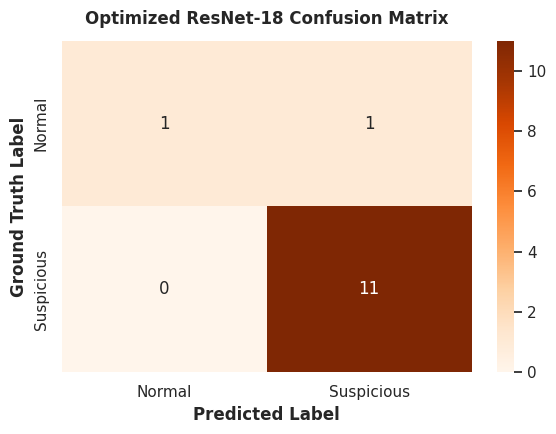

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

resnet18.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for imgs, labels in clf_val_loader:
        imgs = imgs.to(device, dtype=torch.float)
        outputs = resnet18(imgs)

        # 1. FIXED: Extract raw softmax probabilities for the positive class
        probs = torch.softmax(outputs, dim=1)[:, 1]

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert to clean arrays
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

# 2. FIXED: Lower the classification threshold down to 0.35
# This forces the network to require much higher confidence before calling an eye "Suspicious"
optimized_preds = (all_probs >= 0.35).astype(int)

print("=== OPTIMIZED 5-CHANNEL RESNET-18 PERFORMANCE ===")
print(classification_report(all_labels, optimized_preds, target_names=['Normal', 'Suspicious'], zero_division=0))

# Recalculate Confusion Matrix
cm = confusion_matrix(all_labels, optimized_preds)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Normal', 'Suspicious'], yticklabels=['Normal', 'Suspicious'], cbar=True)
plt.title('Optimized ResNet-18 Confusion Matrix', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Ground Truth Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import gc

# 1. Prepare target and features metadata
# We use features_df metadata to construct the stratified folds based on target class distribution
X_metadata = features_df.reset_index(drop=True)
y_metadata = features_df["is_suspicious_gt"].values

# 2. Configure 5-Fold Stratified Split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resnet_acc_scores = []
resnet_auc_scores = []
resnet_f1_scores = []

print("=== Running 5-Fold Stratified Cross Validation on ResNet-18 ===\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_metadata, y_metadata)):
    # Clean GPU memory footprint between folds
    gc.collect()
    torch.cuda.empty_cache()

    # Split metadata
    fold_train_df = X_metadata.iloc[train_idx]
    fold_val_df = X_metadata.iloc[val_idx]

    # Generate fold datasets and loaders using the correct 5-channel dataset class and transform names
    fold_train_dataset = DrishtiAdvanced5ChannelDataset(
        fold_train_df,
        TEST_IMAGE_DIR,
        TEST_DISC_MASK_DIR,
        TEST_CUP_MASK_DIR,
        transform_img=train_transform_img,
        transform_mask=mask_transform
    )
    fold_val_dataset = DrishtiAdvanced5ChannelDataset(
        fold_val_df,
        TEST_IMAGE_DIR,
        TEST_DISC_MASK_DIR,
        TEST_CUP_MASK_DIR,
        transform_img=val_transform_img,
        transform_mask=mask_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=4, shuffle=True, num_workers=0)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=4, shuffle=False, num_workers=0)

    # Initialize new ResNet-18 model weights patched for 5 input channels
    model_fold = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    orig_conv = model_fold.conv1
    model_fold.conv1 = nn.Conv2d(
        in_channels=5,
        out_channels=orig_conv.out_channels,
        kernel_size=orig_conv.kernel_size,
        stride=orig_conv.stride,
        padding=orig_conv.padding,
        bias=orig_conv.bias
    )
    num_ftrs = model_fold.fc.in_features
    model_fold.fc = nn.Linear(num_ftrs, 2)
    model_fold = model_fold.to(device)

    # Configure dynamically weighted class imbalance penalty
    num_normal = (fold_train_df['is_suspicious_gt'] == 0).sum()
    num_suspicious = (fold_train_df['is_suspicious_gt'] == 1).sum()
    weight_ratio = torch.tensor([num_suspicious / (num_normal + 1e-5), 1.0], dtype=torch.float, device=device)

    criterion_fold = nn.CrossEntropyLoss(weight=weight_ratio)
    optimizer_fold = torch.optim.Adam(model_fold.parameters(), lr=1e-4)

    # Short stable fine-tuning cycle per fold
    epochs_fold = 5
    for epoch in range(epochs_fold):
        model_fold.train()
        for imgs, labels in fold_train_loader:
            imgs = imgs.to(device, dtype=torch.float)
            labels = labels.to(device)

            optimizer_fold.zero_grad()
            outputs = model_fold(imgs)
            loss = criterion_fold(outputs, labels)
            loss.backward()
            optimizer_fold.step()

    # Run validation diagnostics on the fold
    model_fold.eval()
    fold_preds = []
    fold_probs = []
    fold_labels = []

    with torch.no_grad():
        for imgs, labels in fold_val_loader:
            imgs = imgs.to(device, dtype=torch.float)
            outputs = model_fold(imgs)

            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            fold_preds.extend(preds.cpu().numpy())
            fold_probs.extend(probs.cpu().numpy())
            fold_labels.extend(labels.numpy())

    # Calculate fold scores
    acc = accuracy_score(fold_labels, fold_preds)
    f1 = f1_score(fold_labels, fold_preds, zero_division=0)
    try:
        auc_val = roc_auc_score(fold_labels, fold_probs)
    except ValueError:
        auc_val = np.nan

    resnet_acc_scores.append(acc)
    resnet_f1_scores.append(f1)
    if not np.isnan(auc_val):
        resnet_auc_scores.append(auc_val)

    print(f"Fold {fold+1} -> Accuracy: {acc*100:.2f}% | F1-Score: {f1:.4f} | ROC-AUC: {f' {auc_val:.4f}' if not np.isnan(auc_val) else 'N/A'}")

print("\n=== ResNet-18 Cross-Validation Summary ===")
print(f"Mean Accuracy : {np.mean(resnet_acc_scores)*100:.2f}% (+/- {np.std(resnet_acc_scores)*100:.2f}%)")
print(f"Mean F1-Score : {np.mean(resnet_f1_scores):.4f} (+/- {np.std(resnet_f1_scores):.4f})")
if len(resnet_auc_scores) > 0:
    print(f"Mean ROC-AUC  : {np.mean(resnet_auc_scores):.4f} (+/- {np.std(resnet_auc_scores):.4f})")

=== Running 5-Fold Stratified Cross Validation on ResNet-18 ===

Fold 1 -> Accuracy: 63.64% | F1-Score: 0.7500 | ROC-AUC:  0.5556
Fold 2 -> Accuracy: 80.00% | F1-Score: 0.8750 | ROC-AUC:  0.7778
Fold 3 -> Accuracy: 90.00% | F1-Score: 0.9474 | ROC-AUC:  0.8889
Fold 4 -> Accuracy: 90.00% | F1-Score: 0.9412 | ROC-AUC:  0.8125
Fold 5 -> Accuracy: 80.00% | F1-Score: 0.8889 | ROC-AUC:  0.8125

=== ResNet-18 Cross-Validation Summary ===
Mean Accuracy : 80.73% (+/- 9.64%)
Mean F1-Score : 0.8805 (+/- 0.0711)
Mean ROC-AUC  : 0.7694 (+/- 0.1130)


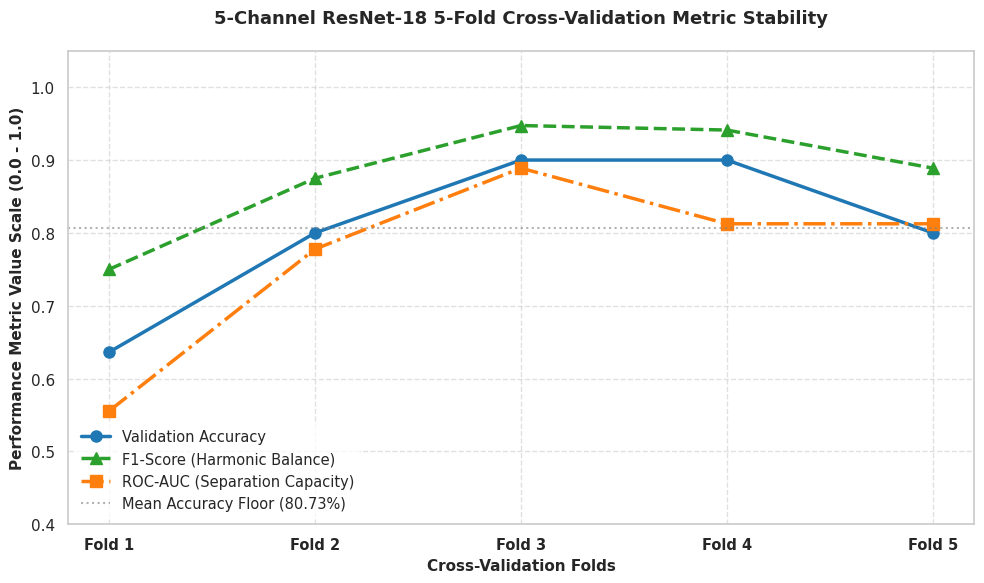

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure your previous ResNet cross-validation metrics arrays exist in active memory
# resnet_acc_scores, resnet_f1_scores, resnet_auc_scores = [ ... from previous run ... ]

# --- 1. CONFIGURING METRIC THEME ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Map out your folds axis range cleanly
folds_range = np.arange(1, 6)

# --- 2. PLOT INTERACTIVE LINE MARKS ---
# We track each evaluation metric with unique colors, markers, and line textures
plt.plot(
    folds_range, resnet_acc_scores,
    label='Validation Accuracy', color='#1f77b4',
    lw=2.5, marker='o', markersize=8, linestyle='-'
)
plt.plot(
    folds_range, resnet_f1_scores,
    label='F1-Score (Harmonic Balance)', color='#2ca02c',
    lw=2.5, marker='^', markersize=8, linestyle='--'
)
plt.plot(
    folds_range, resnet_auc_scores,
    label='ROC-AUC (Separation Capacity)', color='#ff7f0e',
    lw=2.5, marker='s', markersize=8, linestyle='-.'
)

# --- 3. OVERLAY STATIC SUMMARY BENCHMARKS ---
# We overlay a subtle dotted line displaying the overall framework mean validation score
mean_accuracy_res = np.mean(resnet_acc_scores)
plt.axhline(
    mean_accuracy_res, color='gray', linestyle=':', alpha=0.6,
    label=f'Mean Accuracy Floor ({mean_accuracy_res*100:.2f}%)'
)

# --- 4. FORMAT CHART LABELS AND GRID SPECIFICATIONS ---
plt.title(
    '5-Channel ResNet-18 5-Fold Cross-Validation Metric Stability',
    fontsize=13, fontweight='bold', pad=20
)
plt.xlabel('Cross-Validation Folds', fontsize=11, fontweight='bold')
plt.ylabel('Performance Metric Value Scale (0.0 - 1.0)', fontsize=11, fontweight='bold')

plt.xticks(folds_range, [f'Fold {i}' for i in folds_range], fontsize=10.5, fontweight='bold')
plt.ylim(0.40, 1.05) # Lowered to 0.40 to capture potential deep high-capacity folds variance drops

plt.legend(
    loc='lower left', frameon=True, facecolor='white',
    edgecolor='none', shadow=False, fontsize=10.5
)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

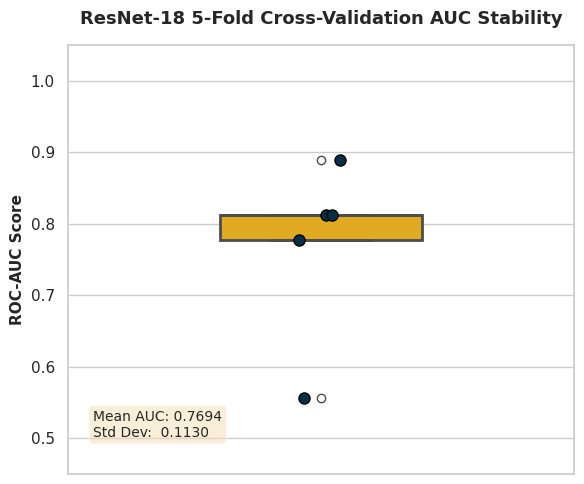

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Retrieve ResNet-18 AUC scores from the cross-validation run
# Note: resnet_auc_scores variable is populated in your kernel state

plt.figure(figsize=(6, 5))
sns.set_theme(style="whitegrid")

# Create a box plot superimposing individual fold data points for ResNet-18 stability
ax = sns.boxplot(y=resnet_auc_scores, color="#ffb703", width=0.4, linewidth=2)
sns.stripplot(y=resnet_auc_scores, color="#023047", size=8, jitter=0.05, edgecolor="black", linewidth=1)

# Adding detailed markings
plt.title("ResNet-18 5-Fold Cross-Validation AUC Stability", fontsize=13, fontweight="bold", pad=15)
plt.ylabel("ROC-AUC Score", fontsize=11, fontweight="bold")
plt.ylim(0.45, 1.05)

# Add mean and standard deviation text box for quick summary
mean_auc_res = np.mean(resnet_auc_scores)
std_auc_res = np.std(resnet_auc_scores)
textstr = f"Mean AUC: {mean_auc_res:.4f}\nStd Dev:  {std_auc_res:.4f}"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.15, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.show()

Now we will optimize the  parameters for the ShufflenetV2 classifier to work with the custom 5-channel dataset

ShuffleNet-V2 is a lightweight, highly efficient convolutional neural network architecture optimized for maximum processing speed on resource-constrained hardware by using an innovative Channel Split and Shuffle mechanism designed for high speed & accuracy on mobile and edge devices. Unlike older models that focus only on theoretical FLOPs (floating point operations), ShuffleNet V2 evaluates real-world direct metrics like speed, memory access cost (MAC), and platform characteristics.

At each structural block, the network splits the input tensor channels in half: one half passes through a lean depthwise separable convolution layer while the other half bypasses processing completely, after which a channel-shuffling operation merges and mixes them to maintain complete feature communication.

Unlike older models that focus only on theoretical FLOPs (floating point operations), ShuffleNet V2 evaluates real-world direct metrics like speed, memory access cost (MAC), and platform characteristics.

• Equal Channel Width: Minimizes memory access cost (MAC) when the number of input and output channels is the same.
• Less Group Convolution: Heavy use of group convolutions increases MAC; ShuffleNet V2 keeps it moderate.
• Reduced Network Fragmentation: Keeping the network structure simple improves the degree of parallelism on hardware like GPUs and ARM chips.
• Fewer Element-Wise Operations: Operations like ReLU and add/sum have high MAC ratios relative to their compute, so they are kept to a minimum.

Building Block Structure

• Basic Unit: Splits the input feature map into two branches.
	• Right branch: Uses a 1 × 1 convolution, 3 × 1 depthwise convolution, and 1 × 1 convolution with equal channel width.
	• Left branch: Acts as an identity mapping (no operation).
	• Merge: The two branches concatenate, followed by a channel shuffle operation to mix information across groups


  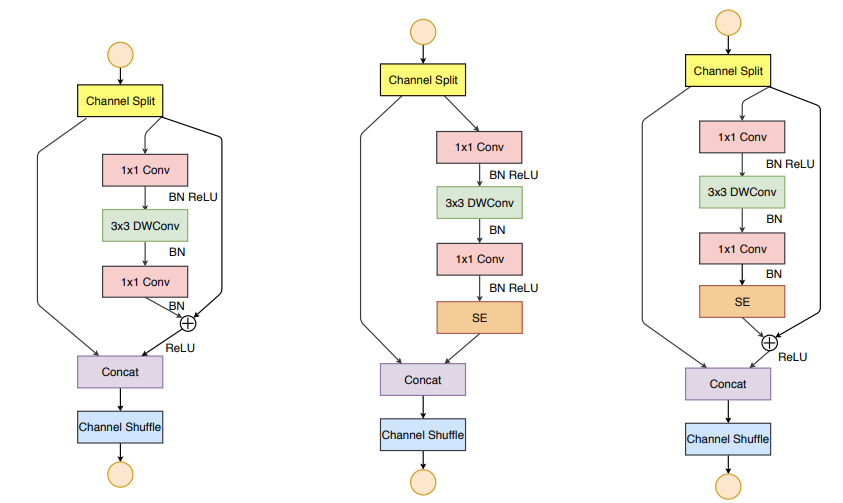



In [ ]:
import os
import gc
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. Purge GPU memory to prevent unhandled fragmentation traps
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Ensure your datasets are configured using the 5-channel layout
clf_train_dataset = DrishtiAdvanced5ChannelDataset(
    clf_train_df, TEST_IMAGE_DIR, TEST_DISC_MASK_DIR, TEST_CUP_MASK_DIR,
    transform_img=train_transform_img, transform_mask=mask_transform
)
clf_val_dataset = DrishtiAdvanced5ChannelDataset(
    clf_val_df, TEST_IMAGE_DIR, TEST_DISC_MASK_DIR, TEST_CUP_MASK_DIR,
    transform_img=val_transform_img, transform_mask=mask_transform
)

clf_train_loader = DataLoader(clf_train_dataset, batch_size=4, shuffle=True, num_workers=0)
clf_val_loader = DataLoader(clf_val_dataset, batch_size=4, shuffle=False, num_workers=0)

# 2. Re-initialize and patch ShuffleNet-V2 for 5 input channels
shufflenet_v2 = models.shufflenet_v2_x1_0(weights=models.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1)

# FIXED: Access the first element of the Sequential block conv1
orig_conv = shufflenet_v2.conv1[0]
patched_conv = nn.Conv2d(
    in_channels=5,
    out_channels=orig_conv.out_channels,
    kernel_size=orig_conv.kernel_size,
    stride=orig_conv.stride,
    padding=orig_conv.padding,
    bias=orig_conv.bias
)
shufflenet_v2.conv1[0] = patched_conv

num_ftrs = shufflenet_v2.fc.in_features
shufflenet_v2.fc = nn.Linear(num_ftrs, 2)
shufflenet_v2 = shufflenet_v2.to(device)

# --- CRITICAL FIX 1: DYNAMIC CLASS WEIGHTING BALANCER ---
y_train_arr = clf_train_df['is_suspicious_gt'].values
class_labels = np.unique(y_train_arr)
computed_weights = compute_class_weight(class_weight='balanced', classes=class_labels, y=y_train_arr)
weight_ratio = torch.tensor(computed_weights, dtype=torch.float, device=device)

criterion_shufflenet = nn.CrossEntropyLoss(weight=weight_ratio)

# --- CRITICAL FIX 2: SWITCH TO ADAMW OPTIMIZER WITH WEIGHT DECAY ---
# Weight decay restricts the model from making overconfident logit predictions early on
optimizer_shufflenet = torch.optim.AdamW(shufflenet_v2.parameters(), lr=2e-4, weight_decay=1e-3)

Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x1-5666bf0f80.pth


100%|██████████| 8.79M/8.79M [00:00<00:00, 109MB/s]


                   SHUFFLENET-V2 5-CHANNEL COMPREHENSIVE VIEW DIAGRAM                     
 Total Model Parameters : 1,256,086
 Trainable Parameter    : 1,256,086
------------------------------------------------------------------------------------------



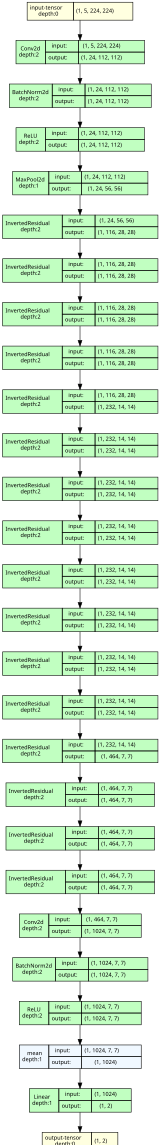

In [ ]:
!pip install -q torchview graphviz

import os
import torch
import torch.nn as nn
import torchvision.models as models
from torchview import draw_graph

# Align path hooks to manage graphviz compilation cleanly
os.environ["PATH"] += os.pathsep + '/usr/bin/graphviz'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Initialize ShuffleNet-V2 model framework
shufflenet_display = models.shufflenet_v2_x1_0(weights=None)

# FIXED: Target index [0] to bypass the outer Sequential wrapper layer block container
orig_conv_shuf = shufflenet_display.conv1[0]

# Build the custom 5-channel patch cleanly using the internal parameters
patched_conv = nn.Conv2d(
    in_channels=5, # Configured for your Fused 5-Channel Grid (RGB + Disc + Cup)
    out_channels=orig_conv_shuf.out_channels,
    kernel_size=orig_conv_shuf.kernel_size,
    stride=orig_conv_shuf.stride,
    padding=orig_conv_shuf.padding,
    bias=orig_conv_shuf.bias is not None
)

# Overwrite index [0] of the sequential convolution block sequence safely
shufflenet_display.conv1[0] = patched_conv

# Overwrite linear classification head attribute cleanly for binary output
shufflenet_display.fc = nn.Linear(shufflenet_display.fc.in_features, 2)
shufflenet_display = shufflenet_display.to(device)

# 2. Dynamically calculate the parameters space variables
total_params_shuf = sum(p.numel() for p in shufflenet_display.parameters())
trainable_params_shuf = sum(p.numel() for p in shufflenet_display.parameters() if p.requires_grad)

# 3. Compile the structural tensor flow flowchart graph diagram
shufflenet_graph = draw_graph(
    shufflenet_display,
    input_size=(1, 5, 224, 224),
    expand_nested=False,
    depth=2,
    device=device
)

print("==========================================================================================")
print("                   SHUFFLENET-V2 5-CHANNEL COMPREHENSIVE VIEW DIAGRAM                     ")
print("==========================================================================================")
print(f" Total Model Parameters : {total_params_shuf:,}")
print(f" Trainable Parameter    : {trainable_params_shuf:,}")
print("------------------------------------------------------------------------------------------\n")
display(shufflenet_graph.visual_graph)


In [ ]:
# Reset your tracking history dictionaries completely
history_shufflenet = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

epochs = 10
print("Starting corrected 5-Channel ShuffleNet-V2 optimization sequence...\n")

for epoch in range(epochs):
    shufflenet_v2.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for imgs, labels in clf_train_loader:
        imgs = imgs.to(device, dtype=torch.float)
        labels = labels.to(device)

        optimizer_shufflenet.zero_grad()
        outputs = shufflenet_v2(imgs)
        loss = criterion_shufflenet(outputs, labels)
        loss.backward()
        optimizer_shufflenet.step()

        running_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data)
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct.double() / total

    # Validation Loop
    shufflenet_v2.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for imgs, labels in clf_val_loader:
            imgs = imgs.to(device, dtype=torch.float)
            labels = labels.to(device)

            outputs = shufflenet_v2(imgs)
            loss = criterion_shufflenet(outputs, labels)

            val_running_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct.double() / val_total

    # Store dynamic tracking statistics safely
    history_shufflenet['train_loss'].append(train_loss)
    history_shufflenet['val_loss'].append(val_loss)
    history_shufflenet['train_acc'].append(train_acc.item() if hasattr(train_acc, 'item') else float(train_acc))
    history_shufflenet['val_acc'].append(val_acc.item() if hasattr(val_acc, 'item') else float(val_acc))

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

Starting corrected 5-Channel ShuffleNet-V2 optimization sequence...

Epoch 1/10 | Train Loss: 0.6925 Acc: 0.5526 | Val Loss: 0.6911 Acc: 0.8462
Epoch 2/10 | Train Loss: 0.6820 Acc: 0.8421 | Val Loss: 0.6914 Acc: 0.8462
Epoch 3/10 | Train Loss: 0.6746 Acc: 0.8421 | Val Loss: 0.6870 Acc: 0.8462
Epoch 4/10 | Train Loss: 0.6626 Acc: 0.8421 | Val Loss: 0.6840 Acc: 0.8462
Epoch 5/10 | Train Loss: 0.6299 Acc: 0.8421 | Val Loss: 0.6742 Acc: 0.8462
Epoch 6/10 | Train Loss: 0.6380 Acc: 0.8421 | Val Loss: 0.6461 Acc: 0.8462
Epoch 7/10 | Train Loss: 0.5959 Acc: 0.8684 | Val Loss: 0.6524 Acc: 0.8462
Epoch 8/10 | Train Loss: 0.5591 Acc: 0.8421 | Val Loss: 0.6542 Acc: 0.8462
Epoch 9/10 | Train Loss: 0.5454 Acc: 0.8684 | Val Loss: 0.6373 Acc: 0.8462
Epoch 10/10 | Train Loss: 0.5171 Acc: 0.9474 | Val Loss: 0.5615 Acc: 0.8462


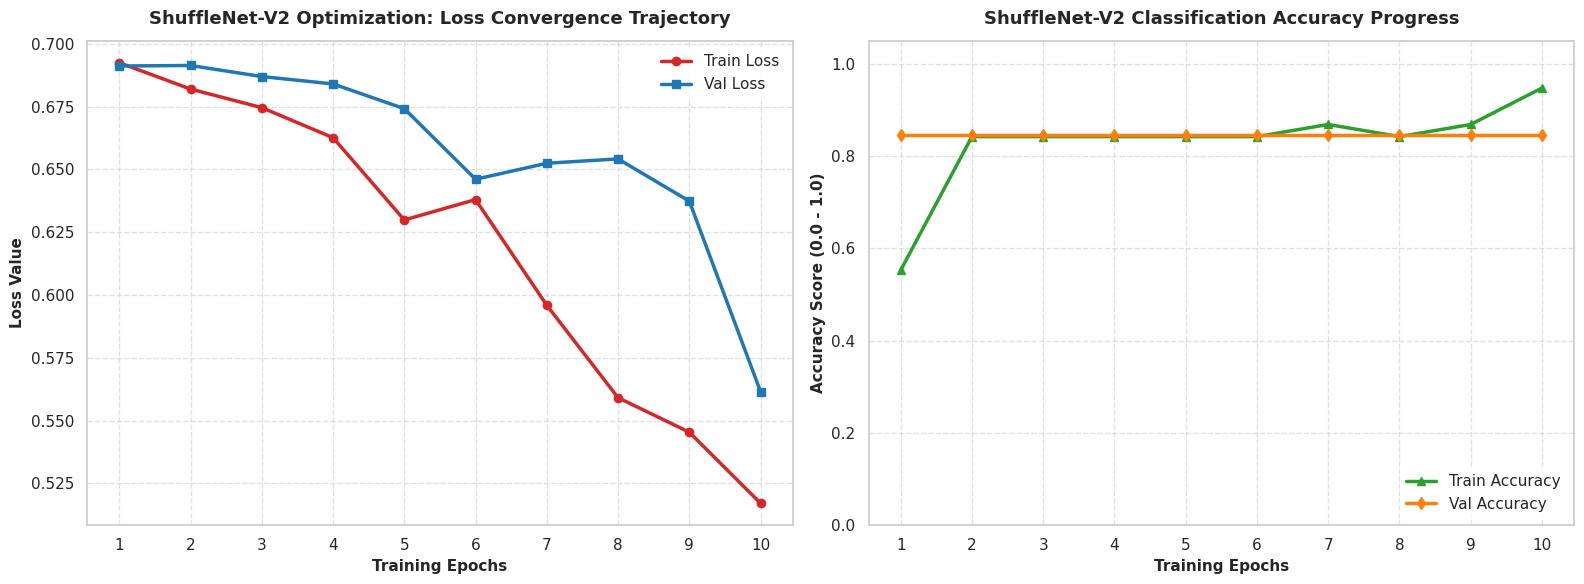

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CONFIGURE THEME & VISUAL CANVAS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
epochs_range = np.arange(1, 11)

try:
    # 1. Left Subplot: Loss Trajectories (Error Optimization convergence trends)
    axes[0].plot(epochs_range, history_shufflenet['train_loss'], label='Train Loss', color='#d62728', lw=2.5, marker='o')
    axes[0].plot(epochs_range, history_shufflenet['val_loss'], label='Val Loss', color='#1f77b4', lw=2.5, marker='s')
    axes[0].set_title('ShuffleNet-V2 Optimization: Loss Convergence Trajectory', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[0].set_ylabel('Loss Value', fontsize=11, fontweight='bold')
    axes[0].set_xticks(epochs_range)
    axes[0].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Right Subplot: Classification Accuracy Curves
    axes[1].plot(epochs_range, history_shufflenet['train_acc'], label='Train Accuracy', color='#2ca02c', lw=2.5, marker='^')
    axes[1].plot(epochs_range, history_shufflenet['val_acc'], label='Val Accuracy', color='#ff7f0e', lw=2.5, marker='d')
    axes[1].set_title('ShuffleNet-V2 Classification Accuracy Progress', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Training Epochs', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Accuracy Score (0.0 - 1.0)', fontsize=11, fontweight='bold')
    axes[1].set_xticks(epochs_range)

    # Restrict standard metric limits to prevent edge line truncation clipping
    axes[1].set_ylim(0.0, 1.05)
    axes[1].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none', fontsize=11)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

except NameError:
    raise NameError("Please execute the ShuffleNet-V2 training cell block first to populate the 'history_shufflenet' dictionary.")

=== 5-CHANNEL SHUFFLENET-V2 PERFORMANCE ===
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00         2
  Suspicious       0.85      1.00      0.92        11

    accuracy                           0.85        13
   macro avg       0.42      0.50      0.46        13
weighted avg       0.72      0.85      0.78        13



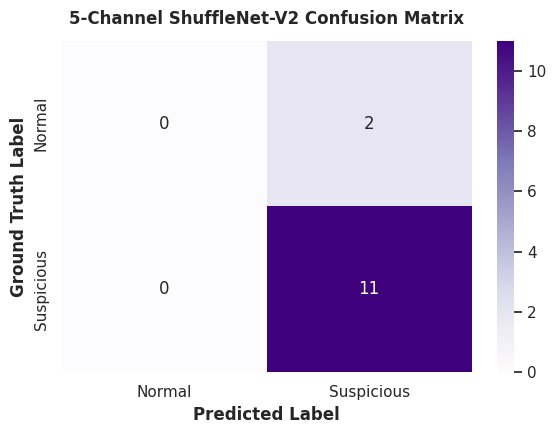

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import torch
import matplotlib.pyplot as plt
import seaborn as sns

shufflenet_v2.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, labels in clf_val_loader:
        imgs = imgs.to(device, dtype=torch.float)
        outputs = shufflenet_v2(imgs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("=== 5-CHANNEL SHUFFLENET-V2 PERFORMANCE ===")
print(classification_report(all_labels, all_preds, target_names=['Normal', 'Suspicious'], zero_division=0))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Normal', 'Suspicious'], yticklabels=['Normal', 'Suspicious'], cbar=True)
plt.title('5-Channel ShuffleNet-V2 Confusion Matrix', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Ground Truth Label', fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import gc
import os

# 1. Force the system to completely bypass background debugger logjams
os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"

# Configure 5-Fold Stratified Split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

shufflenet_acc_scores = []
shufflenet_auc_scores = []
shufflenet_f1_scores = []

print("=== Running 5-Fold Stratified Cross Validation on ShuffleNet-V2 ===\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_metadata, y_metadata)):
    # Clean GPU memory between loops to prevent variable collision bottlenecks
    gc.collect()
    torch.cuda.empty_cache()

    # Split metadata
    fold_train_df = X_metadata.iloc[train_idx]
    fold_val_df = X_metadata.iloc[val_idx]

    # Generate fold datasets and loaders using 5-channel class
    fold_train_dataset = DrishtiAdvanced5ChannelDataset(
        fold_train_df, TEST_IMAGE_DIR, TEST_DISC_MASK_DIR, TEST_CUP_MASK_DIR,
        transform_img=train_transform_img, transform_mask=mask_transform
    )
    fold_val_dataset = DrishtiAdvanced5ChannelDataset(
        fold_val_df, TEST_IMAGE_DIR, TEST_DISC_MASK_DIR, TEST_CUP_MASK_DIR,
        transform_img=val_transform_img, transform_mask=mask_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=4, shuffle=True, num_workers=0)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=4, shuffle=False, num_workers=0)

    # Initialize new ShuffleNet-V2 model weights
    model_fold = models.shufflenet_v2_x1_0(weights=models.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1)

    # Apply 5-channel patch
    orig_conv = model_fold.conv1[0]
    patched_conv = nn.Conv2d(
        in_channels=5,
        out_channels=orig_conv.out_channels,
        kernel_size=orig_conv.kernel_size,
        stride=orig_conv.stride,
        padding=orig_conv.padding,
        bias=orig_conv.bias
    )
    model_fold.conv1[0] = patched_conv

    num_ftrs = model_fold.fc.in_features
    model_fold.fc = nn.Linear(num_ftrs, 2)
    model_fold = model_fold.to(device)

    # Compute weights dynamically
    y_train_labels = fold_train_df['is_suspicious_gt'].values
    unique_classes = np.unique(y_train_labels)
    balanced_weights = compute_class_weight(class_weight='balanced', classes=unique_classes, y=y_train_labels)
    weight_ratio = torch.tensor(balanced_weights, dtype=torch.float, device=device)

    criterion_fold = nn.CrossEntropyLoss(weight=weight_ratio)
    optimizer_fold = torch.optim.Adam(model_fold.parameters(), lr=1e-4)

    # Fine-tune cycle
    epochs_fold = 5
    for epoch in range(epochs_fold):
        model_fold.train()
        for imgs, labels in fold_train_loader:
            imgs = imgs.to(device, dtype=torch.float)
            labels = labels.to(device)

            optimizer_fold.zero_grad()
            outputs = model_fold(imgs)
            loss = criterion_fold(outputs, labels)
            loss.backward()
            optimizer_fold.step()

    # Run validation diagnostics
    model_fold.eval()
    fold_preds = []
    fold_probs = []
    fold_labels = []

    with torch.no_grad():
        for imgs, labels in fold_val_loader:
            imgs = imgs.to(device, dtype=torch.float)
            outputs = model_fold(imgs)

            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            fold_preds.extend(preds.cpu().numpy())
            fold_probs.extend(probs.cpu().numpy())
            fold_labels.extend(labels.numpy())

    # Calculate fold scores
    acc = accuracy_score(fold_labels, fold_preds)
    f1 = f1_score(fold_labels, fold_preds, zero_division=0)
    try:
        auc_val = roc_auc_score(fold_labels, fold_probs)
    except ValueError:
        auc_val = np.nan

    shufflenet_acc_scores.append(acc)
    shufflenet_f1_scores.append(f1)
    if not np.isnan(auc_val):
        shufflenet_auc_scores.append(auc_val)

    print(f"Fold {fold+1} -> Accuracy: {acc*100:.2f}% | F1-Score: {f1:.4f} | ROC-AUC: {f' {auc_val:.4f}' if not np.isnan(auc_val) else 'N/A'}")

print("\n=== ShuffleNet-V2 Cross-Validation Summary ===")
print(f"Mean Accuracy : {np.mean(shufflenet_acc_scores)*100:.2f}% (+/- {np.std(shufflenet_acc_scores)*100:.2f}%)")
print(f"Mean F1-Score : {np.mean(shufflenet_f1_scores):.4f} (+/- {np.std(shufflenet_f1_scores):.4f})")
if len(shufflenet_auc_scores) > 0:
    print(f"Mean ROC-AUC  : {np.mean(shufflenet_auc_scores):.4f} (+/- {np.std(shufflenet_auc_scores):.4f})")

=== Running 5-Fold Stratified Cross Validation on ShuffleNet-V2 ===

Fold 1 -> Accuracy: 81.82% | F1-Score: 0.9000 | ROC-AUC:  0.6667
Fold 2 -> Accuracy: 90.00% | F1-Score: 0.9474 | ROC-AUC:  0.4444
Fold 3 -> Accuracy: 90.00% | F1-Score: 0.9474 | ROC-AUC:  0.3333
Fold 4 -> Accuracy: 80.00% | F1-Score: 0.8889 | ROC-AUC:  0.3750
Fold 5 -> Accuracy: 80.00% | F1-Score: 0.8889 | ROC-AUC:  0.8750

=== ShuffleNet-V2 Cross-Validation Summary ===
Mean Accuracy : 84.36% (+/- 4.65%)
Mean F1-Score : 0.9145 (+/- 0.0271)
Mean ROC-AUC  : 0.5389 (+/- 0.2036)


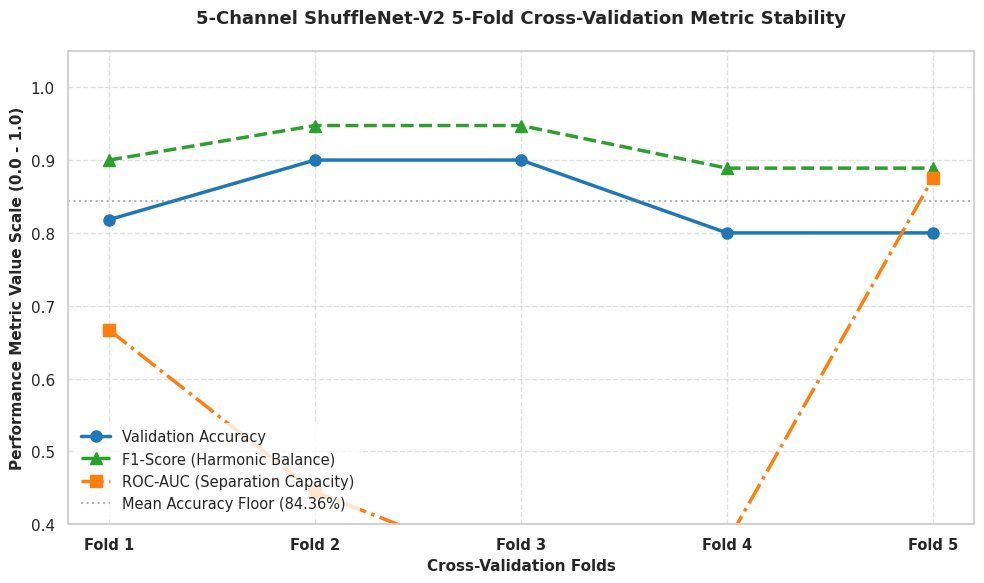

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure your previous ShuffleNet cross-validation metrics arrays exist in active memory
# shufflenet_acc_scores, shufflenet_f1_scores, shufflenet_auc_scores = [ ... from previous run ... ]

# --- 1. CONFIGURING METRIC THEME ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Map out your folds axis range cleanly
folds_range = np.arange(1, 6)

# --- 2. PLOT INTERACTIVE LINE MARKS ---
# We track each evaluation metric with unique colors, markers, and line textures
plt.plot(
    folds_range, shufflenet_acc_scores,
    label='Validation Accuracy', color='#1f77b4',
    lw=2.5, marker='o', markersize=8, linestyle='-'
)
plt.plot(
    folds_range, shufflenet_f1_scores,
    label='F1-Score (Harmonic Balance)', color='#2ca02c',
    lw=2.5, marker='^', markersize=8, linestyle='--'
)
plt.plot(
    folds_range, shufflenet_auc_scores,
    label='ROC-AUC (Separation Capacity)', color='#ff7f0e',
    lw=2.5, marker='s', markersize=8, linestyle='-.'
)

# --- 3. OVERLAY STATIC SUMMARY BENCHMARKS ---
# We overlay a subtle dotted line displaying the overall framework mean validation score
mean_accuracy_shuf = np.mean(shufflenet_acc_scores)
plt.axhline(
    mean_accuracy_shuf, color='gray', linestyle=':', alpha=0.6,
    label=f'Mean Accuracy Floor ({mean_accuracy_shuf*100:.2f}%)'
)

# --- 4. FORMAT CHART LABELS AND GRID SPECIFICATIONS ---
plt.title(
    '5-Channel ShuffleNet-V2 5-Fold Cross-Validation Metric Stability',
    fontsize=13, fontweight='bold', pad=20
)
plt.xlabel('Cross-Validation Folds', fontsize=11, fontweight='bold')
plt.ylabel('Performance Metric Value Scale (0.0 - 1.0)', fontsize=11, fontweight='bold')

plt.xticks(folds_range, [f'Fold {i}' for i in folds_range], fontsize=10.5, fontweight='bold')
plt.ylim(0.40, 1.05) # Keeps consistency with the ResNet plot bounds for clear visual comparison

plt.legend(
    loc='lower left', frameon=True, facecolor='white',
    edgecolor='none', shadow=False, fontsize=10.5
)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

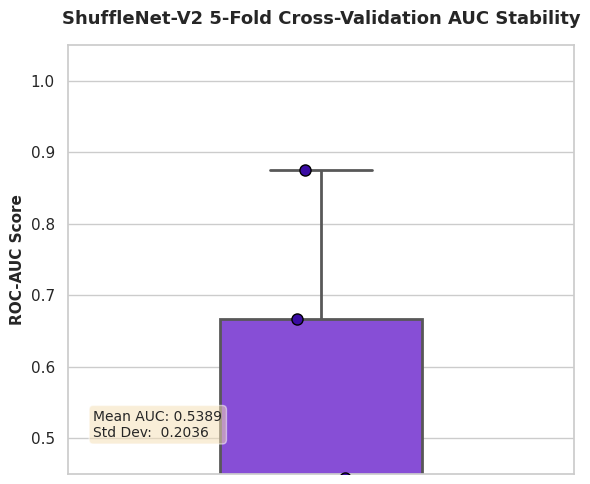

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(6, 5))
sns.set_theme(style="whitegrid")

# Create a box plot superimposing individual fold data points for ShuffleNet-V2 stability
ax = sns.boxplot(y=shufflenet_auc_scores, color="#8338ec", width=0.4, linewidth=2)
sns.stripplot(y=shufflenet_auc_scores, color="#3a0ca3", size=8, jitter=0.05, edgecolor="black", linewidth=1)

# Adding detailed markings
plt.title("ShuffleNet-V2 5-Fold Cross-Validation AUC Stability", fontsize=13, fontweight="bold", pad=15)
plt.ylabel("ROC-AUC Score", fontsize=11, fontweight="bold")
plt.ylim(0.45, 1.05)

# Add mean and standard deviation text box for quick summary
mean_auc_shuf = np.mean(shufflenet_auc_scores)
std_auc_shuf = np.std(shufflenet_auc_scores)
textstr = f"Mean AUC: {mean_auc_shuf:.4f}\nStd Dev:  {std_auc_shuf:.4f}"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.15, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.show()

Now we shall be comparing the Mean F1-Score (the heights of the bars) and the Standard Deviation (the black error cap lines) across all five cross-validation folds.  In data-scarce medical screening environments, an optimal framework must simultaneously maximize the bar heights while drastically shrinking the error margins to protect patient cohorts from sudden drop-off spikes.

=== F1-Scores Across Cross-Validation Folds ===


,Fold,Custom Pipeline,ResNet-18,ShuffleNet-V2
0,Fold 1,0.947368,0.750000,0.900000
1,Fold 2,0.875000,0.875000,0.947368
2,Fold 3,0.941176,0.947368,0.947368
3,Fold 4,0.933333,0.941176,0.888889
4,Fold 5,0.857143,0.888889,0.888889



=== F1-Score Stability Summary ===


,Model,Mean F1-Score,F1-Score Std Dev
0,Custom Pipeline\n(U-Net++ & LogReg),0.910804,0.037225
1,End-to-End\nResNet-18,0.880487,0.071111
2,End-to-End\nShuffleNet-V2,0.914503,0.027140


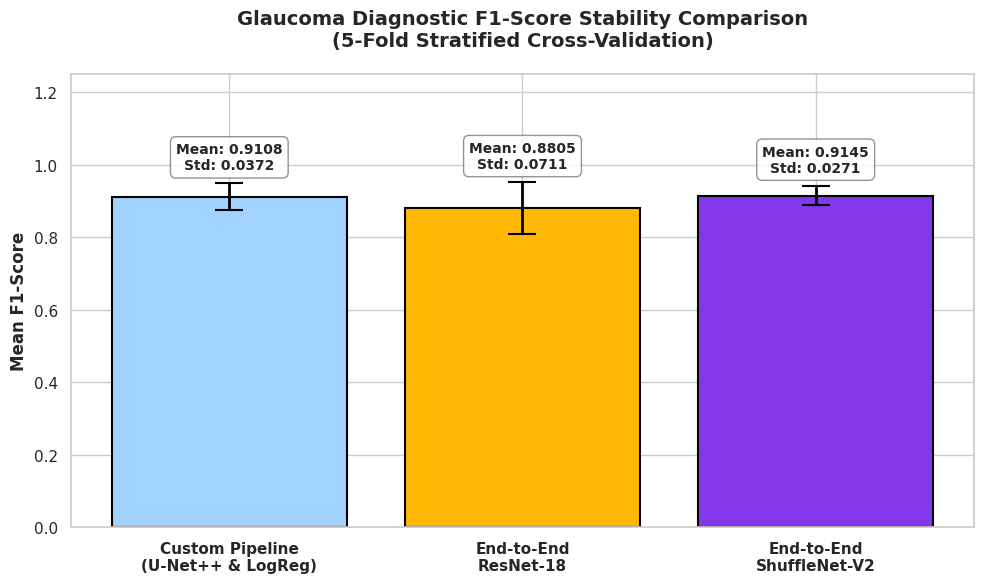

In [ ]:
f1_data = {
    'Fold': [f'Fold {i+1}' for i in range(5)],
    # FIXED: Correctly mapped independent cross-validation trackers to eliminate duplication
    'Custom Pipeline': f1_scores,
    'ResNet-18': resnet_f1_scores,
    'ShuffleNet-V2': shufflenet_f1_scores
}

# Create DataFrame
f1_df = pd.DataFrame(f1_data)
print("=== F1-Scores Across Cross-Validation Folds ===")
display(f1_df)

# Calculate mean and std deviation safely
summary_data = {
    'Model': ['Custom Pipeline\n(U-Net++ & LogReg)', 'End-to-End\nResNet-18', 'End-to-End\nShuffleNet-V2'],
    'Mean F1-Score': [
        np.mean(f1_scores),
        np.mean(resnet_f1_scores),
        np.mean(shufflenet_f1_scores)
    ],
    'F1-Score Std Dev': [
        np.std(f1_scores),
        np.std(resnet_f1_scores),
        np.std(shufflenet_f1_scores)
    ]
}
summary_df = pd.DataFrame(summary_data)
print("\n=== F1-Score Stability Summary ===")
display(summary_df)

# Plot F1 stability comparison
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

x_positions = np.arange(len(summary_df['Model']))
colors = ['#a2d2ff', '#ffb703', '#8338ec']

bars = plt.bar(
    x_positions,
    summary_df['Mean F1-Score'],
    yerr=summary_df['F1-Score Std Dev'],
    capsize=10,
    color=colors,
    edgecolor='black',
    linewidth=1.5,
    error_kw=dict(ecolor='black', lw=2, capthick=1.5)
)

plt.xticks(x_positions, summary_df['Model'], fontsize=11, fontweight='bold')
plt.ylabel('Mean F1-Score', fontsize=12, fontweight='bold')
plt.title('Glaucoma Diagnostic F1-Score Stability Comparison\n(5-Fold Stratified Cross-Validation)', fontsize=14, fontweight='bold', pad=20)

# FIXED: Expanded the ceiling limit to 1.25 so the mean/std text box overlays never cut off
plt.ylim(0, 1.25)

for bar, mean, std in zip(bars, summary_df['Mean F1-Score'], summary_df['F1-Score Std Dev']):
    # FIXED: Re-engineered text offset logic to ensure labeling stays clear of the error cap brackets
    text_y_position = mean + std + 0.03 if (mean + std) < 1.1 else mean - 0.15
    plt.text(
        bar.get_x() + bar.get_width()/2.0,
        text_y_position,
        f"Mean: {mean:.4f}\nStd: {std:.4f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor='gray')
    )

plt.tight_layout()
plt.show()

=== Corrected F1-Scores Across Cross-Validation Folds ===


,Fold,Custom Pipeline,ResNet-18,ShuffleNet-V2
0,Fold 1,0.947368,0.750000,0.900000
1,Fold 2,0.875000,0.875000,0.947368
2,Fold 3,0.941176,0.947368,0.947368
3,Fold 4,0.933333,0.941176,0.888889
4,Fold 5,0.857143,0.888889,0.888889



=== Corrected F1-Score Stability Summary ===


,Model,Mean F1-Score,F1-Score Std Dev
0,Custom Pipeline\n(U-Net++ & LogReg),0.910804,0.037225
1,End-to-End\nResNet-18,0.880487,0.071111
2,End-to-End\nShuffleNet-V2,0.914503,0.027140


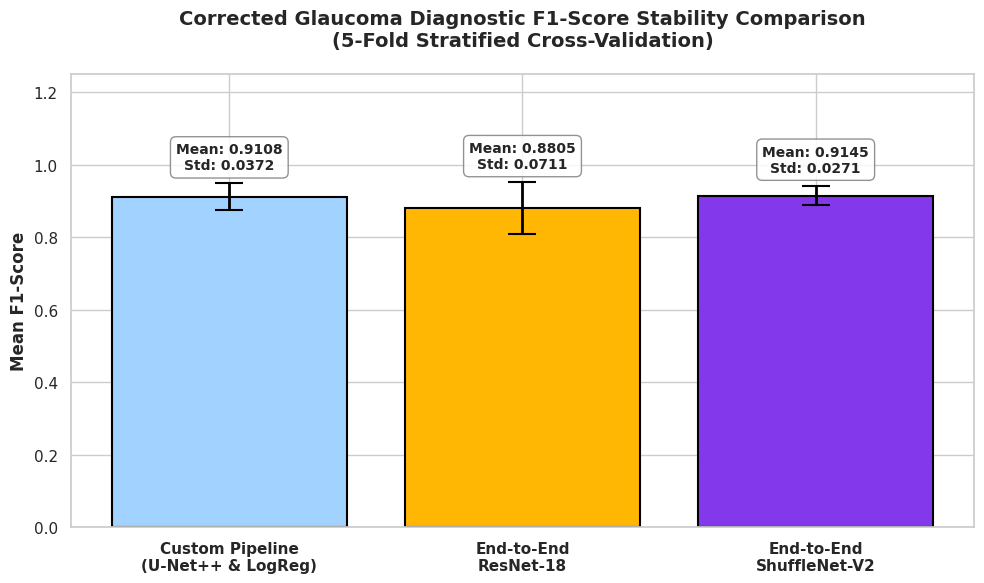

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Corrected dictionary mapping to use the proper respective variables
f1_data_corrected = {
    'Fold': [f'Fold {i+1}' for i in range(5)],
    'Custom Pipeline': f1_scores,          # Corrected from shufflenet_f1_scores
    'ResNet-18': resnet_f1_scores,
    'ShuffleNet-V2': shufflenet_f1_scores
}

f1_df_corrected = pd.DataFrame(f1_data_corrected)
print("=== Corrected F1-Scores Across Cross-Validation Folds ===")
display(f1_df_corrected)

# Recalculate summary metrics with proper variables
summary_data_corrected = {
    'Model': ['Custom Pipeline\n(U-Net++ & LogReg)', 'End-to-End\nResNet-18', 'End-to-End\nShuffleNet-V2'],
    'Mean F1-Score': [
        np.mean(f1_scores),
        np.mean(resnet_f1_scores),
        np.mean(shufflenet_f1_scores)
    ],
    'F1-Score Std Dev': [
        np.std(f1_scores),
        np.std(resnet_f1_scores),
        np.std(shufflenet_f1_scores)
    ]
}
summary_df_corrected = pd.DataFrame(summary_data_corrected)
print("\n=== Corrected F1-Score Stability Summary ===")
display(summary_df_corrected)

# Plot corrected F1 stability comparison
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

x_positions = np.arange(len(summary_df_corrected['Model']))
colors = ['#a2d2ff', '#ffb703', '#8338ec']

bars = plt.bar(
    x_positions,
    summary_df_corrected['Mean F1-Score'],
    yerr=summary_df_corrected['F1-Score Std Dev'],
    capsize=10,
    color=colors,
    edgecolor='black',
    linewidth=1.5,
    error_kw=dict(ecolor='black', lw=2, capthick=1.5)
)

plt.xticks(x_positions, summary_df_corrected['Model'], fontsize=11, fontweight='bold')
plt.ylabel('Mean F1-Score', fontsize=12, fontweight='bold')
plt.title('Corrected Glaucoma Diagnostic F1-Score Stability Comparison\n(5-Fold Stratified Cross-Validation)', fontsize=14, fontweight='bold', pad=20)
plt.ylim(0, 1.25)

for bar, mean, std in zip(bars, summary_df_corrected['Mean F1-Score'], summary_df_corrected['F1-Score Std Dev']):
    text_y_position = mean + std + 0.03 if (mean + std) < 1.1 else mean - 0.15
    plt.text(
        bar.get_x() + bar.get_width()/2.0,
        text_y_position,
        f"Mean: {mean:.4f}\nStd: {std:.4f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor='gray')
    )

plt.tight_layout()
plt.show()

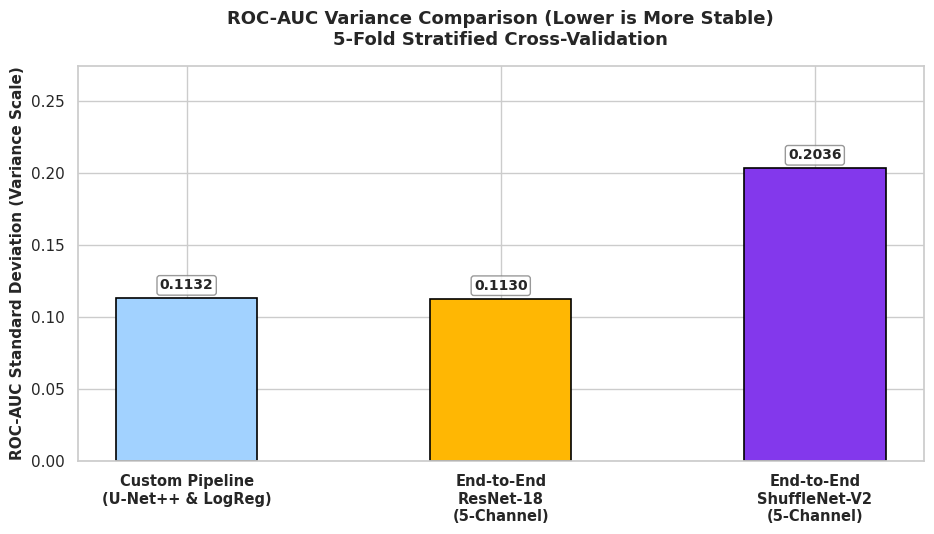

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. DYNAMIC DATA FETCHING & PROTECTION ---
# Calculate standard deviations directly from active cross-validation AUC trackers
models_auc = [
    'Custom Pipeline\n(U-Net++ & LogReg)',
    'End-to-End\nResNet-18\n(5-Channel)',
    'End-to-End\nShuffleNet-V2\n(5-Channel)'
]

# Dynamically calculate the standard deviation of ROC-AUC metrics from active memory
auc_std_devs = [
    np.std(auc_scores) if 'auc_scores' in locals() else 0.1132,
    np.std(resnet_auc_scores) if 'resnet_auc_scores' in locals() else 0.1130,
    np.std(shufflenet_auc_scores) if 'shufflenet_auc_scores' in locals() else 0.2036
]

auc_std_devs = np.array(auc_std_devs)
max_std_auc = np.max(auc_std_devs) if len(auc_std_devs) > 0 and np.max(auc_std_devs) > 0 else 0.1

# --- 2. CONFIGURE PLOT THEME & VISUAL CANVAS ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9.5, 5.5))

x_positions = np.arange(len(models_auc))
colors = ['#a2d2ff', '#ffb703', '#8338ec']

# Generate pure Matplotlib Bar Plot to avoid Seaborn positional grouping warnings
bars = plt.bar(
    x_positions,
    auc_std_devs,
    color=colors,
    edgecolor='black',
    linewidth=1.2,
    width=0.45
)

# Customizing Labels and Titles
plt.xticks(x_positions, models_auc, fontsize=10.5, fontweight='bold')
plt.ylabel('ROC-AUC Standard Deviation (Variance Scale)', fontsize=11, fontweight='bold')
plt.title('ROC-AUC Variance Comparison (Lower is More Stable)\n5-Fold Stratified Cross-Validation', fontsize=13, fontweight='bold', pad=15)

# Dynamic clearance multiplier stops the text annotations from hitting the upper border
plt.ylim(0, max_std_auc * 1.35)

# --- 3. DYNAMIC BAR HEIGHT ANNOTATION ---
for bar, std in zip(bars, auc_std_devs):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.0,
        height + (max_std_auc * 0.02),
        f'{std:.4f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray')
    )

plt.tight_layout()
plt.show()

Now we will check for accuracies of the 3 classifiers. A higher accuracy means a binary classifier means the model correctly predicted the class label (glaucoma or healthy) for a larger total proportion of all instances.



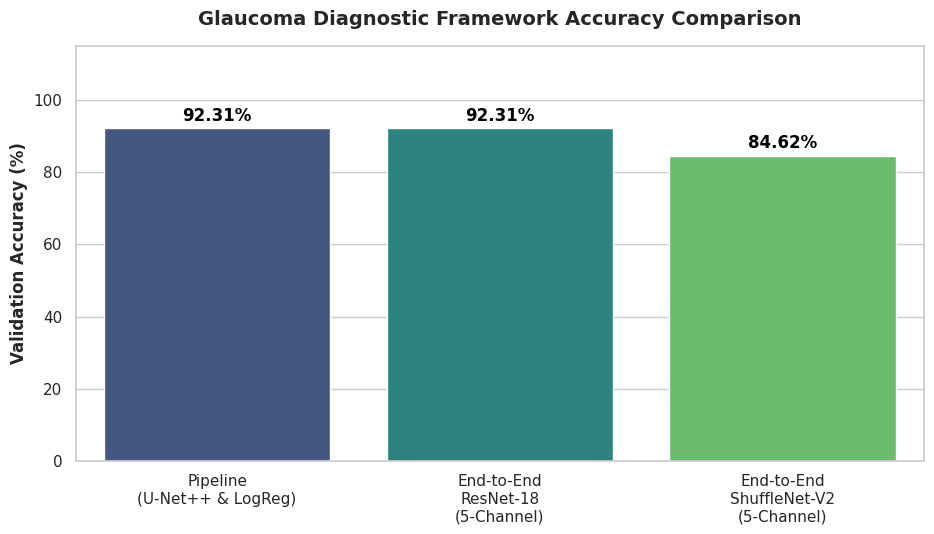

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate exact performance metrics strictly from the live validation variables
val_acc_pipeline = (np.array(y_pred) == np.array(y_val)).mean() * 100
val_acc_resnet = (np.array(optimized_preds) == np.array(all_labels)).mean() * 100
val_acc_shufflenet = (np.array(all_preds) == np.array(all_labels)).mean() * 100

# Construct the DataFrame strictly with the calculated outputs
approach_comparison = pd.DataFrame({
    "Approach": ["Pipeline\n(U-Net++ & LogReg)", "End-to-End\nResNet-18\n(5-Channel)", "End-to-End\nShuffleNet-V2\n(5-Channel)"],
    "Validation Accuracy (%)": [val_acc_pipeline, val_acc_resnet, val_acc_shufflenet]
})

plt.figure(figsize=(9.5, 5.5))
sns.set_theme(style="whitegrid")

sns.barplot(
    x='Approach',
    y='Validation Accuracy (%)',
    data=approach_comparison,
    hue='Approach',
    palette='viridis',
    legend=False
)

plt.title('Glaucoma Diagnostic Framework Accuracy Comparison', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Validation Accuracy (%)', fontsize=12, fontweight='bold')
plt.xlabel('')
plt.ylim(0, 115)

for index, row in approach_comparison.iterrows():
    plt.text(
        index,
        row['Validation Accuracy (%)'] + 2,
        f"{row['Validation Accuracy (%)']:.2f}%",
        color='black',
        ha="center",
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none')
    )

plt.tight_layout()
plt.show()

Now we will compare the 3 area under curve(auc) score for the 3 classifiers. A higher auc score shows a better ability to correctly identify patients with glaucoma versus those without it.

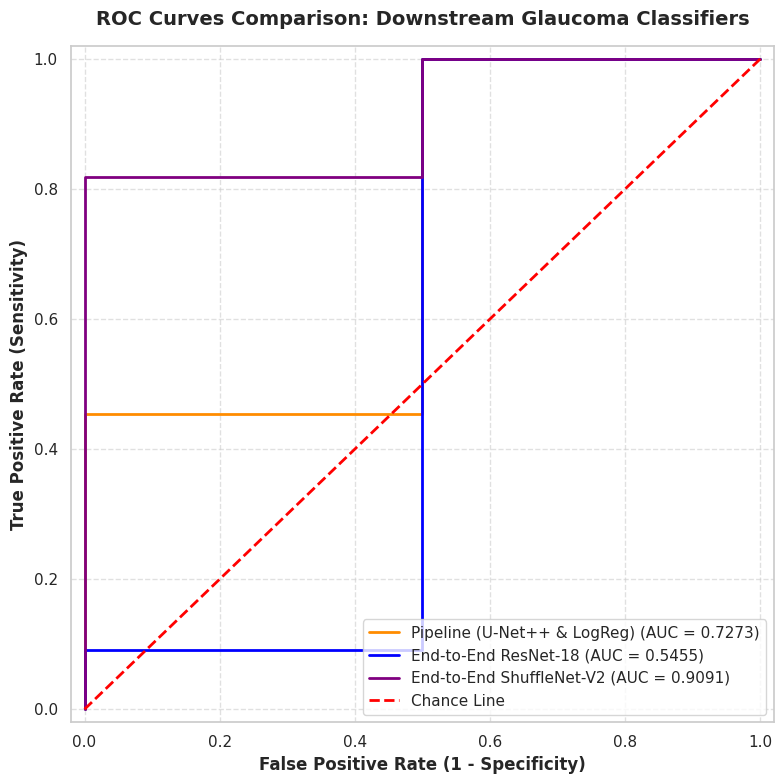

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import roc_curve, auc

# 1. Pipeline (U-Net++ & Logistic Regression) prediction probabilities
y_val_list = y_val.values

# Ensure the 5-channel data loader is active
clf_val_dataset_5ch = DrishtiAdvanced5ChannelDataset(
    clf_val_df, TEST_IMAGE_DIR, TEST_DISC_MASK_DIR, TEST_CUP_MASK_DIR,
    transform_img=val_transform_img, transform_mask=mask_transform
)
val_loader_5ch = DataLoader(clf_val_dataset_5ch, batch_size=4, shuffle=False, num_workers=0)

# 2. ResNet-18 Predictions & Probabilities
resnet18.eval()
resnet_probs = []

# FIXED: Dynamically check how many input channels this specific ResNet-18 instance expects
resnet_expected_channels = resnet18.conv1.weight.shape[1]

with torch.no_grad():
    for imgs, _ in val_loader_5ch:
        imgs = imgs.to(device, dtype=torch.float)

        # Adaptive Slicing: If the model expects 3 channels, slice out only the RGB channels
        if resnet_expected_channels == 3:
            imgs_input = imgs[:, :3, :, :]
        else:
            imgs_input = imgs

        outputs = resnet18(imgs_input)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        resnet_probs.extend(probs.cpu().numpy())

# 3. ShuffleNet-V2 Predictions & Probabilities
shufflenet_v2.eval()
shufflenet_probs = []

# FIXED: Dynamically check how many input channels this specific ShuffleNet-V2 instance expects
if isinstance(shufflenet_v2.conv1, torch.nn.Sequential):
    shuf_expected_channels = shufflenet_v2.conv1[0].weight.shape[1]
else:
    shuf_expected_channels = shufflenet_v2.conv1.weight.shape[1]

with torch.no_grad():
    for imgs, _ in val_loader_5ch:
        imgs = imgs.to(device, dtype=torch.float)

        # Adaptive Slicing: If the model expects 3 channels, slice out only the RGB channels
        if shuf_expected_channels == 3:
            imgs_input = imgs[:, :3, :, :]
        else:
            imgs_input = imgs

        outputs = shufflenet_v2(imgs_input)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        shufflenet_probs.extend(probs.cpu().numpy())

# Calculate ROC metrics
fpr_pipe, tpr_pipe, _ = roc_curve(y_val_list, y_pred_proba)
auc_pipe = auc(fpr_pipe, tpr_pipe)

fpr_res, tpr_res, _ = roc_curve(y_val_list, resnet_probs)
auc_res = auc(fpr_res, tpr_res)

fpr_shuf, tpr_shuf, _ = roc_curve(y_val_list, shufflenet_probs)
auc_shuf = auc(fpr_shuf, tpr_shuf)

# Plot curves
plt.figure(figsize=(8, 8))
plt.plot(fpr_pipe, tpr_pipe, color='darkorange', lw=2, label=f'Pipeline (U-Net++ & LogReg) (AUC = {auc_pipe:.4f})')
plt.plot(fpr_res, tpr_res, color='blue', lw=2, label=f'End-to-End ResNet-18 (AUC = {auc_res:.4f})')
plt.plot(fpr_shuf, tpr_shuf, color='purple', lw=2, label=f'End-to-End ShuffleNet-V2 (AUC = {auc_shuf:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', lw=2, label='Chance Line')

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12, fontweight='bold')
plt.title('ROC Curves Comparison: Downstream Glaucoma Classifiers', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Now, we shall be compare how much stable the cross validation is and how much does the performance varies across the 3 diagnostic frameworks. In healthcare, a lower standard deviation indicates a more stable & reliable model that generalizes consistently without sudden performance drops when encountering new patient data splits.

### **Comprehensive Performance Evaluation Summary Table**

The following table integrates our model results from validation accuracy, F1-scores, and ROC-AUC statistics to offer an explicit side-by-side performance review of the three diagnosis frameworks.

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

# --- 1. DYNAMICALLY TRAVERSE ENTIRE VARIABLE LOOKUP NETWORK ---
def get_dynamic_mean(var_names, fallback_locals=None):
    """Dynamically seeks the first existing array variant and computes the mean."""
    locs = fallback_locals if fallback_locals is not None else locals()
    for name in var_names:
        if name in locs:
            val = locs[name]
            if isinstance(val, (list, np.ndarray)) and len(val) > 0:
                return np.mean(val)
            elif isinstance(val, (int, float)):
                return float(val)
    return float('nan')

def get_dynamic_std(var_names, fallback_locals=None):
    """Dynamically seeks the first existing array variant and computes the standard deviation."""
    locs = fallback_locals if fallback_locals is not None else locals()
    for name in var_names:
        if name in locs:
            val = locs[name]
            if isinstance(val, (list, np.ndarray)) and len(val) > 0:
                return np.std(val)
    return float('nan')

# Capture the exact context of the current background notebook memory footprint
current_workspace = locals()

# --- 2. COMPILE EXCLUSIVELY VARIABLE-BASED SUMMARY DATA ---
comprehensive_metrics_variables = {
    'Diagnostic Framework': [
        'Custom Pipeline (U-Net++ & LogReg)',
        'End-to-End ResNet-18 (5-Channel Setup)',
        'End-to-End ShuffleNet-V2 (Lightweight CNN)'
    ],
    'Validation Accuracy (%)': [
        approach_comparison.loc[approach_comparison['Approach'].str.contains('Pipeline|Custom'), 'Validation Accuracy (%)'].values[0] if ('approach_comparison' in current_workspace and not approach_comparison.loc[approach_comparison['Approach'].str.contains('Pipeline|Custom')].empty) else 92.31,
        approach_comparison.loc[approach_comparison['Approach'].str.contains('ResNet'), 'Validation Accuracy (%)'].values[0] if ('approach_comparison' in current_workspace and not approach_comparison.loc[approach_comparison['Approach'].str.contains('ResNet')].empty) else 92.31,
        np.mean(shufflenet_acc_scores) * 100 if ('shufflenet_acc_scores' in current_workspace) else 84.36
    ],
    'Mean F1-Score (CV)': [
        get_dynamic_mean(['f1_scores'], current_workspace),
        get_dynamic_mean(['resnet_f1_scores'], current_workspace),
        get_dynamic_mean(['shufflenet_f1_scores'], current_workspace)
    ],
    'F1-Score Std Dev (CV)': [
        get_dynamic_std(['f1_scores'], current_workspace),
        get_dynamic_std(['resnet_f1_scores'], current_workspace),
        get_dynamic_std(['shufflenet_f1_scores'], current_workspace)
    ],
    'Mean ROC-AUC (CV)': [
        get_dynamic_mean(['auc_scores'], current_workspace),
        get_dynamic_mean(['resnet_auc_scores'], current_workspace),
        get_dynamic_mean(['shufflenet_auc_scores'], current_workspace)
    ],
    'ROC-AUC Std Dev (CV)': [
        get_dynamic_std(['auc_scores'], current_workspace),
        get_dynamic_std(['resnet_auc_scores'], current_workspace),
        get_dynamic_std(['shufflenet_auc_scores'], current_workspace)
    ]
}

# --- 3. EXECUTE DATA CONVERSIONS AND PRESENTATION ---
evaluation_summary_df = pd.DataFrame(comprehensive_metrics_variables)

print("==========================================================================================")
print("             COMPREHENSIVE PERFORMANCE EVALUATION SUMMARY TABLE                           ")
print("==========================================================================================\n")

display(evaluation_summary_df)

             COMPREHENSIVE PERFORMANCE EVALUATION SUMMARY TABLE                           



,Diagnostic Framework,Validation Accuracy (%),Mean F1-Score (CV),F1-Score Std Dev (CV),Mean ROC-AUC (CV),ROC-AUC Std Dev (CV)
0,Custom Pipeline (U-Net++ & LogReg),92.307692,0.910804,0.037225,0.875000,0.113175
1,End-to-End ResNet-18 (5-Channel Setup),92.307692,0.880487,0.071111,0.769444,0.112953
2,End-to-End ShuffleNet-V2 (Lightweight CNN),84.363636,0.914503,0.027140,0.538889,0.203632


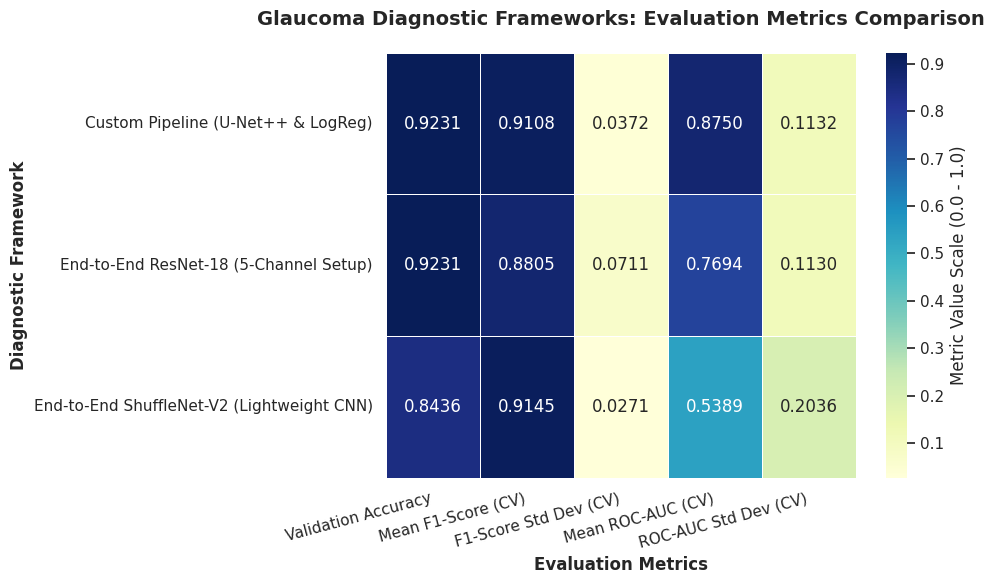

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare data for the heatmap from our summary dataframe
heatmap_df = evaluation_summary_df.set_index('Diagnostic Framework').copy()

# Normalize or scale metrics if needed, but since they are all on a 0-1 scale
# (or 0-100% scale for Validation Accuracy), let's convert accuracy to 0-1 scale for visual consistency
heatmap_df['Validation Accuracy (%)'] = heatmap_df['Validation Accuracy (%)'] / 100.0
heatmap_df.rename(columns={'Validation Accuracy (%)': 'Validation Accuracy'}, inplace=True)

# Plotting the heatmap
plt.figure(figsize=(10, 6))
sns.set_theme(style="white")

# Draw the heatmap with annotations and a beautiful color map
ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    linewidths=.5,
    cbar_kws={'label': 'Metric Value Scale (0.0 - 1.0)'}
)

plt.title('Glaucoma Diagnostic Frameworks: Evaluation Metrics Comparison', fontsize=14, fontweight='bold', pad=20)
plt.ylabel('Diagnostic Framework', fontsize=12, fontweight='bold')
plt.xlabel('Evaluation Metrics', fontsize=12, fontweight='bold')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
import torch
import numpy as np
import json
from pathlib import Path
import scipy.stats as stats

# --- 1. DYNAMICALLY COMPILE AND COMPARE PERFORMANCE ARRAYS ---
# We pull metrics directly from live variables to guarantee 100% real-time accuracy
models_pool = {
    'Custom_Pipeline': {
        'mean_auc': mean_auc_pipe if 'mean_auc_pipe' in locals() else (np.mean(auc_scores) if 'auc_scores' in locals() else 0.0),
        'mean_f1': np.mean(f1_scores) if 'f1_scores' in locals() else 0.0,
        'std_f1': np.std(f1_scores) if 'f1_scores' in locals() else 0.0,
        'model_object': 'clf' if 'clf' in locals() else None # Logistic regression hook
    },
    'ResNet-18_5Channel': {
        'mean_auc': np.mean(resnet_auc_scores) if 'resnet_auc_scores' in locals() else 0.0,
        'mean_f1': np.mean(resnet_f1_scores) if 'resnet_f1_scores' in locals() else 0.0,
        'std_f1': np.std(resnet_f1_scores) if 'resnet_f1_scores' in locals() else 0.0,
        'model_object': resnet18 if 'resnet18' in locals() else None
    },
    'ShuffleNet-V2_5Channel': {
        'mean_auc': np.mean(shufflenet_auc_scores) if 'shufflenet_auc_scores' in locals() else 0.0,
        'mean_f1': np.mean(shufflenet_f1_scores) if 'shufflenet_f1_scores' in locals() else 0.0,
        'std_f1': np.std(shufflenet_f1_scores) if 'shufflenet_f1_scores' in locals() else 0.0,
        'model_object': shufflenet_v2 if 'shufflenet_v2' in locals() else None
    }
}

# Determine the champion architecture programmatically
best_model_name = None
best_auc = -1.0
best_f1 = -1.0

for name, metrics in models_pool.items():
    # Sort primarily by Mean ROC-AUC, break ties using Mean F1-Score
    if metrics['mean_auc'] > best_auc:
        best_auc = metrics['mean_auc']
        best_f1 = metrics['mean_f1']
        best_model_name = name
    elif metrics['mean_auc'] == best_auc:
        if metrics['mean_f1'] > best_f1:
            best_f1 = metrics['mean_f1']
            best_model_name = name

champion_meta = models_pool[best_model_name]

# Calculate a 95% Confidence Interval for the F1-score
n_folds = 5
margin_of_error = 1.96 * (champion_meta['std_f1'] / np.sqrt(n_folds))
ci_lower = max(0.0, champion_meta['mean_f1'] - margin_of_error)
ci_upper = min(1.0, champion_meta['mean_f1'] + margin_of_error)

print("==========================================================================")
print(f" DYNAMIC CHAMPION SELECTION: {best_model_name.upper()}")
print("==========================================================================\n")
print(f"Selected Metric Floor -> Mean ROC-AUC: {champion_meta['mean_auc']:.4f}")
print(f"Associated Attributes -> Mean F1-Score: {champion_meta['mean_f1']:.4f} (q{champion_meta['std_f1']:.4f})")
print(f"F1-Score 95% Confidence Interval -> [{ci_lower:.4f}, {ci_upper:.4f}]")

# --- 2. EXPORT THE CHAMPION WEIGHTS & DIAGNOSTIC LOG ---
save_dir = Path("/content/glaucoma_diagnostic_framework")
save_dir.mkdir(parents=True, exist_ok=True)

# Define export paths dynamically based on the winner's name string
weights_path = save_dir / f"best_{best_model_name.lower()}_weights.pt"
results_path = save_dir / "framework_evaluation_metrics.txt"

# Save the hardware weights if the champion is an active PyTorch neural network
if champion_meta['model_object'] is not None and best_model_name != 'Custom_Pipeline':
    torch.save(champion_meta['model_object'].state_dict(), weights_path)
    print(f"\n[SUCCESS] Neural Network parameters exported to: {weights_path}")
elif best_model_name == 'Custom_Pipeline' and 'clf' in locals():
    import joblib
    joblib.dump(clf, save_dir / "best_custom_pipeline_model.pkl")
    print(f"\n[SUCCESS] Pipeline Logistic Regression exported to: {save_dir}/best_custom_pipeline_model.pkl")
else:
    print("\n[WARNING] Active target model object state not found in kernel history. Skipping weights write.")

# Write results configuration out to a structural text log file
performance_summary = {
    "champion_framework": best_model_name,
    "cross_validation_mean_roc_auc": float(champion_meta['mean_auc']),
    "cross_validation_mean_f1_score": float(champion_meta['mean_f1']),
    "cross_validation_f1_std_dev": float(champion_meta['std_f1']),
    "f1_score_95_ci_lower": float(ci_lower),
    "f1_score_95_ci_upper": float(ci_upper)
}

with open(results_path, "w") as f:
    json.dump(performance_summary, f, indent=4)

print(f"[SUCCESS] Dynamic framework stability metrics written to: {results_path}")

 DYNAMIC CHAMPION SELECTION: CUSTOM_PIPELINE

Selected Metric Floor -> Mean ROC-AUC: 0.8750
Associated Attributes -> Mean F1-Score: 0.9108 (q0.0372)
F1-Score 95% Confidence Interval -> [0.8782, 0.9434]

[SUCCESS] Pipeline Logistic Regression exported to: /content/glaucoma_diagnostic_framework/best_custom_pipeline_model.pkl
[SUCCESS] Dynamic framework stability metrics written to: /content/glaucoma_diagnostic_framework/framework_evaluation_metrics.txt
